In [1]:
library(DESeq2)
library(RColorBrewer)
library(reshape2)
library("gplots")
library("GGally")                      # Load GGally package
library(goseq)
library(readxl)
library(tidyverse)
library("pheatmap")
library(corrplot)
library(circlize)

Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: 'BiocGenerics'


The following objects are masked from 'package:stats':

    IQR, mad, sd, var, xtabs


The following objects are masked from 'package:base':

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, sort,
    table, tapply, union, unique, unsplit, which.max, which.min



Attaching package: 'S4Vectors'


The following objects are masked from 'package:base':

    expand.grid, I, unname


Loading required package: IRanges


Attaching package: 'IRanges'


The following object is masked from 'package:grDevices':

    windows


Loading required package: GenomicRanges

Loading req

In [2]:
library(ComplexUpset)

In [3]:
library(ggrepel)

In [4]:
library(ComplexHeatmap)

Loading required package: grid

ComplexHeatmap version 2.14.0
Bioconductor page: http://bioconductor.org/packages/ComplexHeatmap/
Github page: https://github.com/jokergoo/ComplexHeatmap
Documentation: http://jokergoo.github.io/ComplexHeatmap-reference

If you use it in published research, please cite either one:
- Gu, Z. Complex Heatmap Visualization. iMeta 2022.
- Gu, Z. Complex heatmaps reveal patterns and correlations in multidimensional 
    genomic data. Bioinformatics 2016.


The new InteractiveComplexHeatmap package can directly export static 
complex heatmaps into an interactive Shiny app with zero effort. Have a try!

This message can be suppressed by:
  suppressPackageStartupMessages(library(ComplexHeatmap))
! pheatmap() has been masked by ComplexHeatmap::pheatmap(). Most of the arguments
   in the original pheatmap() are identically supported in the new function. You 
   can still use the original function by explicitly calling pheatmap::pheatmap().



Attaching package: 'Co

In [5]:
options(repr.plot.width = 10, repr.plot.height = 10, repr.plot.res = 300)

In [6]:
hpath_fname = file.path('..', 'genomes', 'HOT1A3', 'HOT1A3_protein_list.csv')
hpath_df = read.csv(hpath_fname)


# Enrichment of differentially expressed proteins and transcripts

Compare DE genes and DE proteins and run enrichment for all

In [7]:
rnaseq_dpath = file.path('..', 'RNASEQ', 'DE_results')
list.files(rnaseq_dpath)


[1] "HOT1A3_DE_DESEQ_longterm_results.csv"       
 [2] "HOT1A3_DE_DESEQ_results.csv"                
 [3] "HOT1A3_DE_DESEQ_results_ref_vs_long.csv"    
 [4] "HOT1A3_DE_DESEQ_vsd.csv"                    
 [5] "HOT1A3_DE_genes_DESEQ_ref_vs_long_wKEGG.csv"
 [6] "HOT1A3_GOSEQ_results_ref_vs_long.csv"       
 [7] "MED4_DE_DESEQ_longterm_results.csv"         
 [8] "MED4_DE_DESEQ_results.csv"                  
 [9] "MED4_DE_DESEQ_results_ref_vs_long.csv"      
[10] "MED4_DE_DESEQ_vsd.csv"                      
[11] "MED4_DE_genes_DESEQ_wKEGG_ref_vs_long.csv"  
[12] "MED4_GOSEQ_results_ref_vs_long.csv"

In [8]:
proteome_dpath = file.path('..', 'Proteome', 'data')
list.files(proteome_dpath)


[1] "A_axenic_proteome.txt"                                                                          
 [2] "A_axenic_proteome_norm.txt"                                                                     
 [3] "ALT_Axenic_DE.csv"                                                                              
 [4] "ALT_CC_DE.csv"                                                                                  
 [5] "C_ALT_proteome.txt"                                                                             
 [6] "C_ALT_proteome_norm.txt"                                                                        
 [7] "C_PRO_proteome.txt"                                                                             
 [8] "C_PRO_proteome_norm.txt"                                                                        
 [9] "Nov22_Processing.xlsx"                                                                          
[10] "P_axenic_proteome.txt"                                                                          
[11] "P_axenic_proteome_norm.txt"                                                                     
[12] "PRO_Axenic_DE.csv"                                                                              
[13] "PRO_CC_DE.csv"                                                                                  
[14] "uniprot-compressed_true_download_true_fields_accession_2Cid_2Cprotei-2023.01.11-12.43.22.99.txt"

In [9]:
df_rnaseq1 = read.csv(file.path(rnaseq_dpath,'HOT1A3_DE_DESEQ_longterm_results.csv'))  %>% 
   mutate(gene_id = str_replace(gene_id, '\\.\\.\\.\\d+', '')) 

df_rnaseq2 = read.csv(file.path(rnaseq_dpath,'HOT1A3_DE_DESEQ_results.csv')) %>% 
   mutate(gene_id = str_replace(gene_id, '\\.\\.\\.\\d+', '')) 

In [10]:
unique(df_rnaseq2$contrast)

[1] "A2vsA1" "A3vsA1" "A3vsA2" "C1vsA1" "C2vsA2" "C3vsA3" "C2vsC1" "C3vsC1"
 [9] "C4vsC1" "C5vsC1" "C3vsC2" "C4vsC3" "C5vsC4"

In [11]:
df_prot1 = read.csv(file.path(proteome_dpath,'ALT_CC_DE.csv'))
df_prot2 = read.csv(file.path(proteome_dpath,'ALT_Axenic_DE.csv'))

In [12]:
names(df_rnaseq1)
names(df_rnaseq2)
names(df_prot1)
names(df_prot2)



[1] "gene_id"        "baseMean"       "log2FoldChange" "lfcSE"         
 [5] "stat"           "pvalue"         "padj"           "contrast"      
 [9] "na_pvalue"      "na_padj"        "significant"    "direction"     
[13] "status"

[1] "gene_id"        "baseMean"       "log2FoldChange" "lfcSE"         
 [5] "stat"           "pvalue"         "padj"           "contrast"      
 [9] "na_pvalue"      "na_padj"        "significant"    "direction"     
[13] "status"

[1] "X"            "logFC"        "AveExpr"      "t"            "P.Value"     
 [6] "adj.P.Val"    "B"            "gene"         "count"        "sca.t"       
[11] "sca.P.Value"  "sca.adj.pval" "contrast"     "log.sca.pval"

[1] "X"            "logFC"        "AveExpr"      "t"            "P.Value"     
 [6] "adj.P.Val"    "B"            "gene"         "count"        "sca.t"       
[11] "sca.P.Value"  "sca.adj.pval" "contrast"     "log.sca.pval"

In [13]:
dp1 = df_prot1 %>%  select(
    'contrast','gene','logFC','AveExpr',
    'sca.P.Value','sca.adj.pval') %>%
    rename('logFC' = 'logFC','AveExpr' = 'AveExpr',
    'pvalue' = 'sca.P.Value','padj' = 'sca.adj.pval', 'protein_id'='gene') %>%
    mutate(Assay = 'Proteome')
dp2 = df_prot2 %>%  select(
    'contrast','gene','logFC','AveExpr',
    'sca.P.Value','sca.adj.pval') %>%
    rename('logFC' = 'logFC','AveExpr' = 'AveExpr',
    'pvalue' = 'sca.P.Value','padj' = 'sca.adj.pval', 'protein_id'='gene')%>%
    mutate(Assay = 'Proteome')


In [14]:
dr1 = df_rnaseq1 %>% 
    select(
        'contrast', 'gene_id','baseMean','log2FoldChange',
        'pvalue','padj',
    ) %>%
    rename('logFC' = 'log2FoldChange','AveExpr' = 'baseMean',
    'pvalue' = 'pvalue','padj' = 'padj') %>%
    mutate(Assay = 'RNA')
dr2 = df_rnaseq2 %>% 
    select(
        'contrast', 'gene_id','baseMean','log2FoldChange',
        'pvalue','padj',
    ) %>%
    rename('logFC' = 'log2FoldChange','AveExpr' = 'baseMean',
    'pvalue' = 'pvalue','padj' = 'padj') %>%
    mutate(Assay = 'RNA')
    


In [15]:
dput(sort(unique(df_prot1$contrast)))
dput(sort(unique(df_prot2$contrast)))
dput(sort(unique(df_rnaseq1$contrast)))
dput(sort(unique(df_rnaseq2$contrast)))


c("C2 - C1", "C3 - C1", "C3 - C2", "C4 - C1", "C4 - C3", "C5 - C1", 
"C5 - C4", "Clongterm - C1", "Clongterm - C2", "Clongterm - C3"
)
c("A2 - A1", "A3 - A1", "A3 - A2", "A5 - A1", "A5 - A3")
c("longtermvsA1", "longtermvsA2", "longtermvsA3", "longtermvsC1", 
"longtermvsC2", "longtermvsC3")
c("A2vsA1", "A3vsA1", "A3vsA2", "C1vsA1", "C2vsA2", "C2vsC1", 
"C3vsA3", "C3vsC1", "C3vsC2", "C4vsC1", "C4vsC3", "C5vsC1", "C5vsC4"
)


In [16]:
lookup <- c(
    "C2 - C1" = 'C2vsC1_prot', 
    "C3 - C1" = 'C3vsC1_prot', 
    "C4 - C1" = 'C4vsC1_prot', 
    "C5 - C1" = 'C5vsC1_prot',

    "C3 - C2" = 'C3vsC2_prot', 
    "C4 - C2" = 'C4vsC2_prot', 
    "C5 - C2" = 'C5vsC2_prot', 

    "C4 - C3" = 'C4vsC3_prot', 
    "C5 - C3" = 'C5vsC3_prot', 
    "C5 - C4" = 'C5vsC4_prot', 

    "Clongterm - C1" = 'LATEvsC1_prot', 
    "Clongterm - C2" = 'LATEvsC2_prot', 
    "Clongterm - C3" = 'LATEvsC3_prot', 

    "A2 - A1" = 'A2vsA1_prot',
    "A3 - A1" = 'A3vsA1_prot',
    "A5 - A1" = 'A5vsA1_prot',
    "A3 - A2" = 'A3vsA2_prot',
    "A5 - A3" = 'A5vsA3_prot',
    "Intercept" = "Intercept",

    "longtermvsA1" = 'LATEvsA1_rna', 
    "longtermvsA2" = 'LATEvsA2_rna', 
    "longtermvsA3" = 'LATEvsA3_rna', 
    "longtermvsC1" = 'LATEvsC1_rna', 
    "longtermvsC2" = 'LATEvsC2_rna', 
    "longtermvsC3" = 'LATEvsC3_rna', 

    "A2vsA1" = 'A2vsA1_rna', 
    "A3vsA1" = 'A3vsA1_rna', 
    "A3vsA2" = 'A3vsA2_rna', 
    "C1vsA1" = 'C1vsA1_rna', 
    "C2vsA2" = 'C2vsA2_rna', 
    "C3vsA3" = 'C3vsA3_rna', 
    "C2vsC1" = 'C2vsC1_rna', 
    "C3vsC1" = 'C3vsC1_rna', 
    "C4vsC1" = 'C4vsC1_rna', 
    "C5vsC1" = 'C5vsC1_rna',
    "C3vsC2" = 'C3vsC2_rna', 
    "C4vsC3" = 'C4vsC3_rna',
    #"C5vsC3" = 'C5vsC3_rna',
    "C5vsC4" = 'C5vsC4_rna'
)
    
    


In [17]:
dr1 = dr1 %>% mutate(contrast1 = lookup[contrast]) %>% filter(contrast != 'Intercept')
dr2 = dr2 %>% mutate(contrast1 = lookup[contrast]) %>% filter(contrast != 'Intercept')
dp1 = dp1 %>% mutate(contrast1 = lookup[contrast]) %>% filter(contrast != 'Intercept')
dp2 = dp2 %>% mutate(contrast1 = lookup[contrast]) %>% filter(contrast != 'Intercept')


In [18]:
names(hpath_df)

[1] "seq_id"             "Name"               "gene"              
 [4] "gene_synonym"       "locus_tag"          "old_locus_tag"     
 [7] "source"             "start"              "end"               
[10] "strand"             "Note"               "exception"         
[13] "inference"          "product"            "protein_id"        
[16] "gene_length"        "path_id"            "main"              
[19] "sub"                "path"               "ecpath"            
[22] "Category"           "Membrane.transport" "kegg_gene1"        
[25] "kegg_gene2"

In [19]:
dp1 = left_join(dp1, hpath_df, by='protein_id') %>% mutate(gene_id = locus_tag)
dp2 = left_join(dp2, hpath_df, by='protein_id') %>% mutate(gene_id = locus_tag)


Warning message in left_join(dp1, hpath_df, by = "protein_id"):
"Each row in `x` is expected to match at most 1 row in `y`.
ℹ Row 1298 of `x` matches multiple rows.
ℹ If multiple matches are expected, set `multiple = "all"` to silence this warning."
Warning message in left_join(dp2, hpath_df, by = "protein_id"):
"Each row in `x` is expected to match at most 1 row in `y`.
ℹ Row 555 of `x` matches multiple rows.
ℹ If multiple matches are expected, set `multiple = "all"` to silence this warning."


In [20]:
names(dp1)# %>% mutate(gene_id = locus_tag)

[1] "contrast"           "protein_id"         "logFC"             
 [4] "AveExpr"            "pvalue"             "padj"              
 [7] "Assay"              "contrast1"          "seq_id"            
[10] "Name"               "gene"               "gene_synonym"      
[13] "locus_tag"          "old_locus_tag"      "source"            
[16] "start"              "end"                "strand"            
[19] "Note"               "exception"          "inference"         
[22] "product"            "gene_length"        "path_id"           
[25] "main"               "sub"                "path"              
[28] "ecpath"             "Category"           "Membrane.transport"
[31] "kegg_gene1"         "kegg_gene2"         "gene_id"

In [21]:
 dr1 = left_join(dr1, hpath_df, by=c('gene_id'='locus_tag'))
 dr2 = left_join(dr2, hpath_df, by=c('gene_id'='locus_tag'))
 


In [22]:
df_all = bind_rows(dp1, dp2, dr1, dr2)

In [23]:
df_all = df_all %>% 
    mutate(
        Category = if_else(is.na(Category), 'Uncharacterized', Category),
        Category = if_else(Category == 'Poorly characterized', 'Uncharacterized', Category)
          )

In [24]:
dput(unique(df_all$contrast))

c("C2 - C1", "C3 - C1", "C4 - C1", "C5 - C1", "C3 - C2", "C4 - C3", 
"C5 - C4", "Clongterm - C1", "Clongterm - C2", "Clongterm - C3", 
"A2 - A1", "A3 - A1", "A5 - A1", "A3 - A2", "A5 - A3", "longtermvsA1", 
"longtermvsA2", "longtermvsA3", "longtermvsC1", "longtermvsC2", 
"longtermvsC3", "A2vsA1", "A3vsA1", "A3vsA2", "C1vsA1", "C2vsA2", 
"C3vsA3", "C2vsC1", "C3vsC1", "C4vsC1", "C5vsC1", "C3vsC2", "C4vsC3", 
"C5vsC4")


In [25]:
df_all %>% count(contrast1, contrast,  .drop = FALSE)


contrast1,contrast,n
<chr>,<chr>,<int>
A2vsA1_prot,A2 - A1,2229
A2vsA1_rna,A2vsA1,4015
A3vsA1_prot,A3 - A1,2229
A3vsA1_rna,A3vsA1,4015
A3vsA2_prot,A3 - A2,2229
A3vsA2_rna,A3vsA2,4015
A5vsA1_prot,A5 - A1,2229
A5vsA3_prot,A5 - A3,2229
C1vsA1_rna,C1vsA1,4015


# GOSEQ

In [26]:
names(df_all)

[1] "contrast"           "protein_id"         "logFC"             
 [4] "AveExpr"            "pvalue"             "padj"              
 [7] "Assay"              "contrast1"          "seq_id"            
[10] "Name"               "gene"               "gene_synonym"      
[13] "locus_tag"          "old_locus_tag"      "source"            
[16] "start"              "end"                "strand"            
[19] "Note"               "exception"          "inference"         
[22] "product"            "gene_length"        "path_id"           
[25] "main"               "sub"                "path"              
[28] "ecpath"             "Category"           "Membrane.transport"
[31] "kegg_gene1"         "kegg_gene2"         "gene_id"

In [27]:
df_all = df_all %>% 
    mutate(
        down = ((logFC < 0) & (padj < 0.05)),
        up   = ((logFC > 0) & (padj < 0.05)),
        is_de   = (padj < 0.05),
)

In [28]:
kegg_fname = file.path('..', 'genomes', 'HOT1A3', 'HOT1A3_pathways_category.csv')
kegg_df = read.csv(kegg_fname)


In [29]:
kegg_df = left_join(kegg_df, hpath_df %>% select(locus_tag, protein_id), 
          by='protein_id', multiple = "all") %>% 
    mutate(gene_id=locus_tag)

In [30]:
t(kegg_df)

protein_id,WP_010179497.1,WP_010179497.1,WP_012516526.1,WP_012516526.1,WP_012516526.1,WP_012516526.1,WP_012516526.1,WP_012516568.1,WP_012516568.1,WP_012516577.1,⋯,WP_232376043.1,WP_232376044.1,WP_232376045.1,WP_232376046.1,WP_232376048.1,WP_232376049.1,WP_232376050.1,WP_232376051.1,WP_232376052.1,WP_232376057.1
path_id,K02946,K02946,K02338,K02338,K02338,K02338,K02338,K05501,K05501,K02913,⋯,K15727,K15727,K15727,K15725,K04655,K04656,K04656,K04656,K04651,K04656
main,09120 Genetic Information Processing,09180 Brite Hierarchies,09120 Genetic Information Processing,09120 Genetic Information Processing,09120 Genetic Information Processing,09180 Brite Hierarchies,09180 Brite Hierarchies,09180 Brite Hierarchies,09180 Brite Hierarchies,09120 Genetic Information Processing,⋯,09180 Brite Hierarchies,09180 Brite Hierarchies,09180 Brite Hierarchies,09180 Brite Hierarchies,09190 Not Included in Pathway or Brite,09190 Not Included in Pathway or Brite,09190 Not Included in Pathway or Brite,09190 Not Included in Pathway or Brite,09180 Brite Hierarchies,09190 Not Included in Pathway or Brite
sub,09122 Translation,09182 Protein families: genetic information processing,09124 Replication and repair,09124 Replication and repair,09124 Replication and repair,09182 Protein families: genetic information processing,09182 Protein families: genetic information processing,09182 Protein families: genetic information processing,09182 Protein families: genetic information processing,09122 Translation,⋯,09183 Protein families: signaling and cellular processes,09183 Protein families: signaling and cellular processes,09183 Protein families: signaling and cellular processes,09183 Protein families: signaling and cellular processes,09192 Unclassified: genetic information processing,09192 Unclassified: genetic information processing,09192 Unclassified: genetic information processing,09192 Unclassified: genetic information processing,09182 Protein families: genetic information processing,09192 Unclassified: genetic information processing
path,03010 Ribosome [PATH:ko03010],03011 Ribosome [BR:ko03011],03030 DNA replication [PATH:ko03030],03430 Mismatch repair [PATH:ko03430],03440 Homologous recombination [PATH:ko03440],03032 DNA replication proteins [BR:ko03032],03400 DNA repair and recombination proteins [BR:ko03400],03000 Transcription factors [BR:ko03000],03036 Chromosome and associated proteins [BR:ko03036],03010 Ribosome [PATH:ko03010],⋯,02000 Transporters [BR:ko02000],02000 Transporters [BR:ko02000],02000 Transporters [BR:ko02000],02000 Transporters [BR:ko02000],99975 Protein processing,99975 Protein processing,99975 Protein processing,99975 Protein processing,03110 Chaperones and folding catalysts [BR:ko03110],99975 Protein processing
ecpath,"K02946 RP-S10, MRPS10, rpsJ; small subunit ribosomal protein S10","K02946 RP-S10, MRPS10, rpsJ; small subunit ribosomal protein S10",K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],"K05501 slmA, ttk; TetR/AcrR family transcriptional regulator","K05501 slmA, ttk; TetR/AcrR family transcriptional regulator","K02913 RP-L33, MRPL33, rpmG; large subunit ribosomal protein L33",⋯,"K15727 czcB, cusB, cnrB; membrane fusion protein, heavy metal efflux system","K15727 czcB, cusB, cnrB; membrane fusion protein, heavy metal efflux system","K15727 czcB, cusB, cnrB; membrane fusion protein, heavy metal efflux system","K15725 czcC, cusC, cnrC; outer membrane protein, heavy metal efflux system",K04655 hypE; hydrogenase expression/formation protein HypE,K04656 hypF; hydrogenase maturation protein HypF,K04656 hypF; hydrogenase maturation protein HypF,K04656 hypF; hydrogenase maturation protein HypF,"K04651 hypA, hybF; hydrogenase nickel incorporation protein HypA/HybF",K04656 hypF; hydrogenase maturation p

In [31]:
ignore_main = c('09160 Human Diseases', 
                '09150 Organismal Systems', 
                #'09190 Not Included in Pathway or Brite', 
                #'09180 Brite Hierarchies',
                ''
               )

In [32]:
run_enrichment <- function(contrastname, encolname, testcolname) {
    #cat_df = path_df %>% select(encolname, main) %>% distinct()    
    print(contrastname)
    print(encolname)
    print(testcolname)
    
    mpath_df = kegg_df %>%
       filter(!main %in% ignore_main)  %>%
       pivot_longer(cols = all_of(encolname), values_to = 'PATH') %>%
       mutate(PATH = word(PATH)) %>%
       distinct(PATH, gene_id, .keep_all= TRUE) %>%
       select(gene_id, PATH)
    test_df = df_all %>% drop_na(padj) %>% filter(contrast1 == contrastname)
    test_df$sigval = if_else(test_df[[testcolname]], 1, 0)
    DEgenes = test_df$sigval
    names(DEgenes) = test_df$gene_id
    #table(DEgenes)
    LENgenes = test_df$gene_length
    names(LENgenes) = test_df$gene_id
    pwf = nullp(DEgenes, bias.data=LENgenes)
    goseq_res = goseq(pwf, gene2cat = as.data.frame(mpath_df))
    goseq_res = goseq_res %>% filter(numInCat>=5) 
    goseq_res$padj = p.adjust(goseq_res$over_represented_pvalue, method="BH")
    goseq_res = goseq_res %>%
       relocate(padj, .after = over_represented_pvalue) #%>%
       #relocate(PATH, .after = category) 
    goseq_res$type = testcolname
    goseq_res$enrich = encolname
    goseq_res$contrast = contrastname
    goseq_res$organism = 'HOT1A3'
    #return(mpath_df)
    return (goseq_res)
}

In [33]:
kegg_df

protein_id,path_id,main,sub,path,ecpath,Category,Membrane.transport,locus_tag,gene_id
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
WP_010179497.1,K02946,09120 Genetic Information Processing,09122 Translation,03010 Ribosome [PATH:ko03010],"K02946 RP-S10, MRPS10, rpsJ; small subunit ribosomal protein S10",Genetic Info,,ACZ81_RS01655,ACZ81_RS01655
WP_010179497.1,K02946,09180 Brite Hierarchies,09182 Protein families: genetic information processing,03011 Ribosome [BR:ko03011],"K02946 RP-S10, MRPS10, rpsJ; small subunit ribosomal protein S10",Genetic Info,,ACZ81_RS01655,ACZ81_RS01655
WP_012516526.1,K02338,09120 Genetic Information Processing,09124 Replication and repair,03030 DNA replication [PATH:ko03030],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],Genetic Info,,ACZ81_RS00010,ACZ81_RS00010
WP_012516526.1,K02338,09120 Genetic Information Processing,09124 Replication and repair,03430 Mismatch repair [PATH:ko03430],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],Genetic Info,,ACZ81_RS00010,ACZ81_RS00010
WP_012516526.1,K02338,09120 Genetic Information Processing,09124 Replication and repair,03440 Homologous recombination [PATH:ko03440],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],Genetic Info,,ACZ81_RS00010,ACZ81_RS00010
WP_012516526.1,K02338,09180 Brite Hierarchies,09182 Protein families: genetic information processing,03032 DNA replication proteins [BR:ko03032],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],Genetic Info,,ACZ81_RS00010,ACZ81_RS00010
WP_012516526.1,K02338,09180 Brite Hierarchies,09182 Protein families: genetic information processing,03400 DNA repair and recombination proteins [BR:ko03400],K02338 dnaN; DNA polymerase III subunit beta [EC:2.7.7.7],Genetic Info,,ACZ81_RS00010,ACZ81_RS00010
WP_012516568.1,K05501,09180 Brite Hierarchies,09182 Protein families: genetic information processing,03000 Transcription factors [BR:ko03000],"K05501 slmA, ttk; TetR/AcrR family transcriptional regulator",Genetic Info,,ACZ81_RS00230,ACZ81_RS00230
WP_012516568.1,K05501,09180 Brite Hierarchies,09182 Protein families: genetic information processing,03036 Chromosome and associated proteins [BR:ko03036],"K05501 slmA, ttk; TetR/AcrR family transcriptional regulator",Genetic Info,,ACZ81_RS00230,ACZ81_RS00230


[1] "C2vsC1_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"
Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C2vsC1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"
Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC1_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


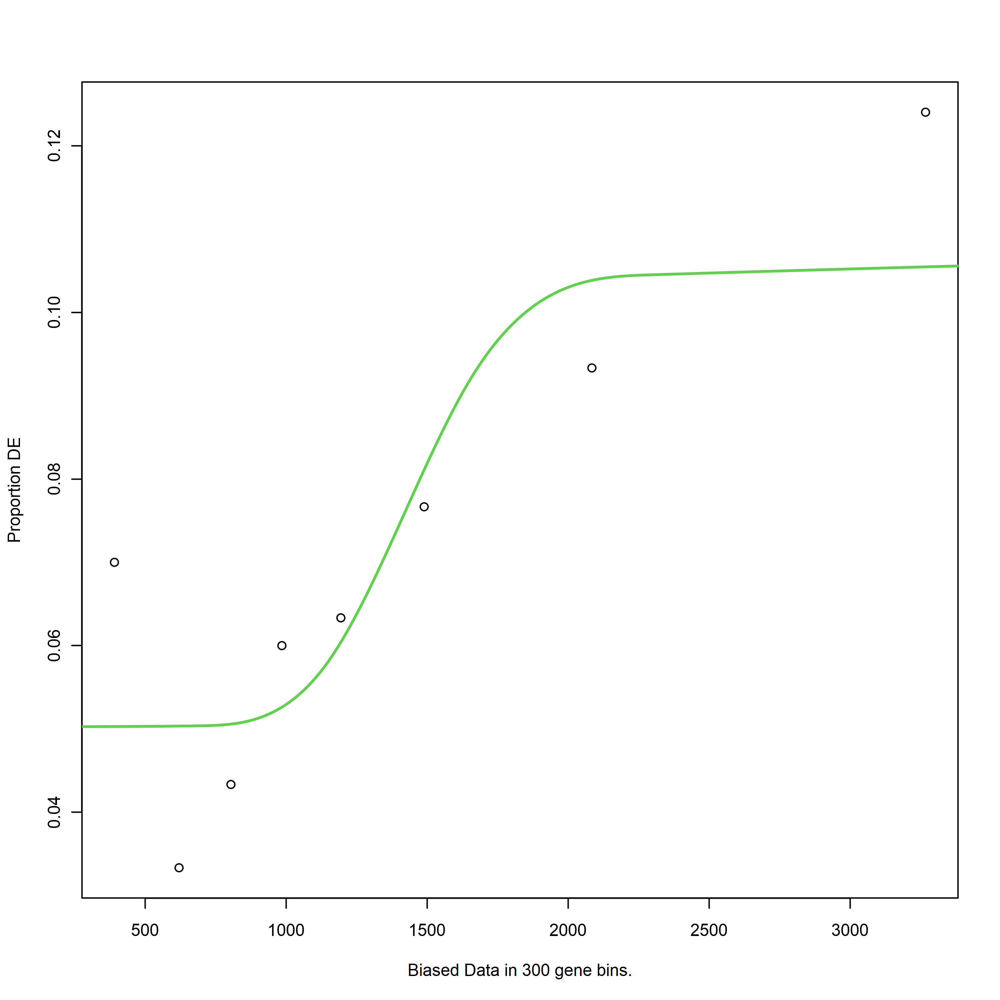

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


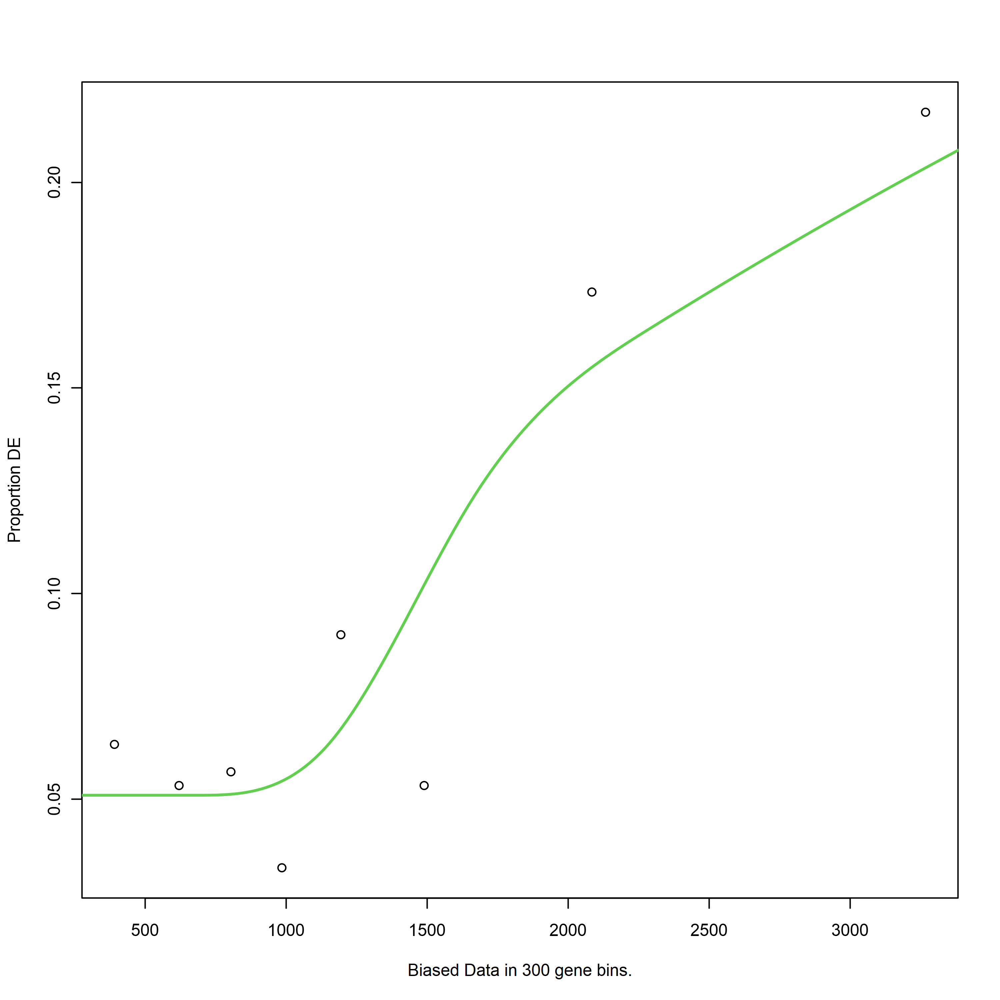

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC1_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


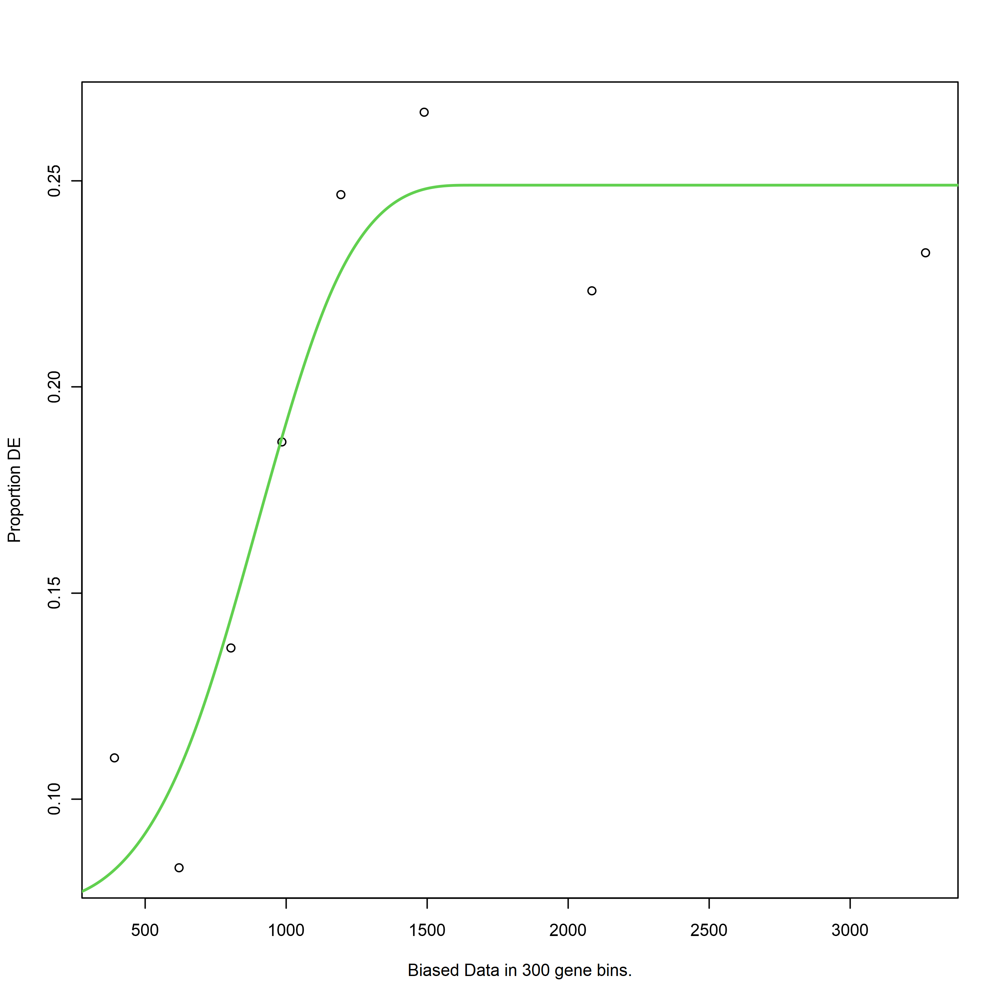

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


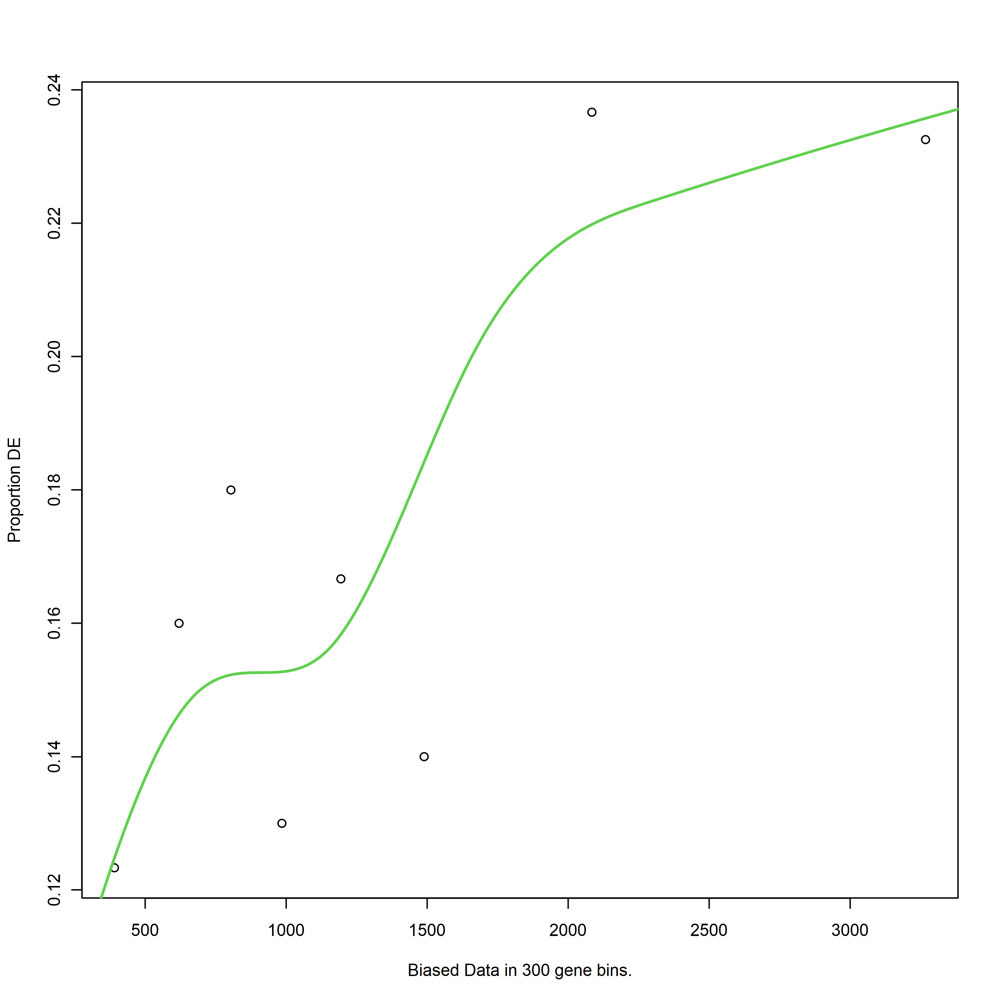

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C5vsC1_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


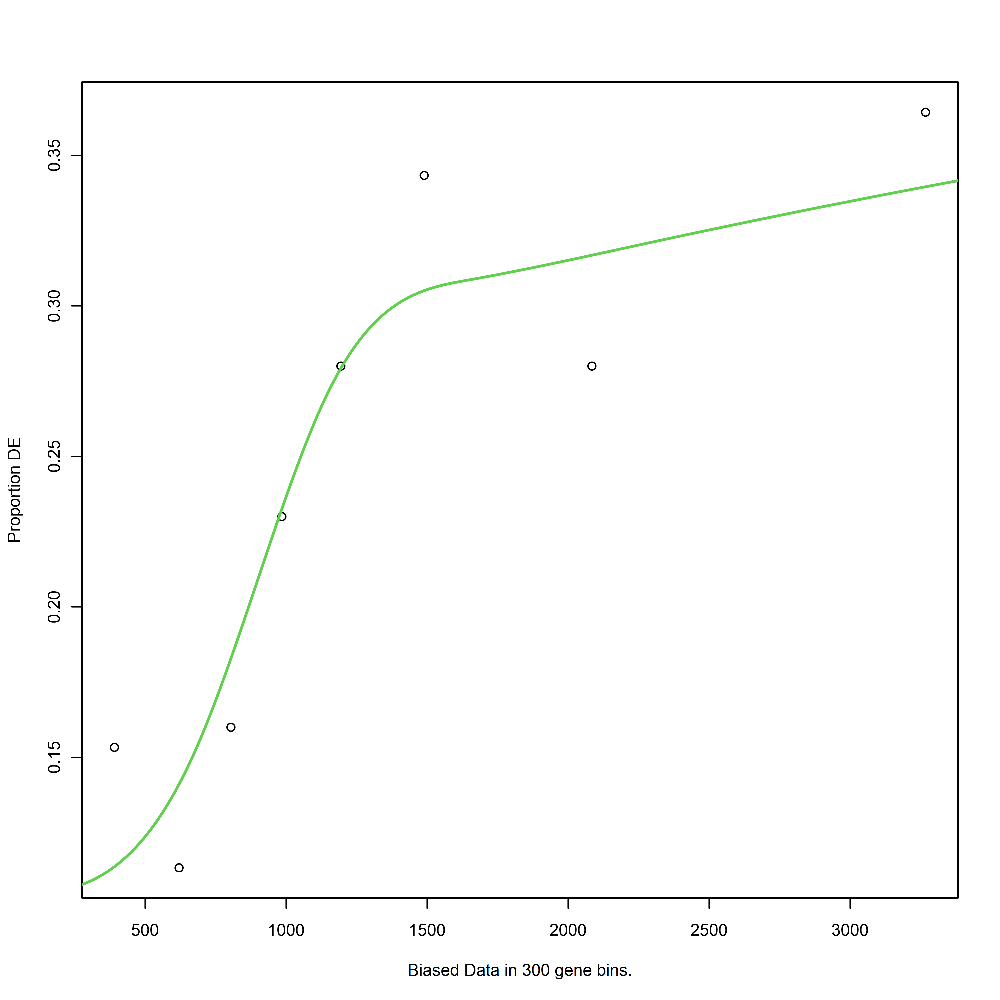

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C5vsC1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


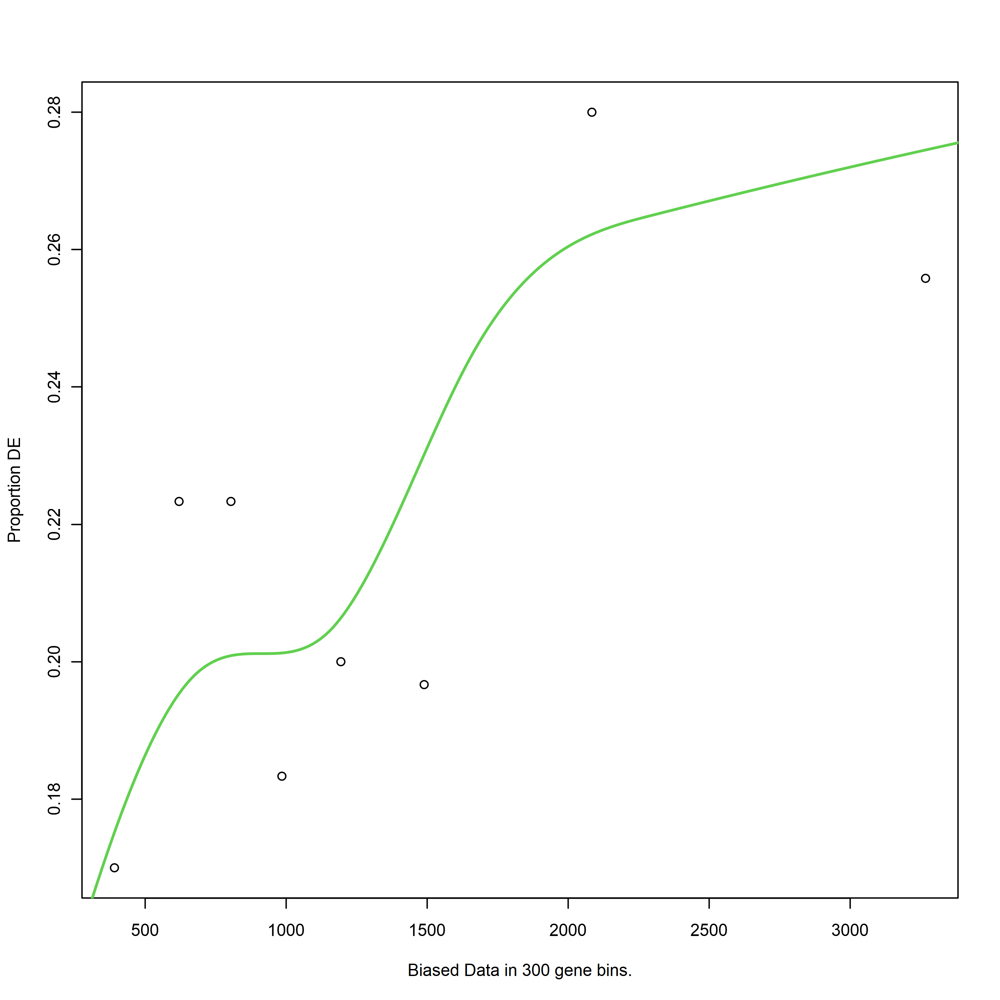

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC2_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


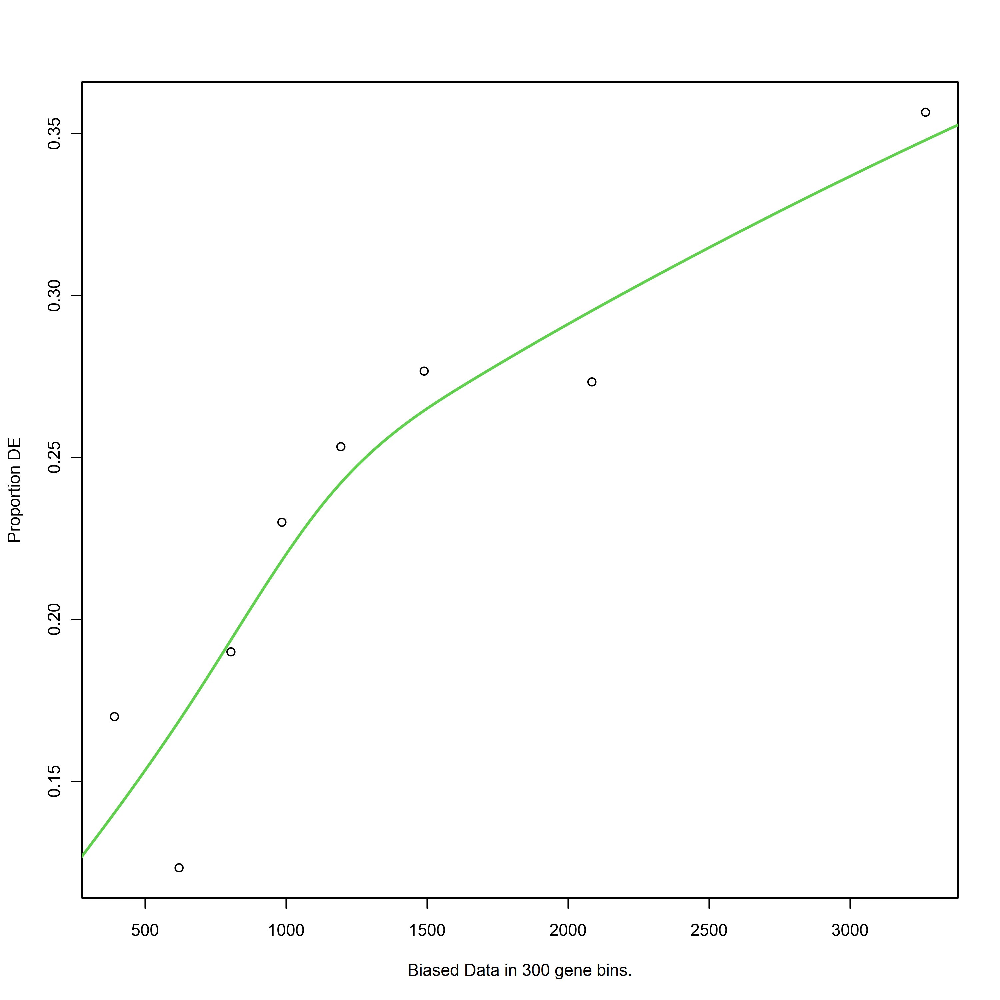

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC2_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


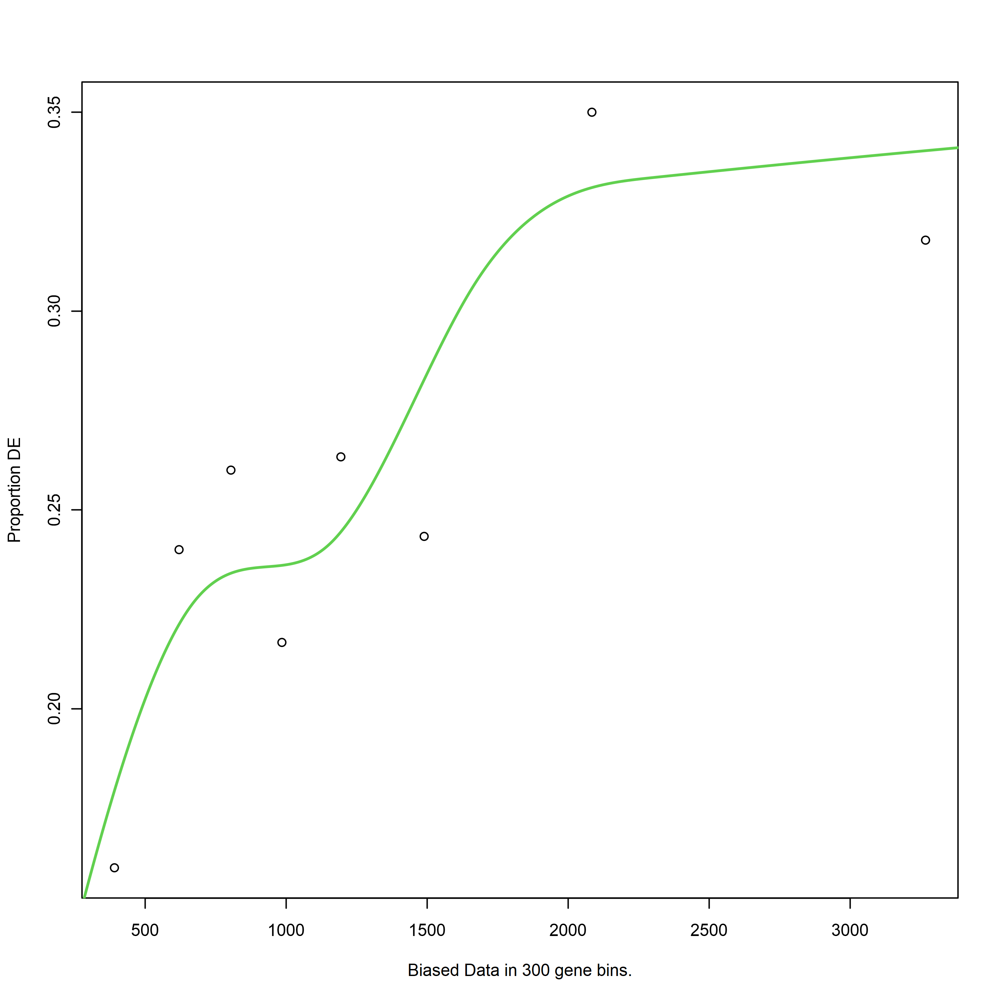

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC3_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


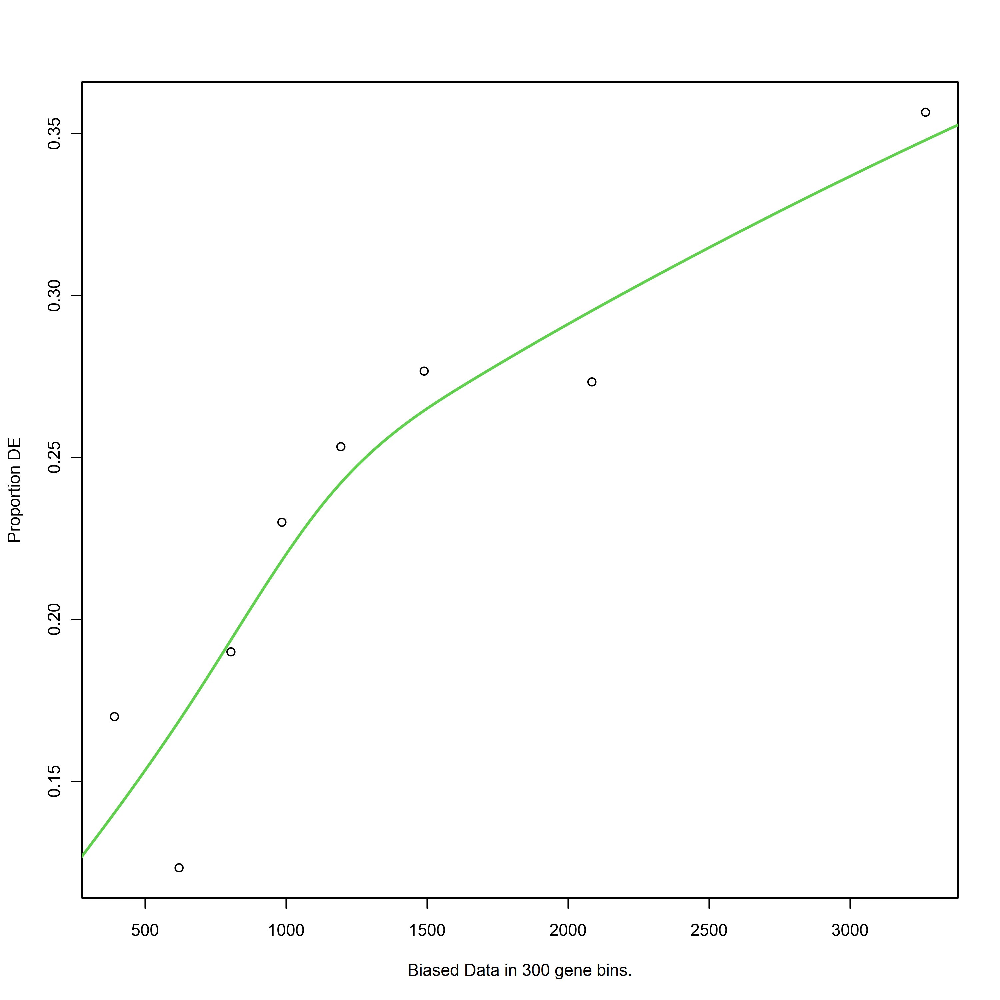

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC3_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


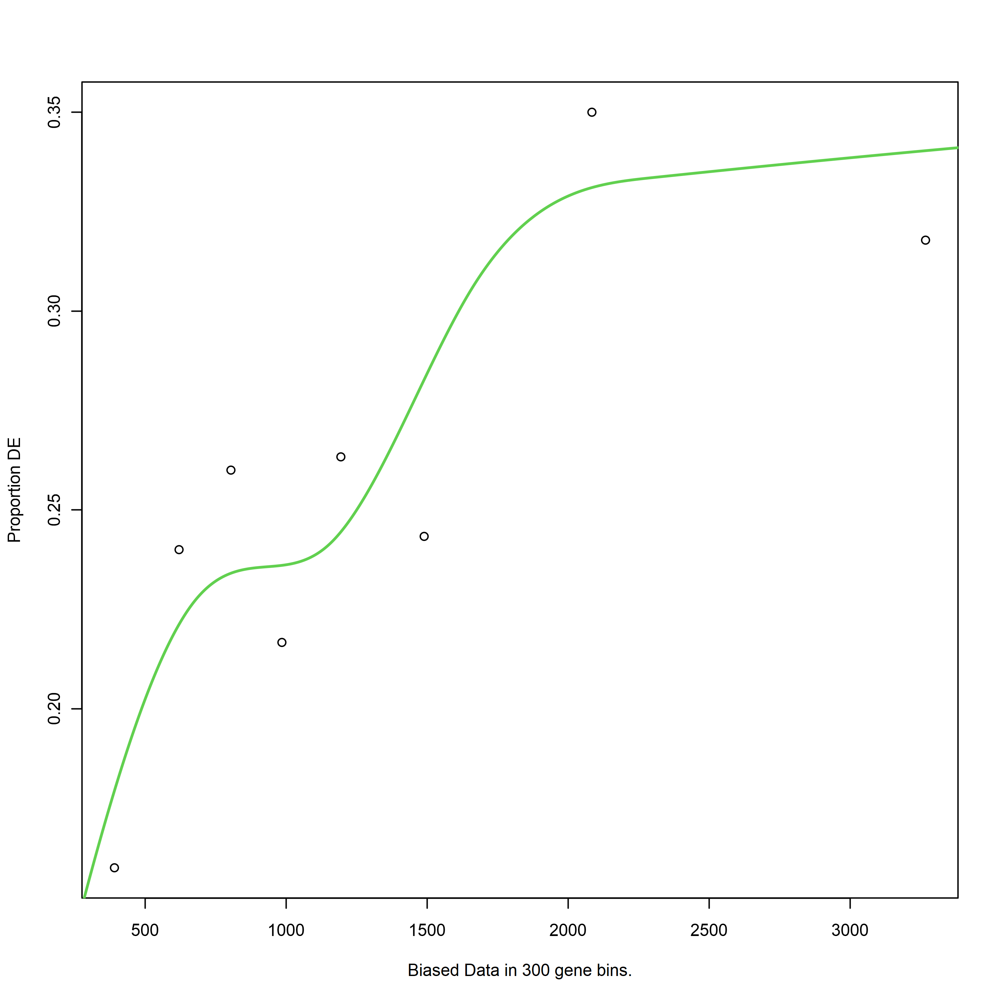

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C5vsC4_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


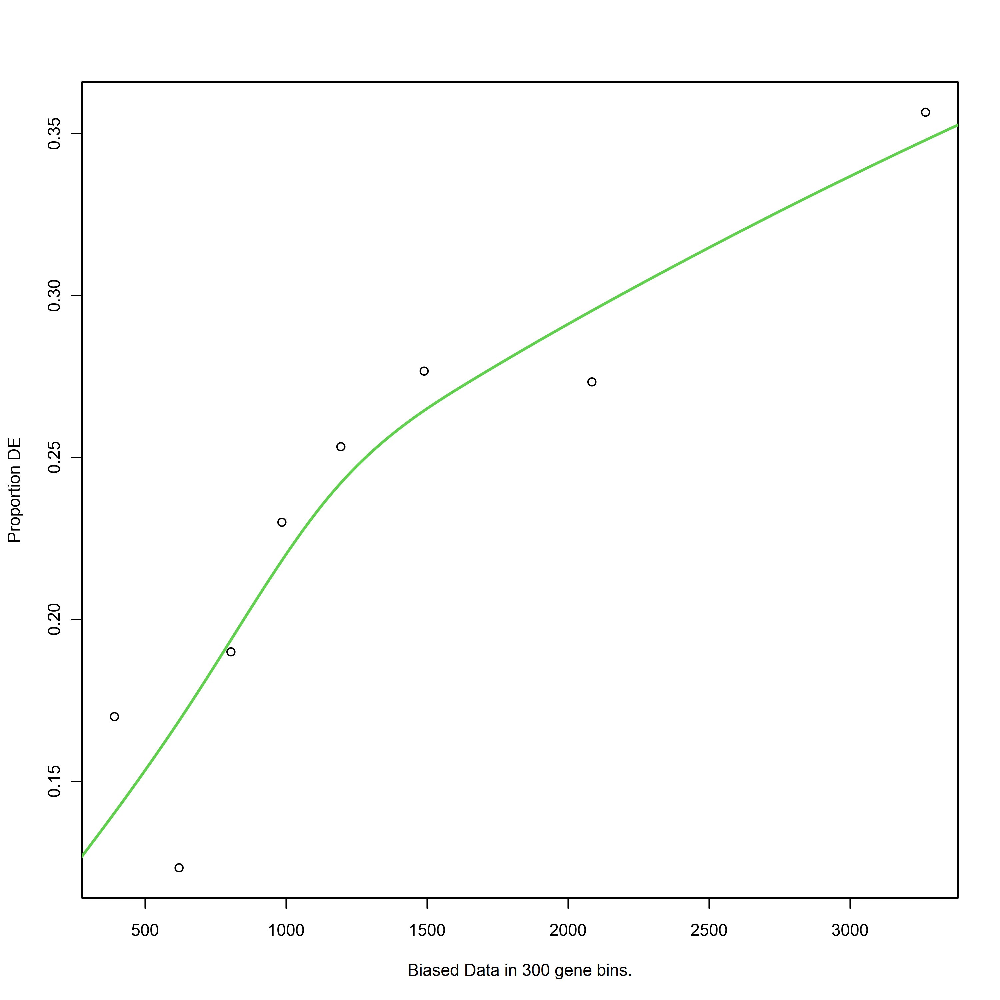

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C5vsC4_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


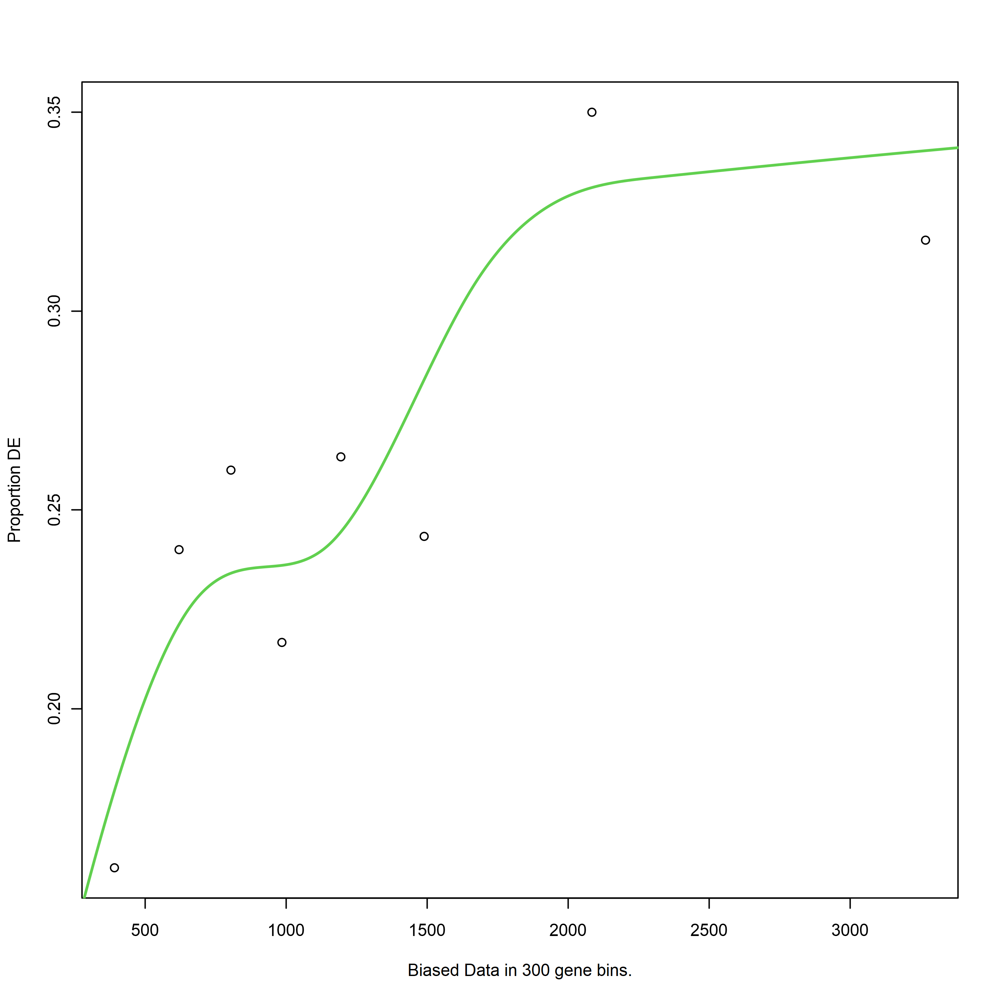

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC1_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


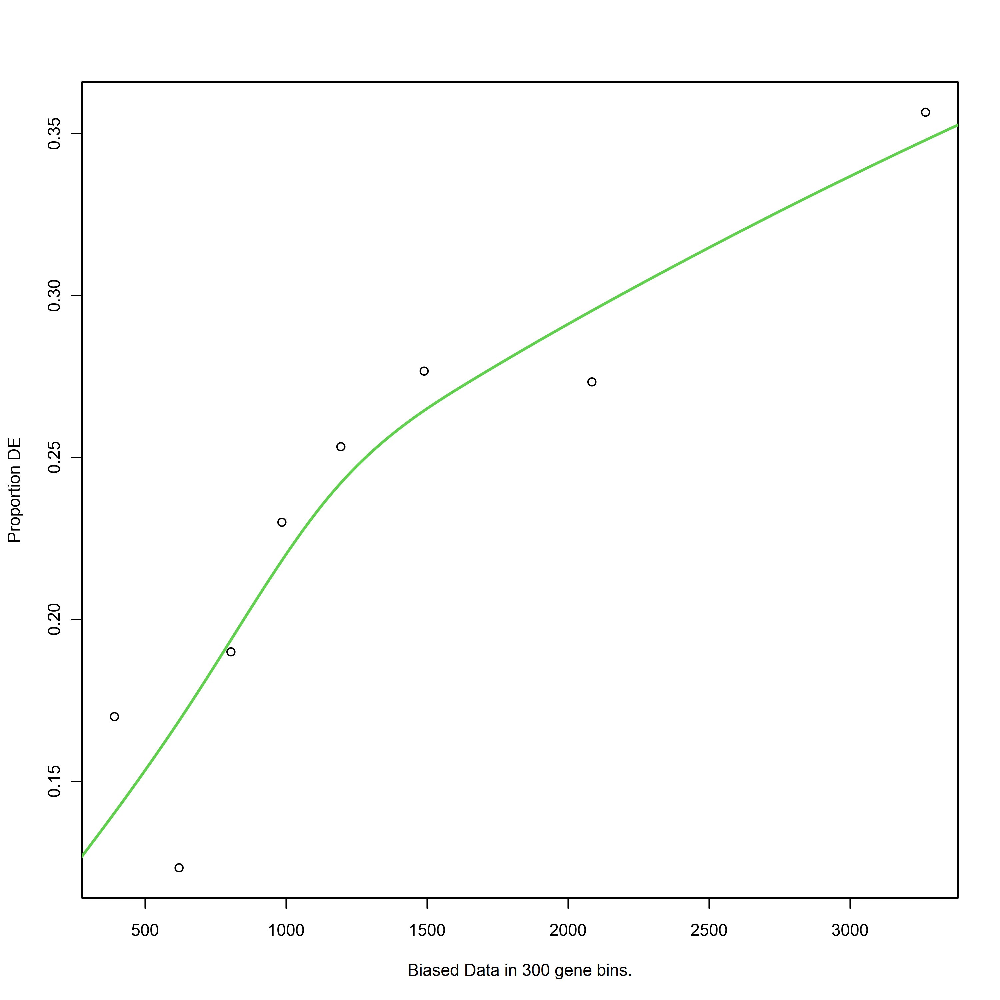

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


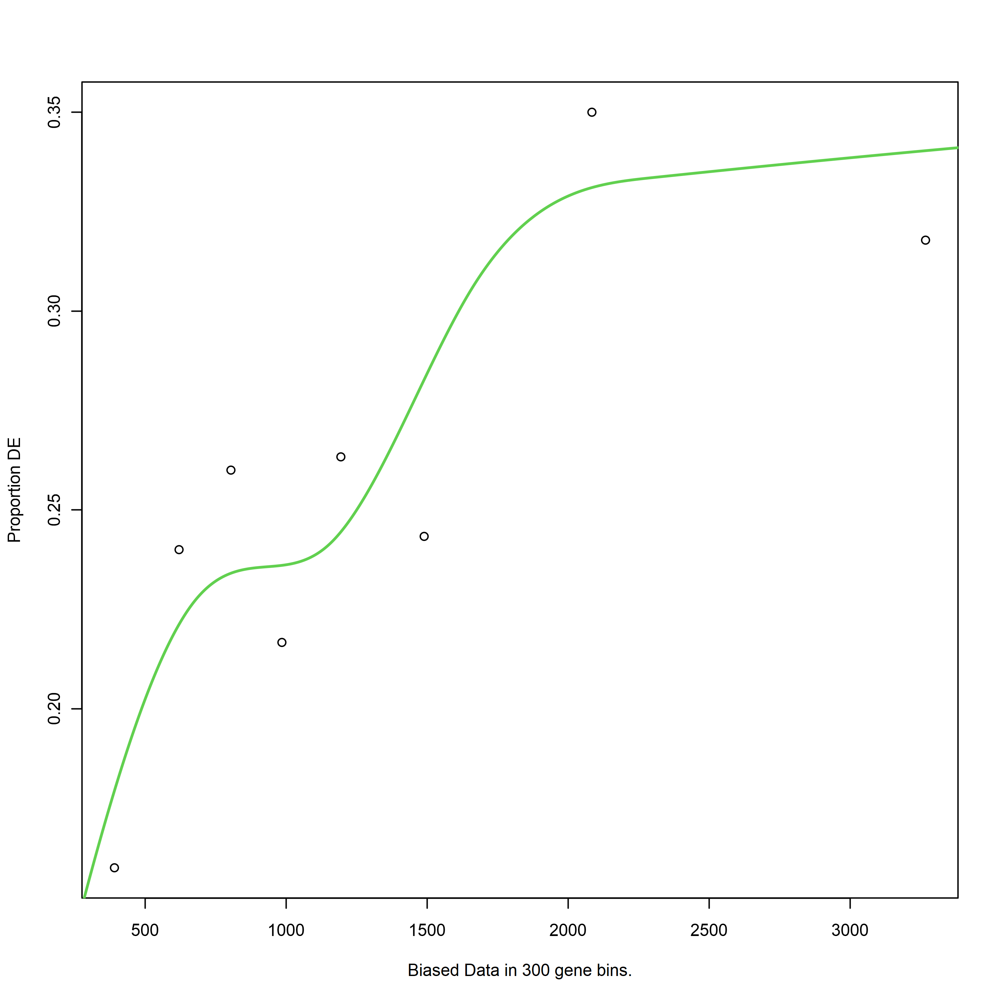

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC2_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


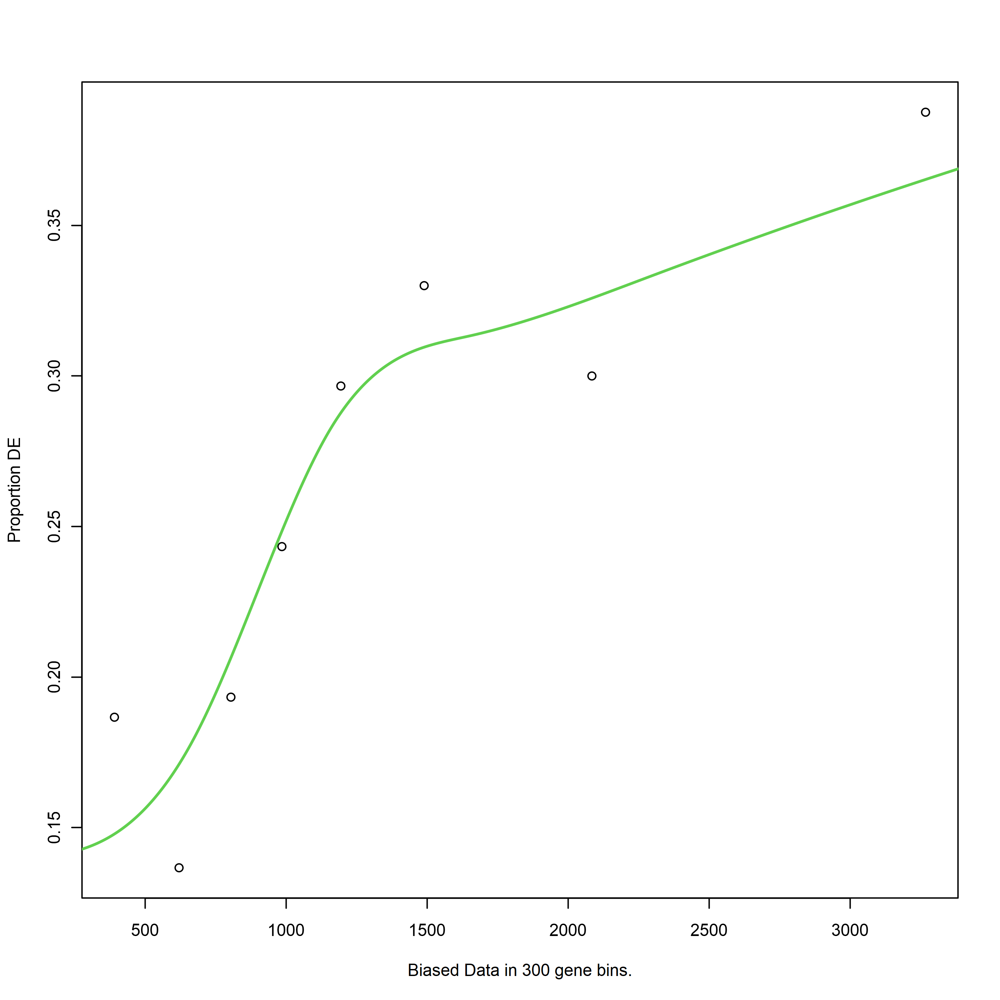

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC2_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


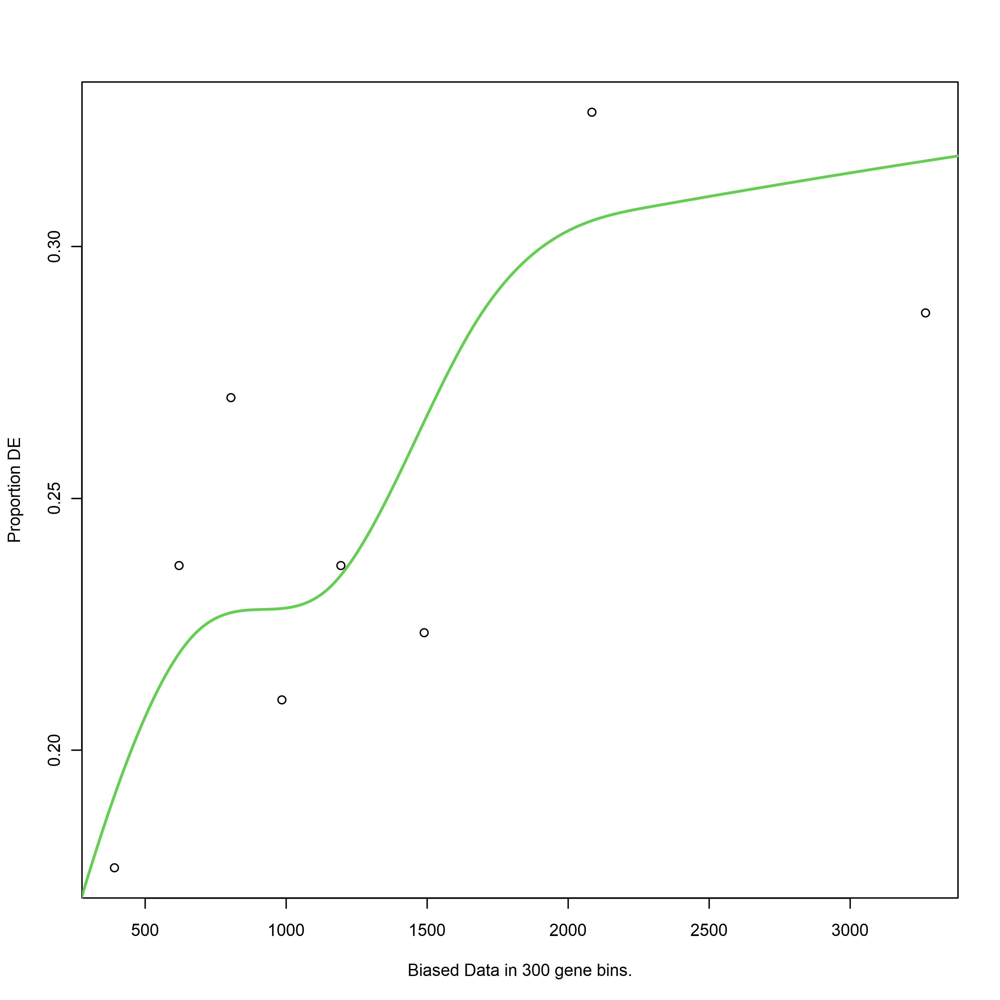

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC3_prot"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


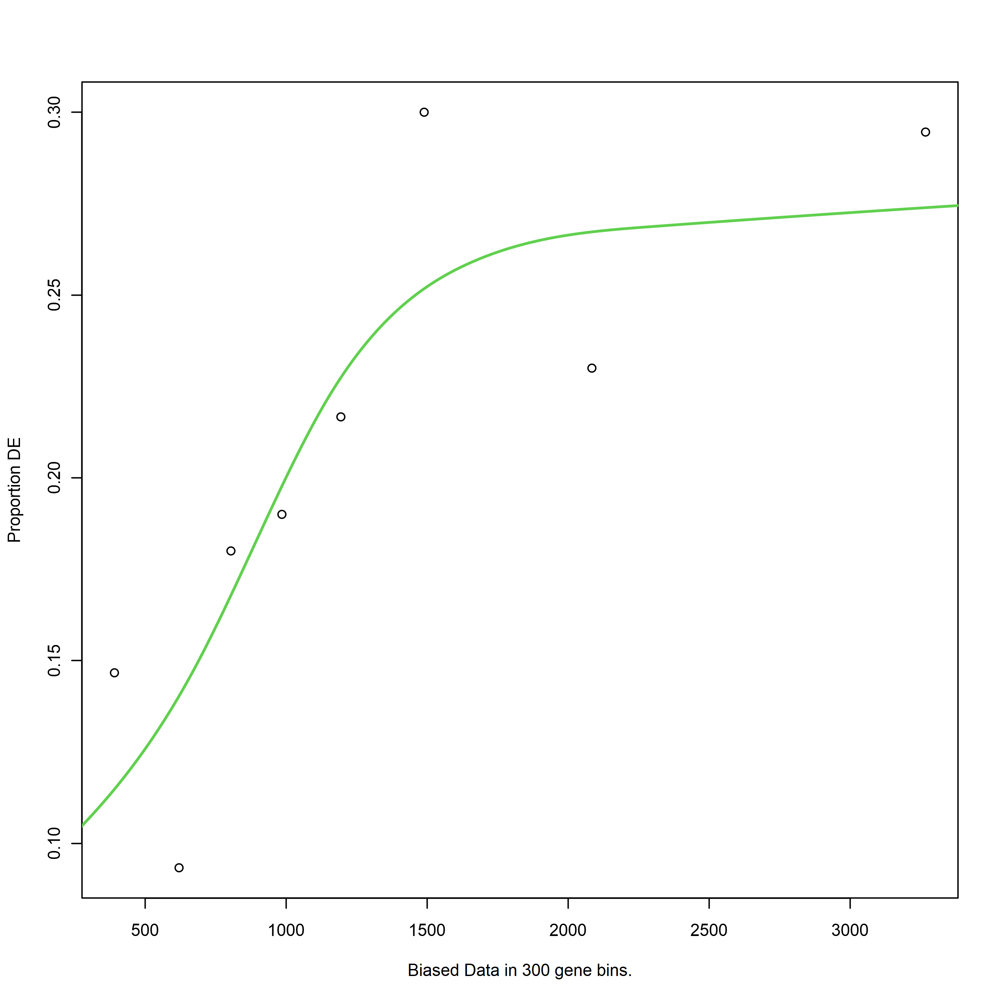

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC3_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


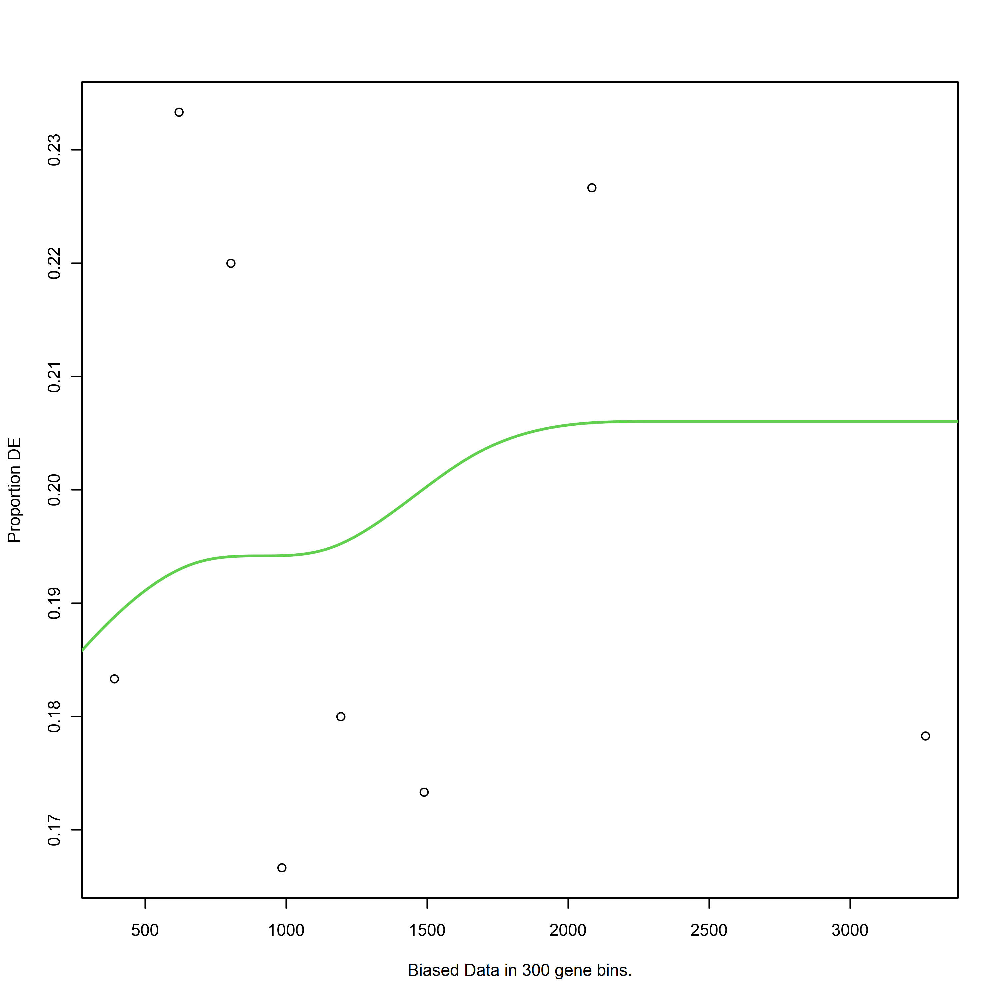

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



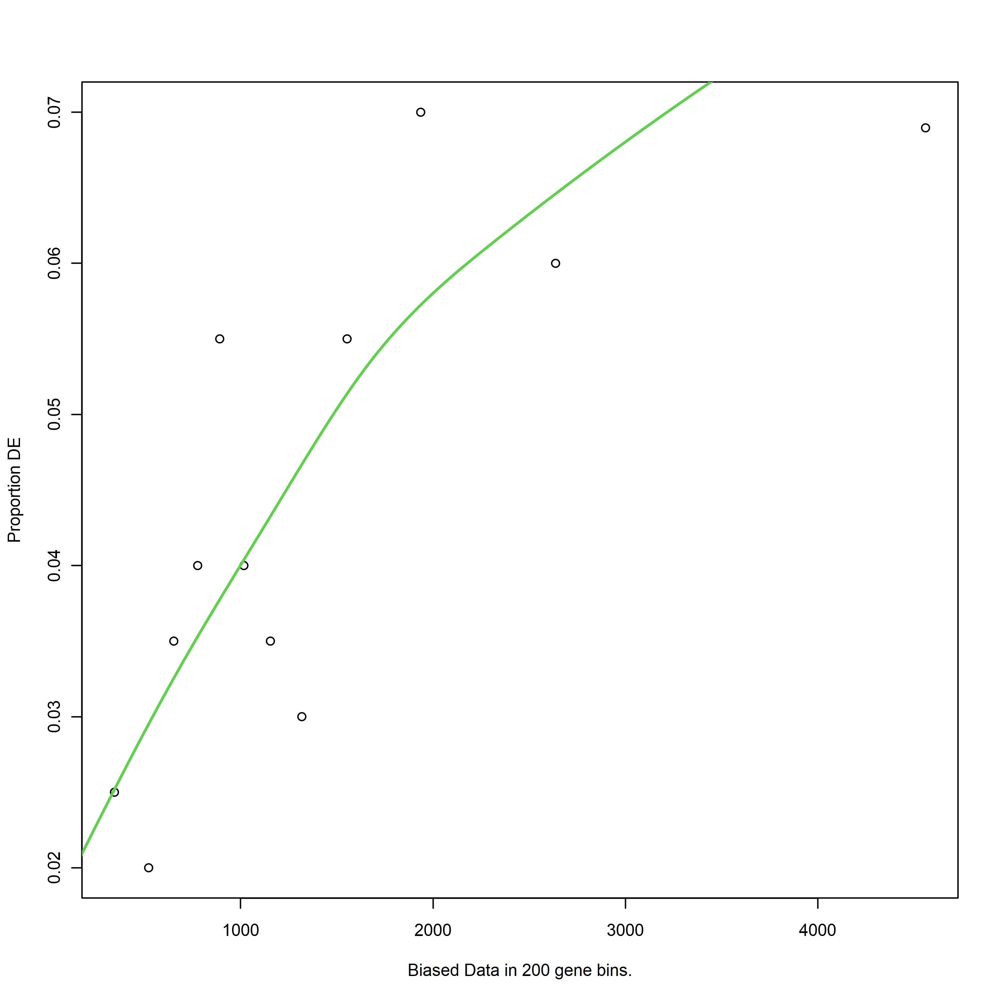

[1] "A2vsA1_prot"
[1] "path"
[1] "down"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



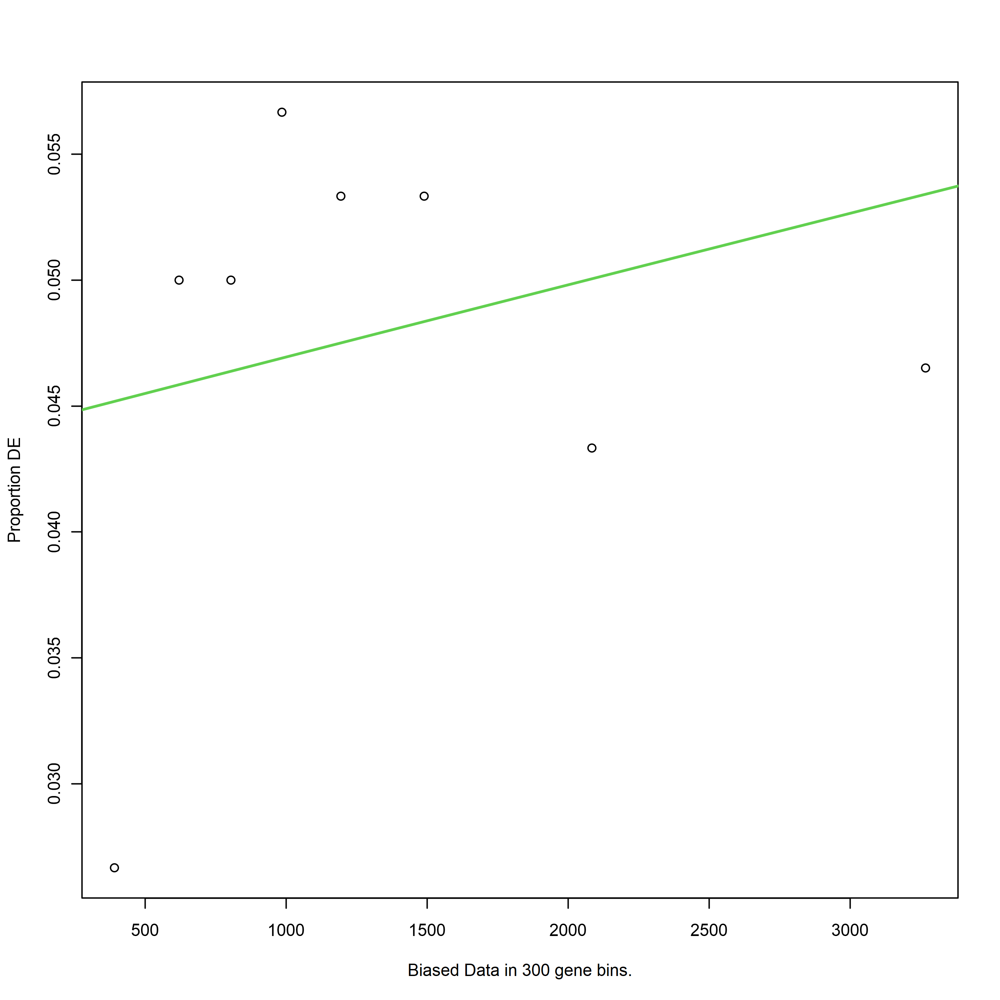

[1] "A2vsA1_prot"
[1] "path"
[1] "up"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A3vsA1_prot"
[1] "path"
[1] "down"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A3vsA1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


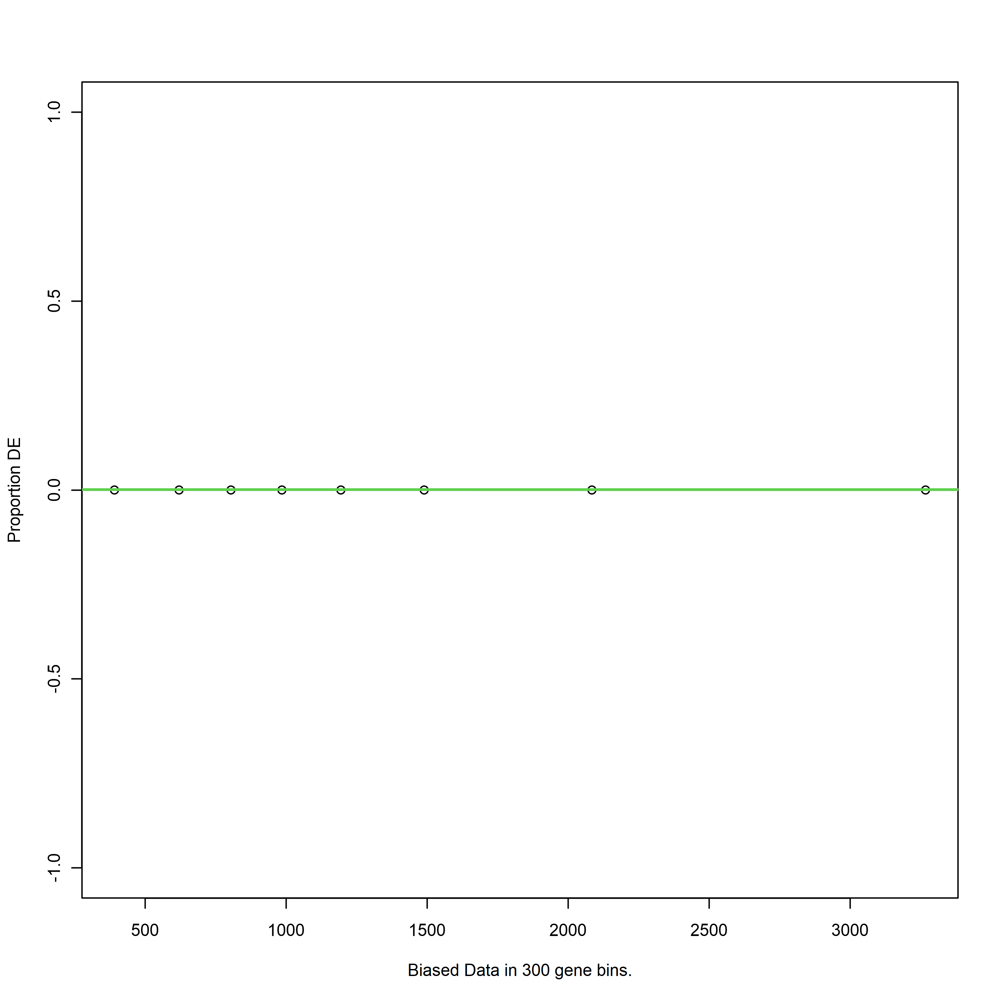

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



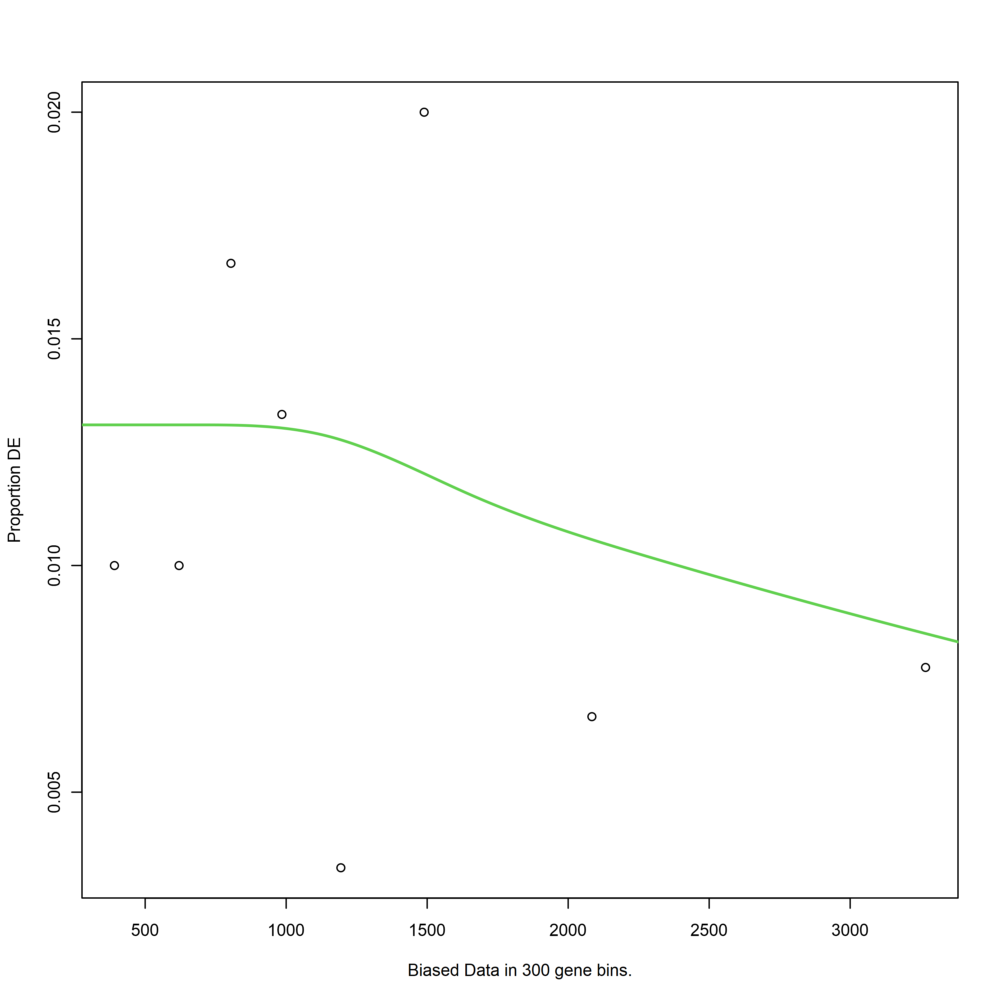

[1] "A5vsA1_prot"
[1] "path"
[1] "down"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A5vsA1_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


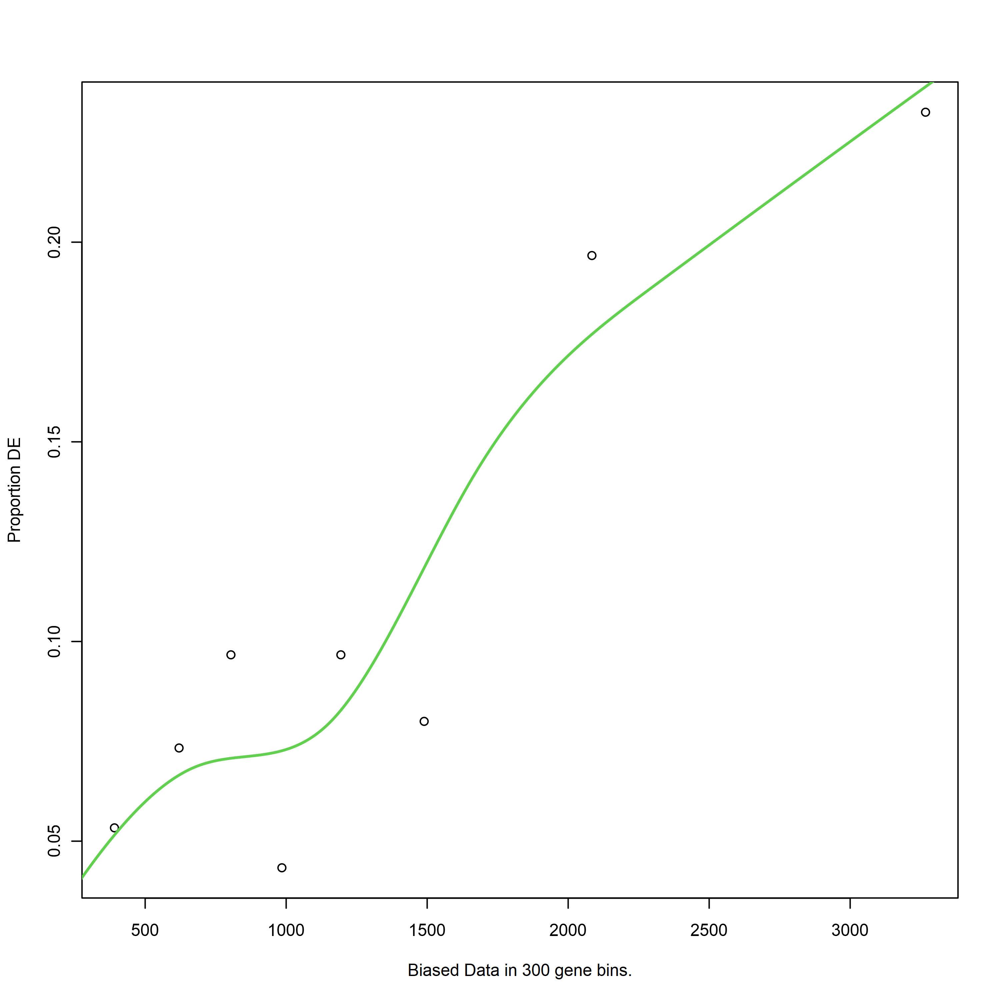

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



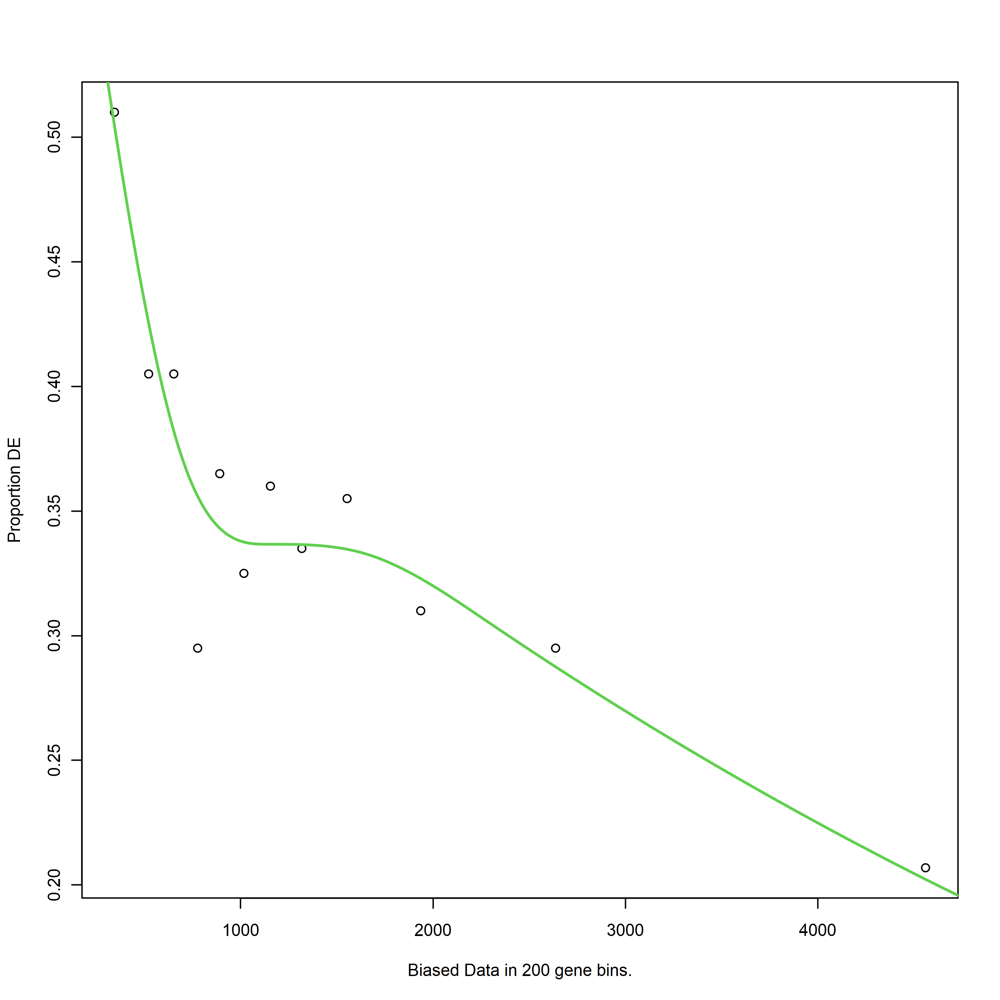

[1] "A3vsA2_prot"
[1] "path"
[1] "down"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



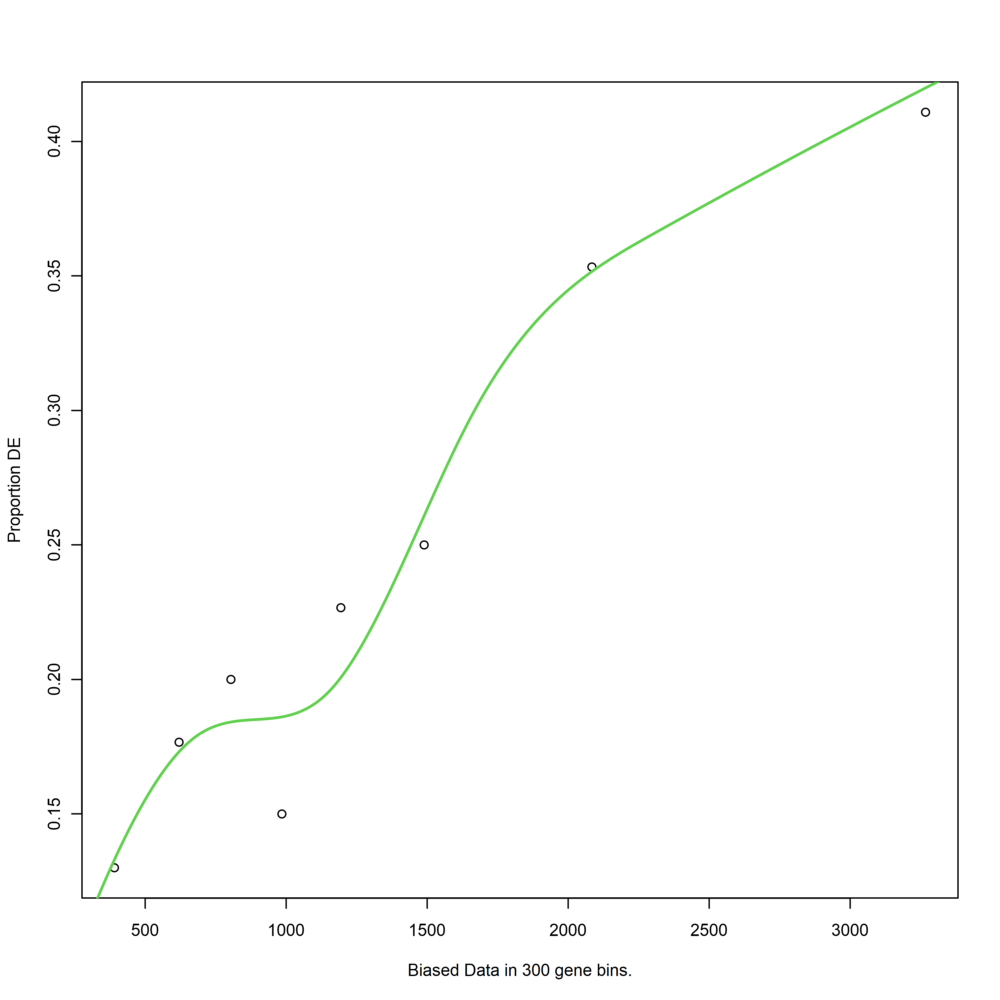

[1] "A3vsA2_prot"
[1] "path"
[1] "up"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A5vsA3_prot"
[1] "path"
[1] "down"


Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A5vsA3_prot"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


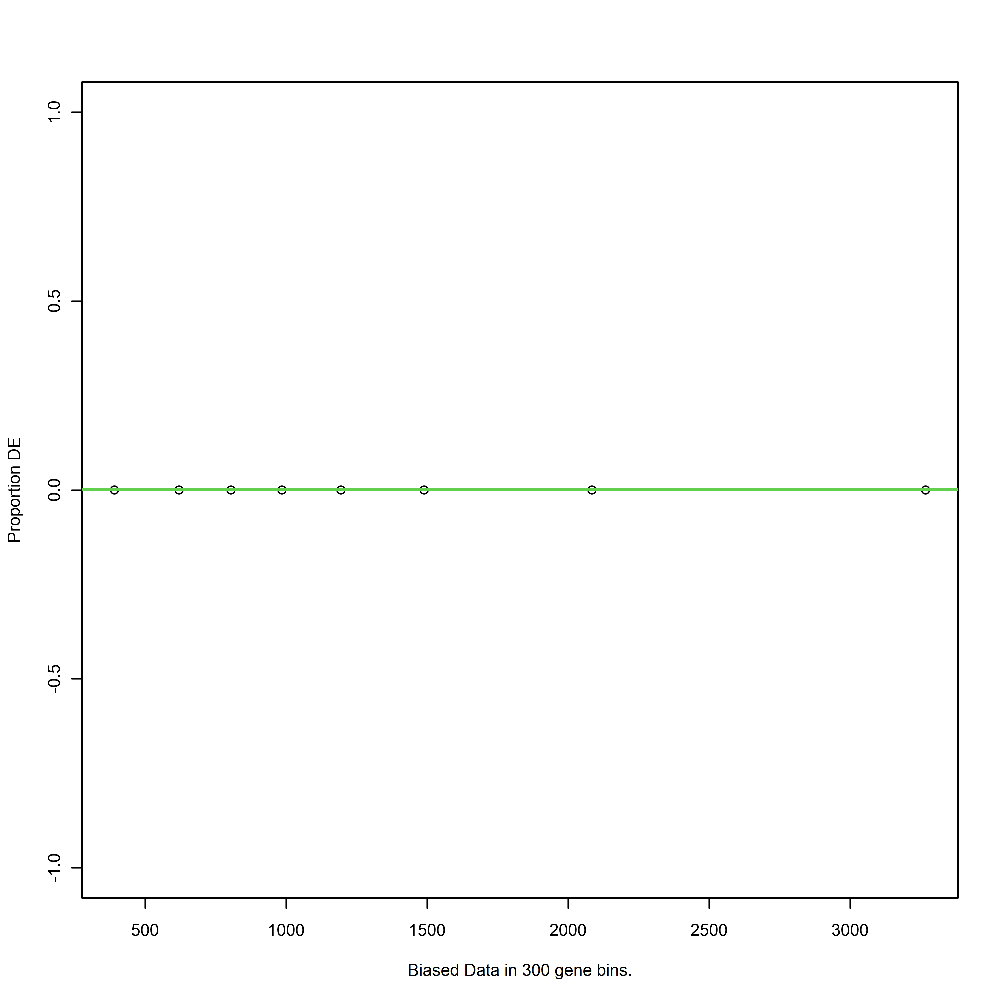

Using manually entered categories.

For 749 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



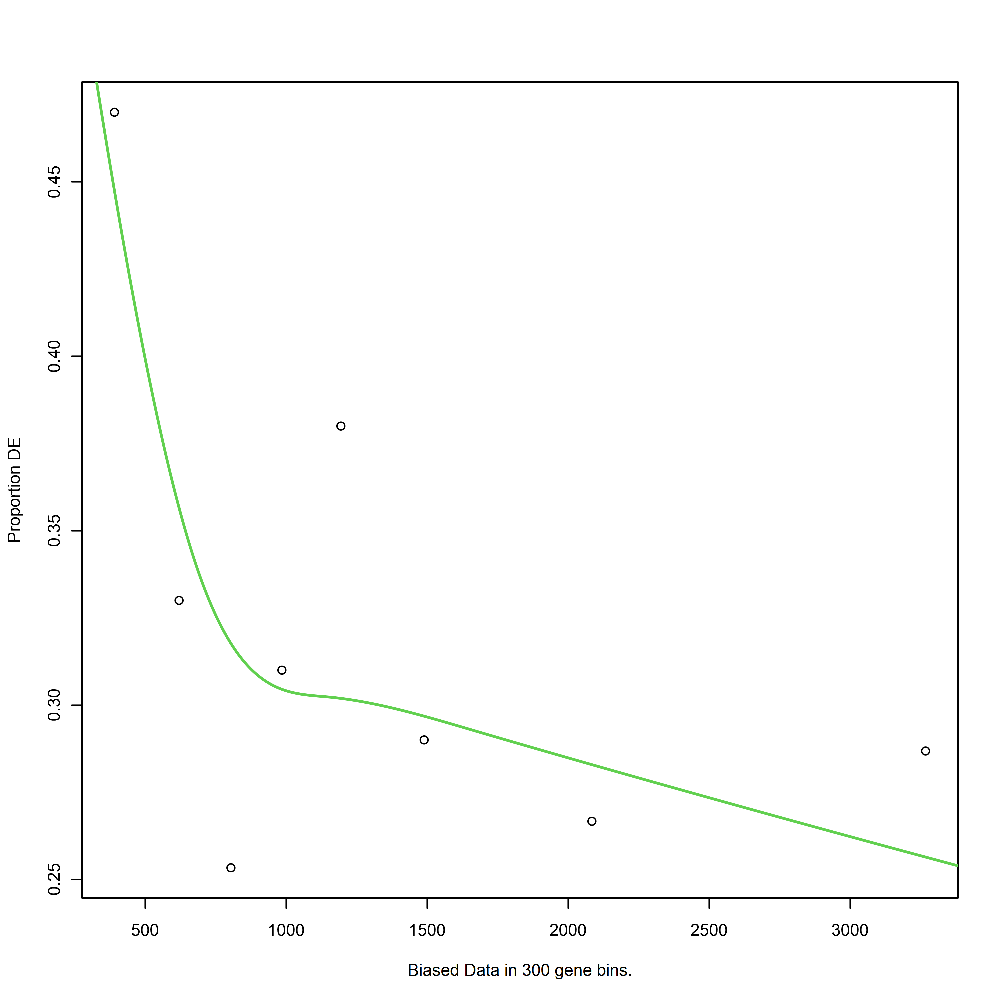

[1] "LATEvsA1_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsA1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


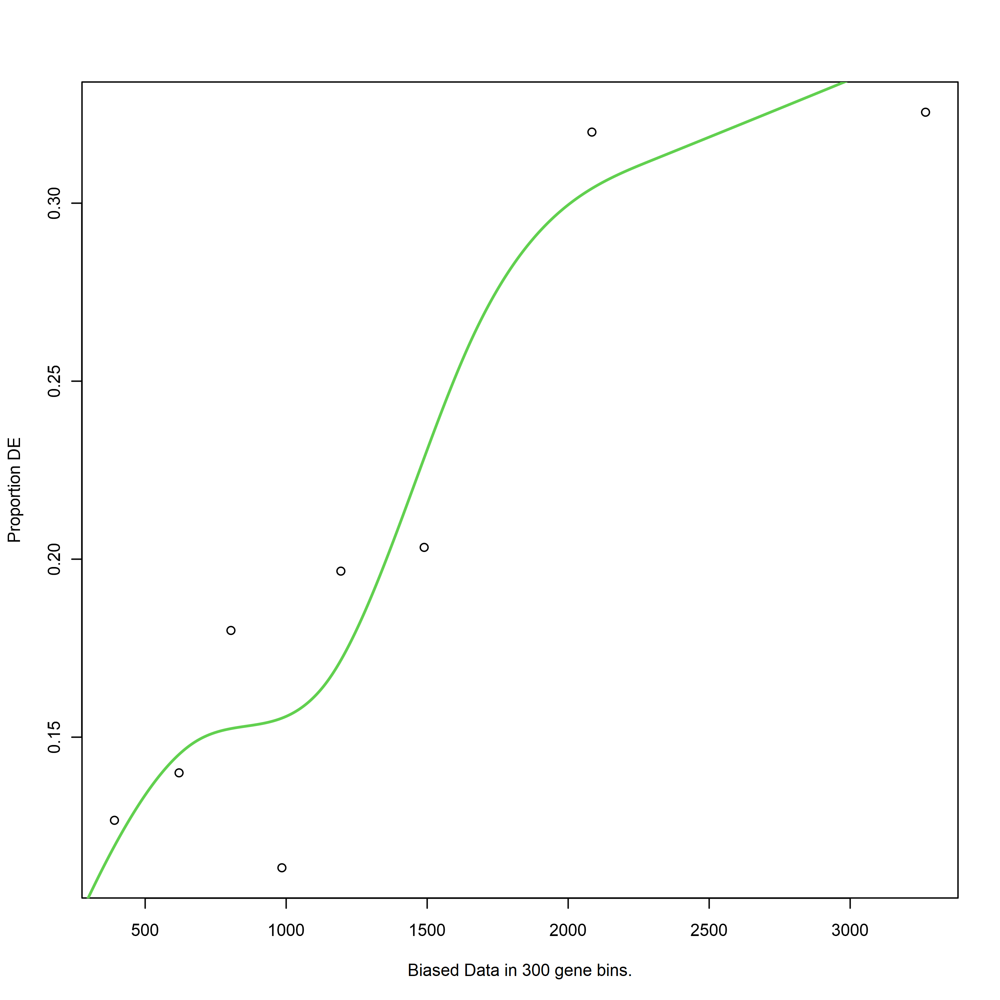

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsA2_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


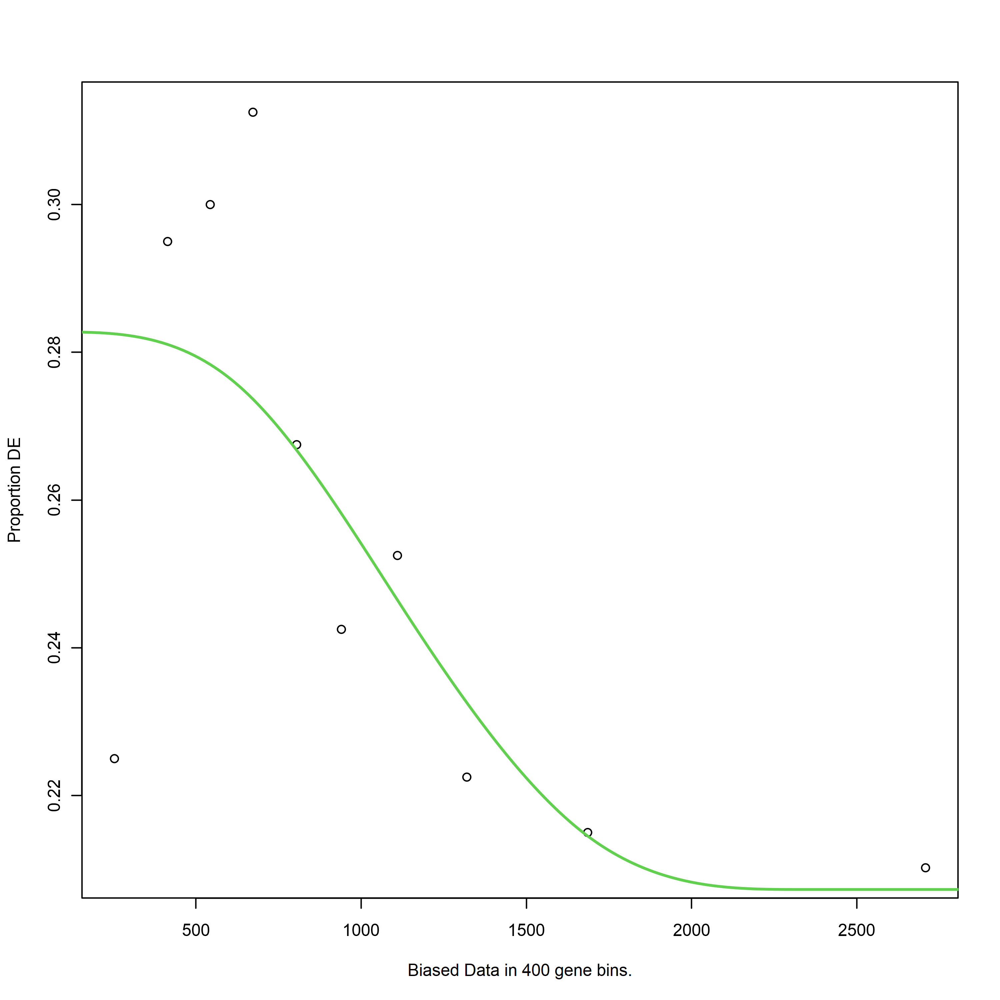

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsA2_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


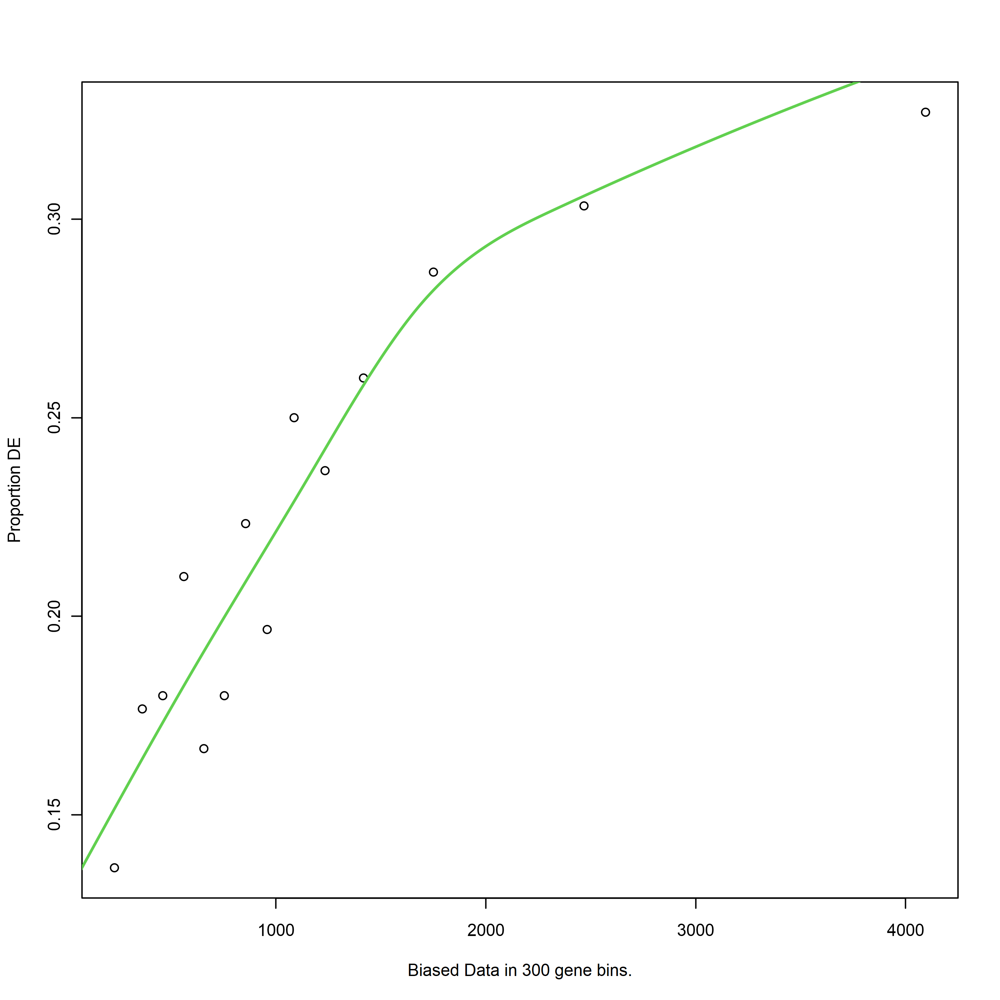

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsA3_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


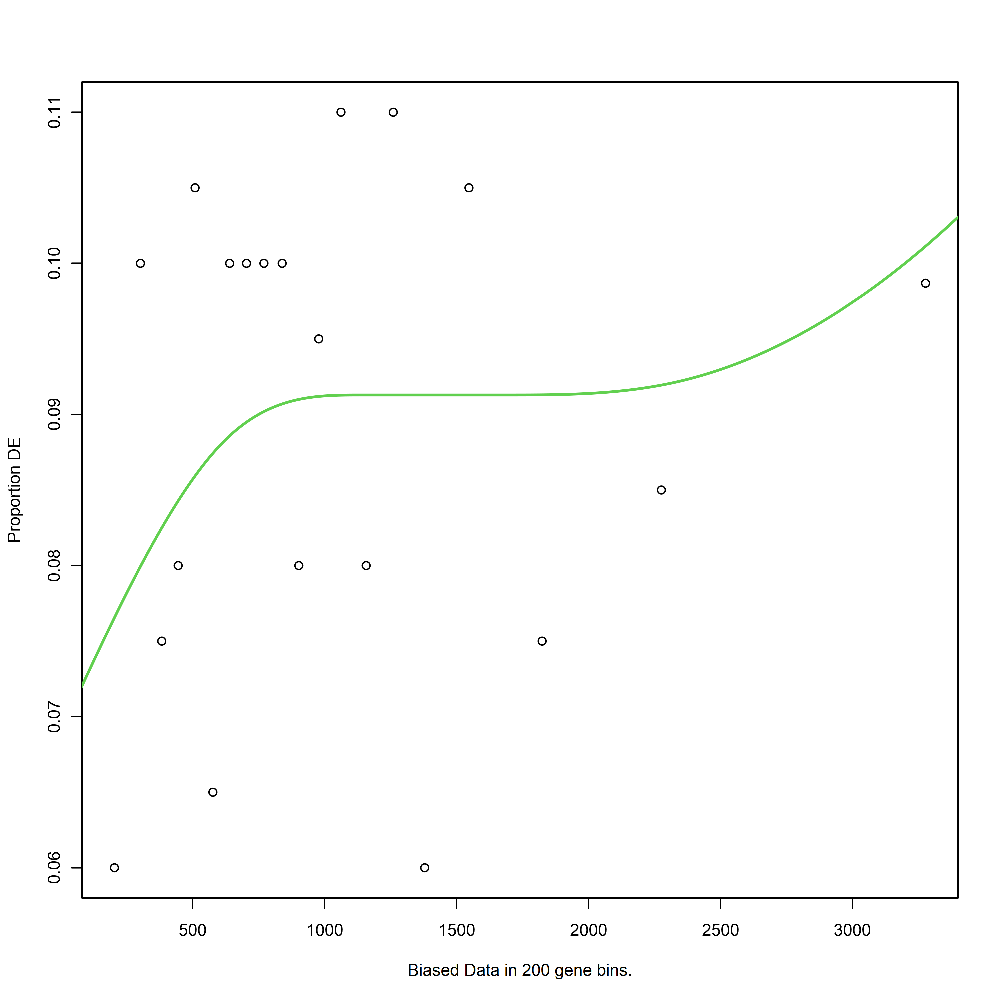

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsA3_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


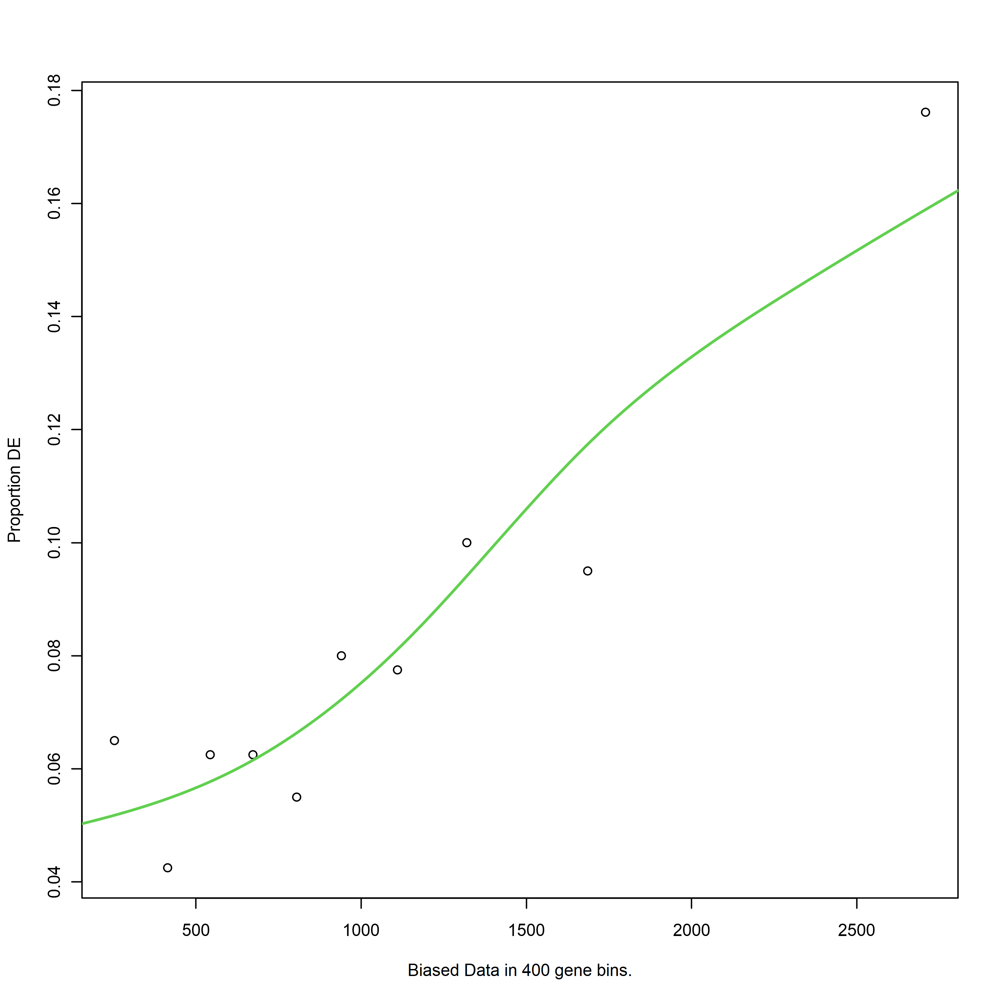

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC1_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


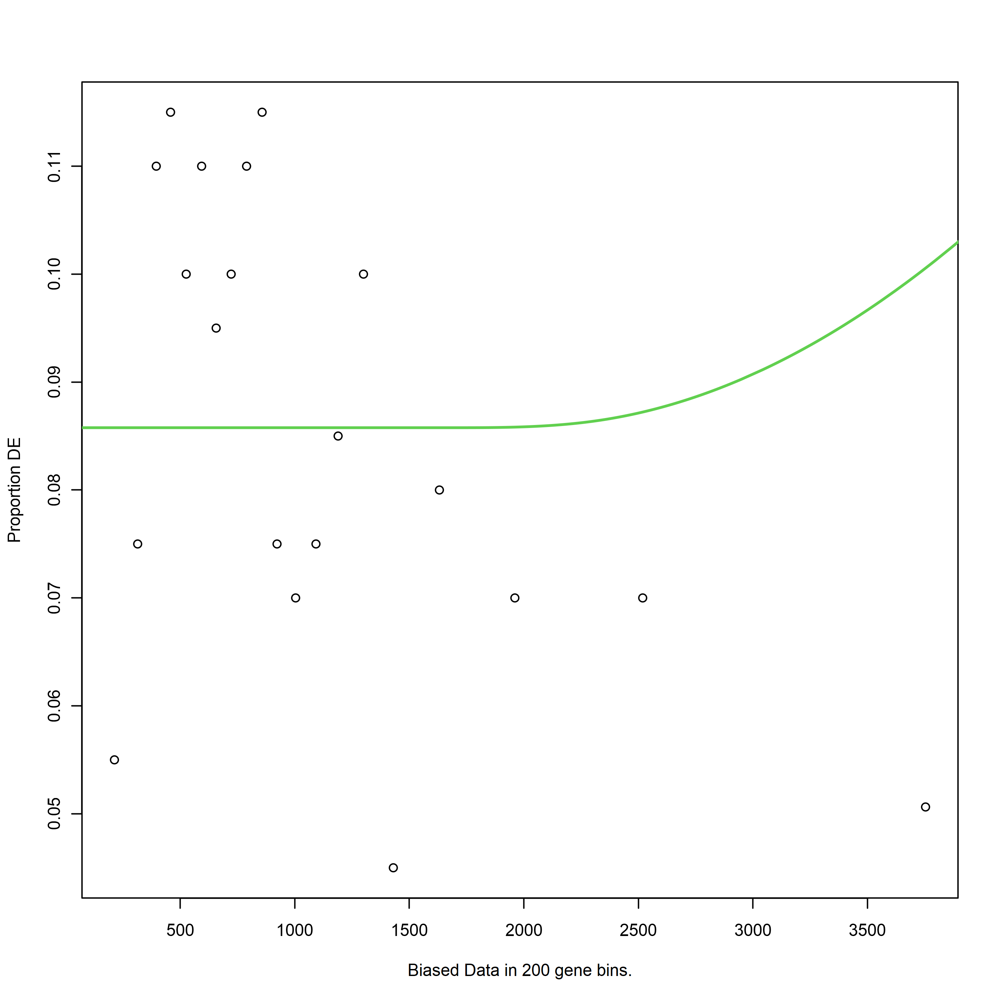

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


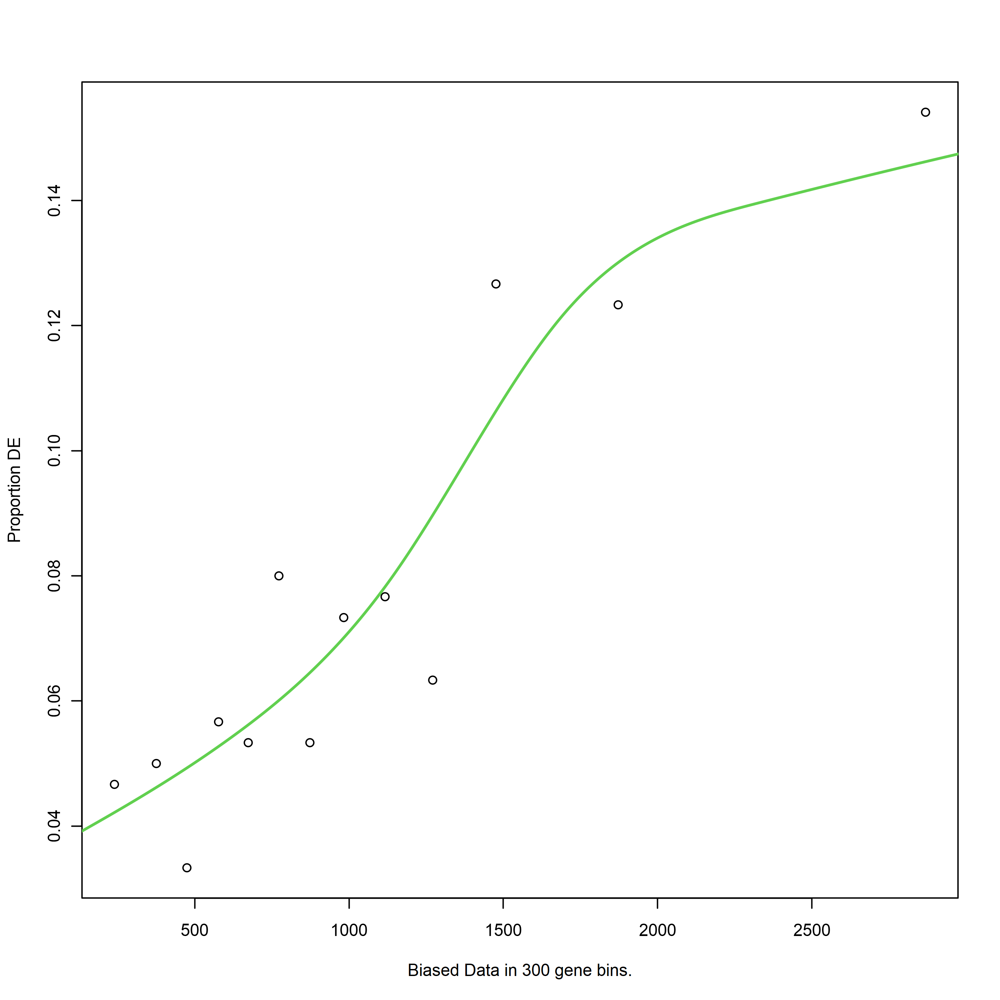

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC2_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


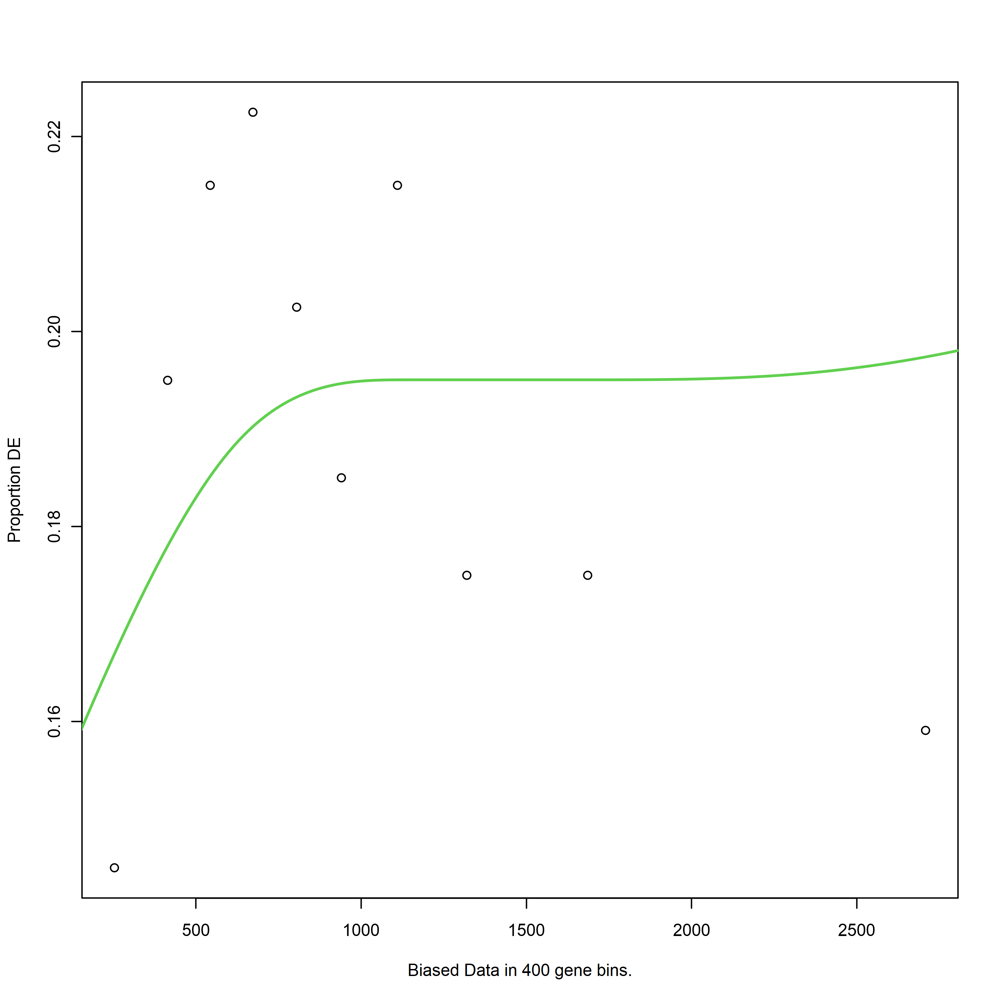

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC2_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


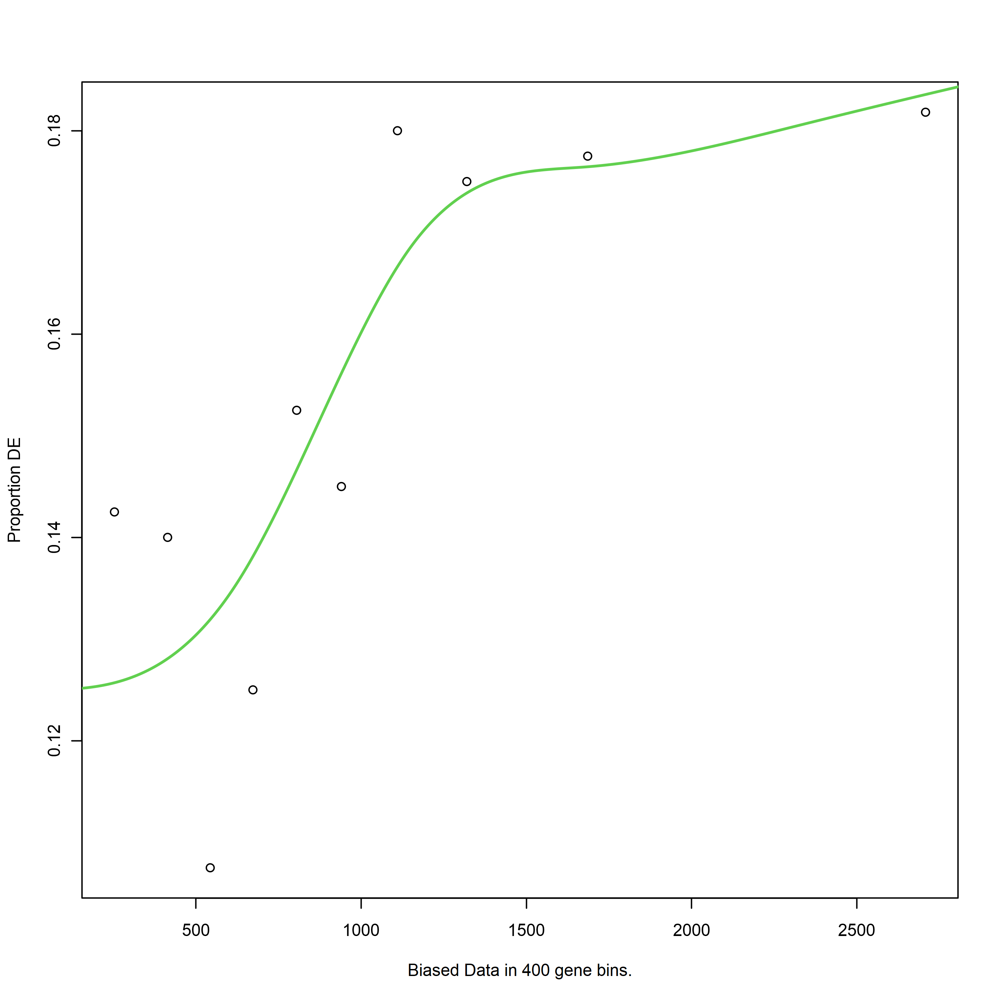

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC3_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


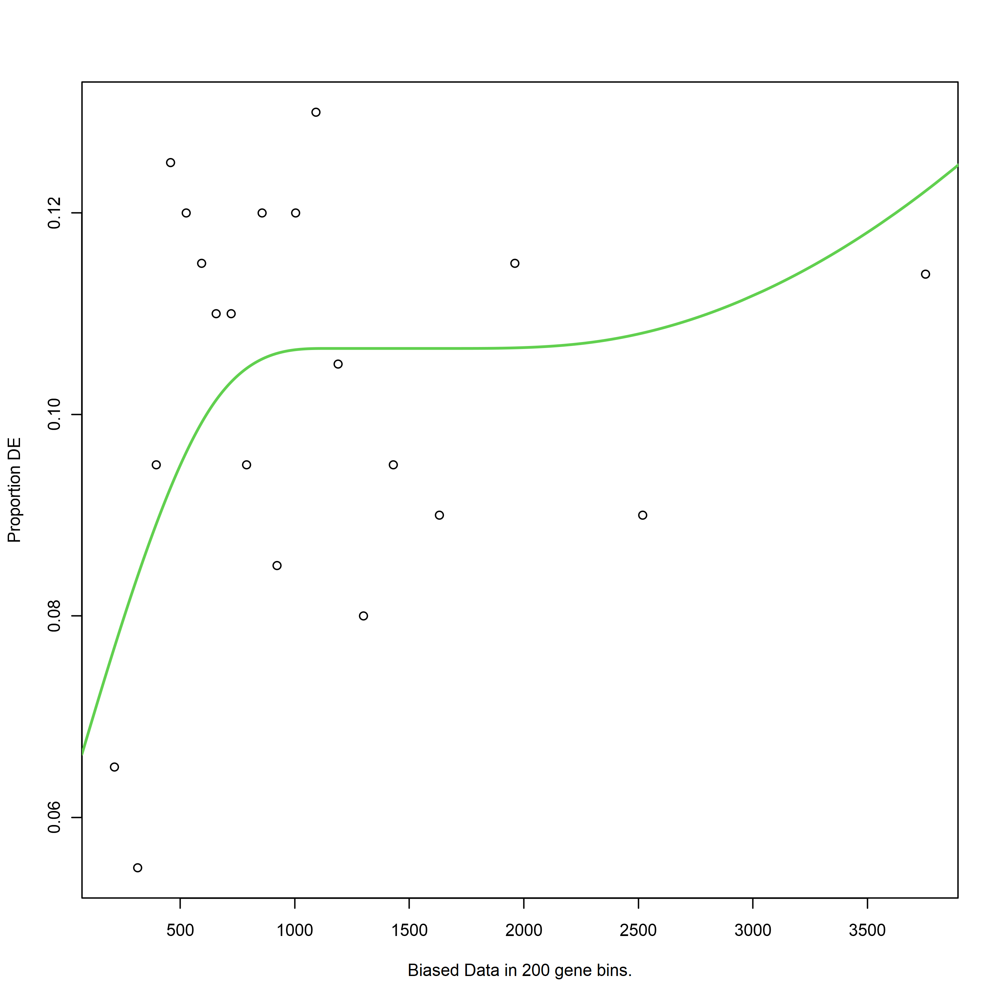

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "LATEvsC3_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


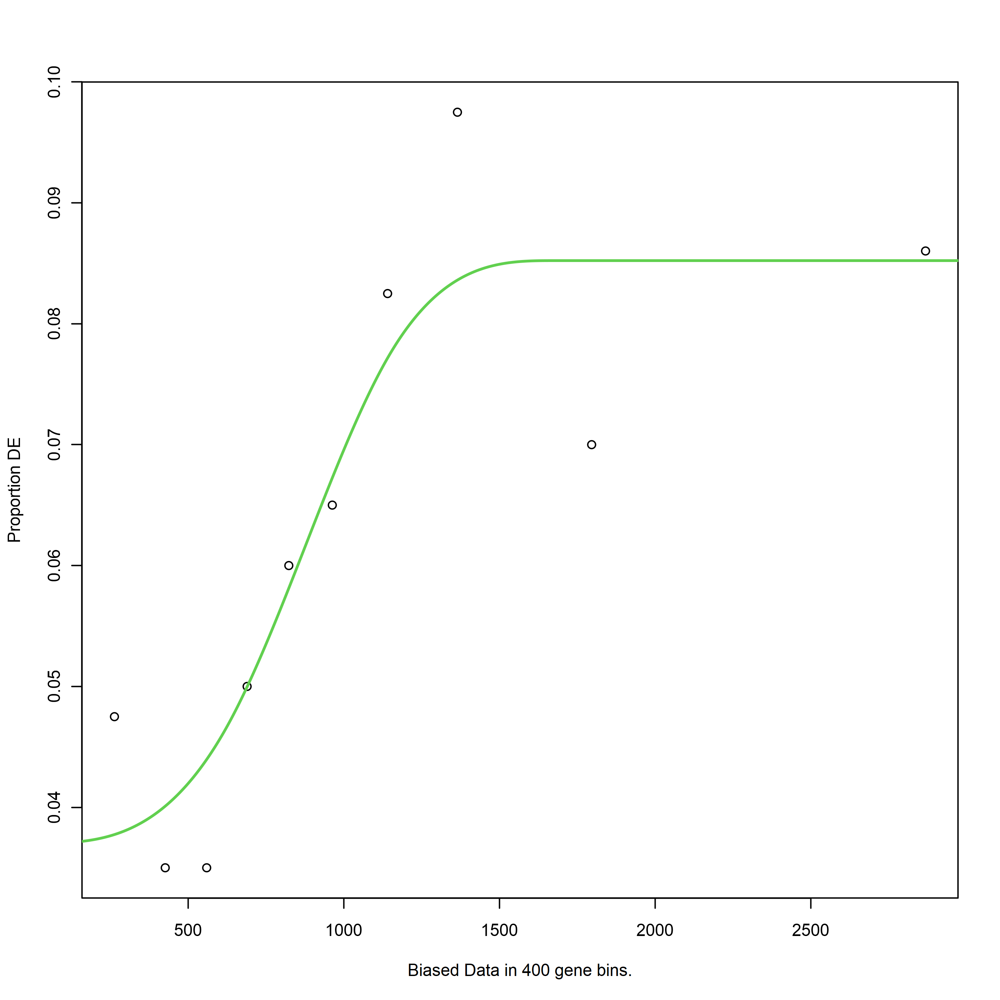

Using manually entered categories.

For 1813 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



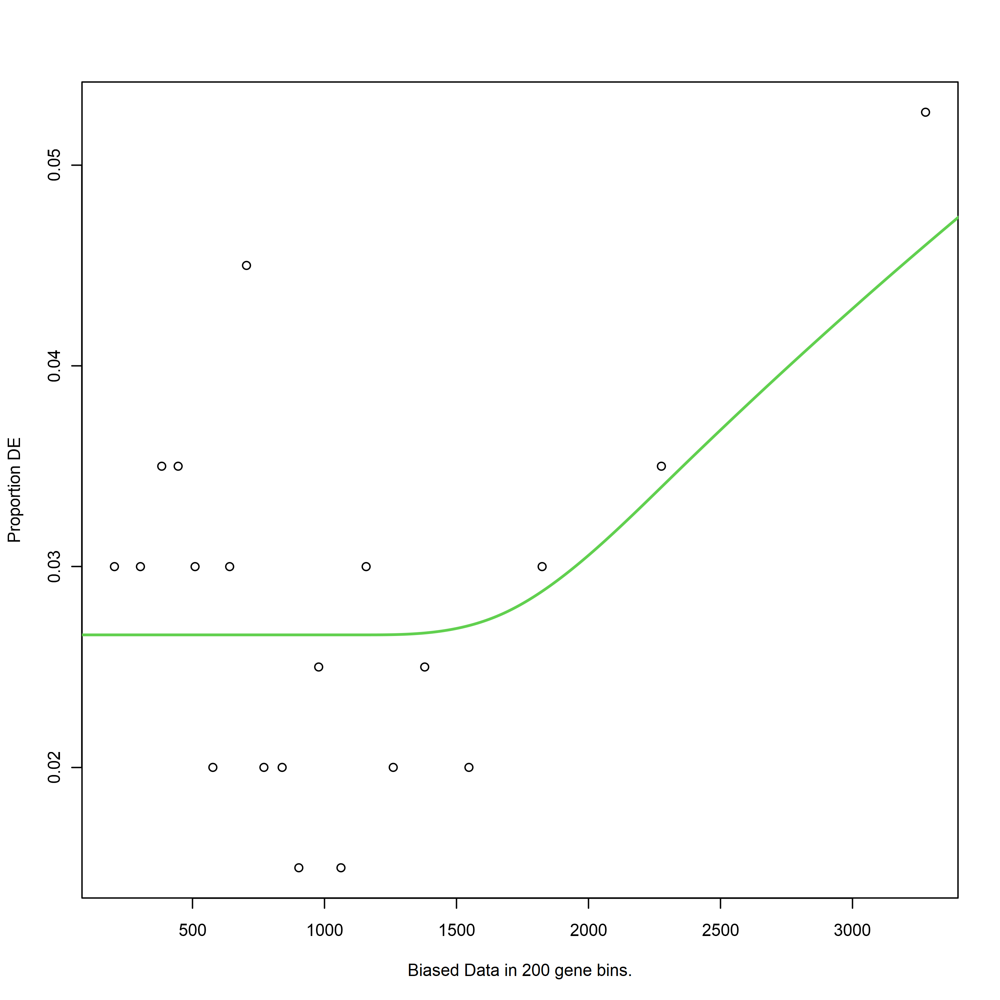

[1] "A2vsA1_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A2vsA1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


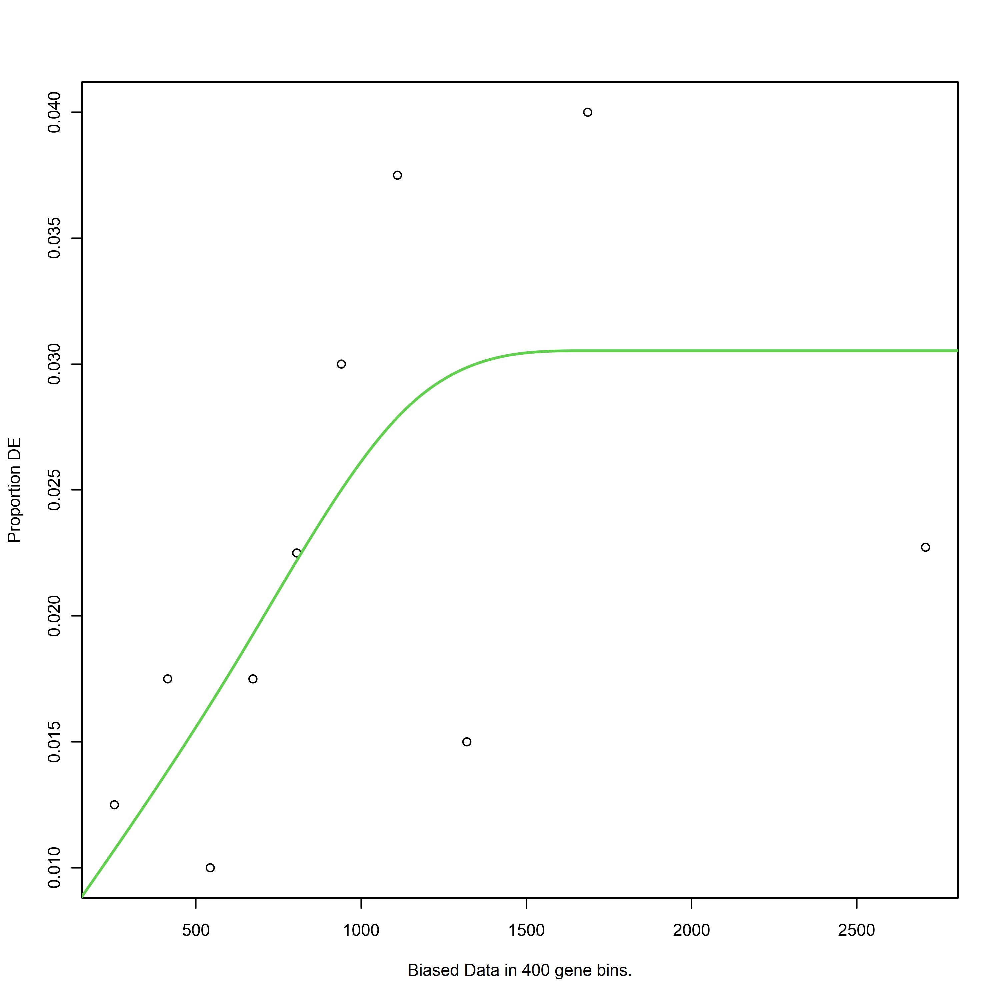

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



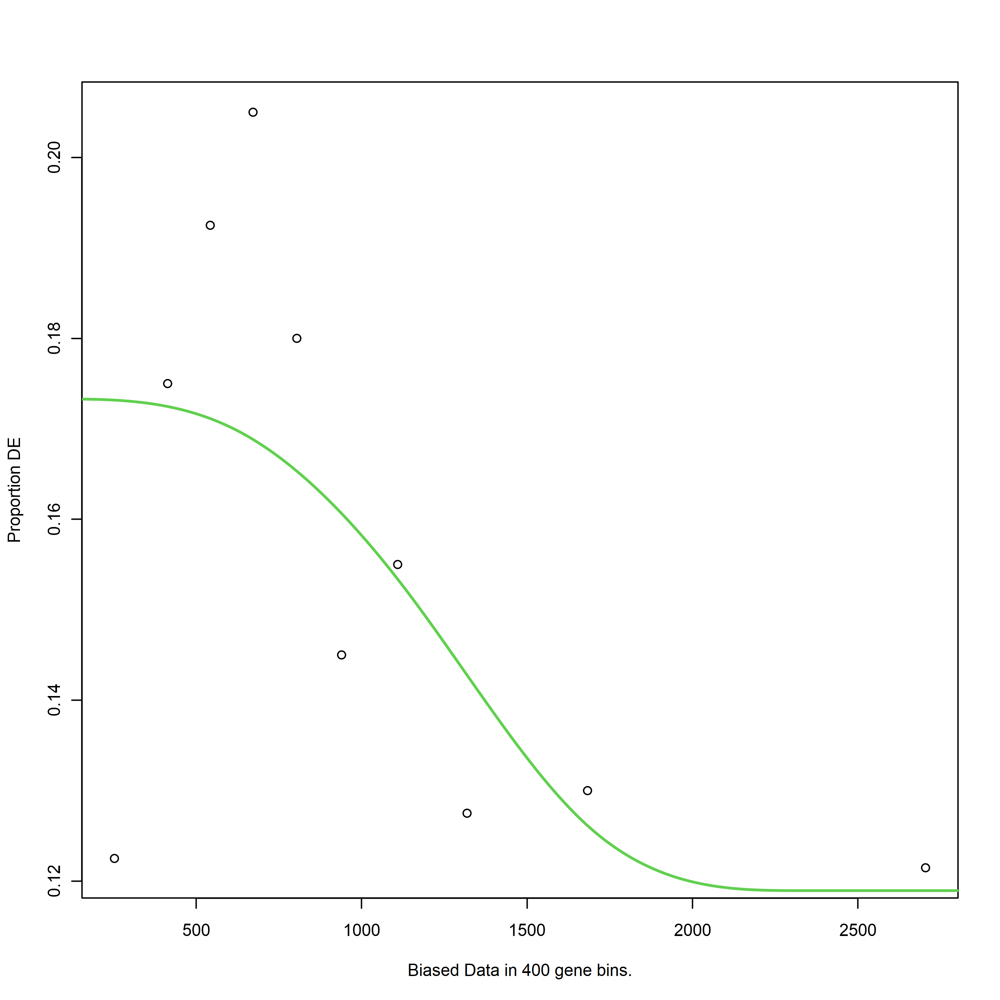

[1] "A3vsA1_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A3vsA1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


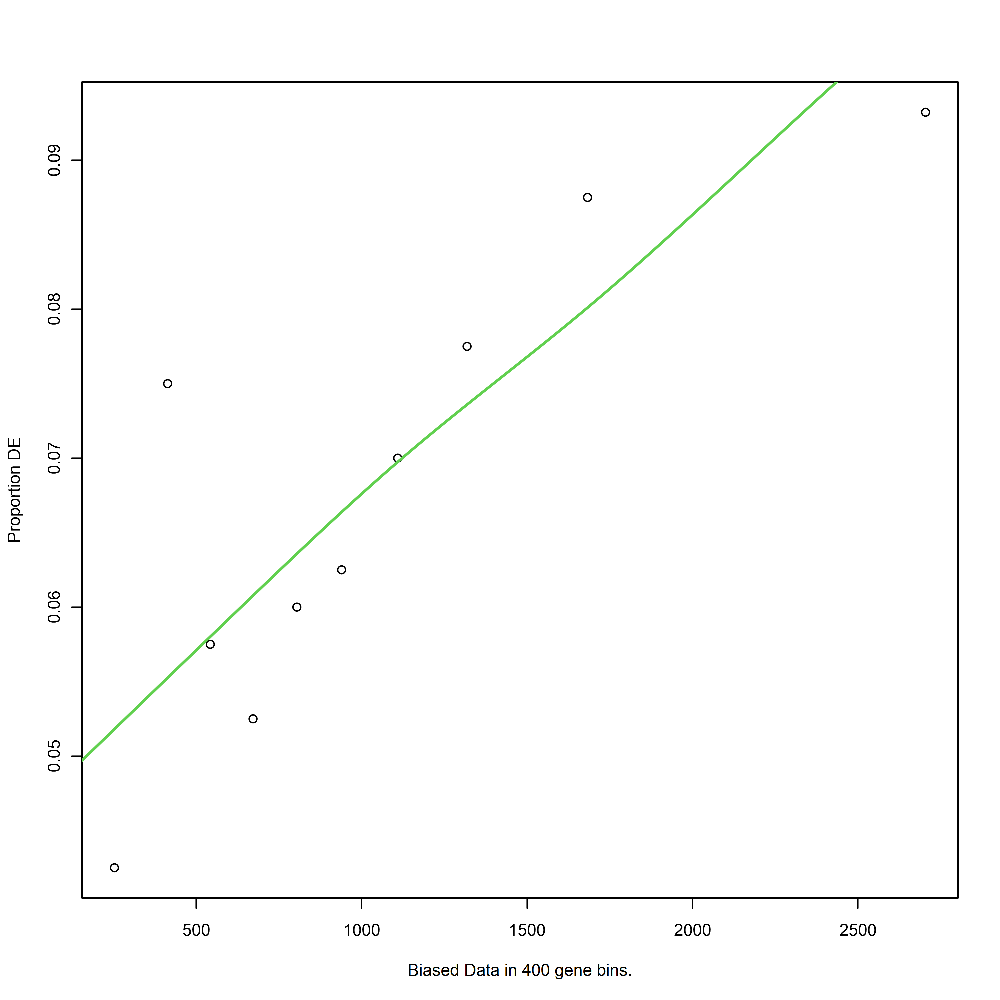

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



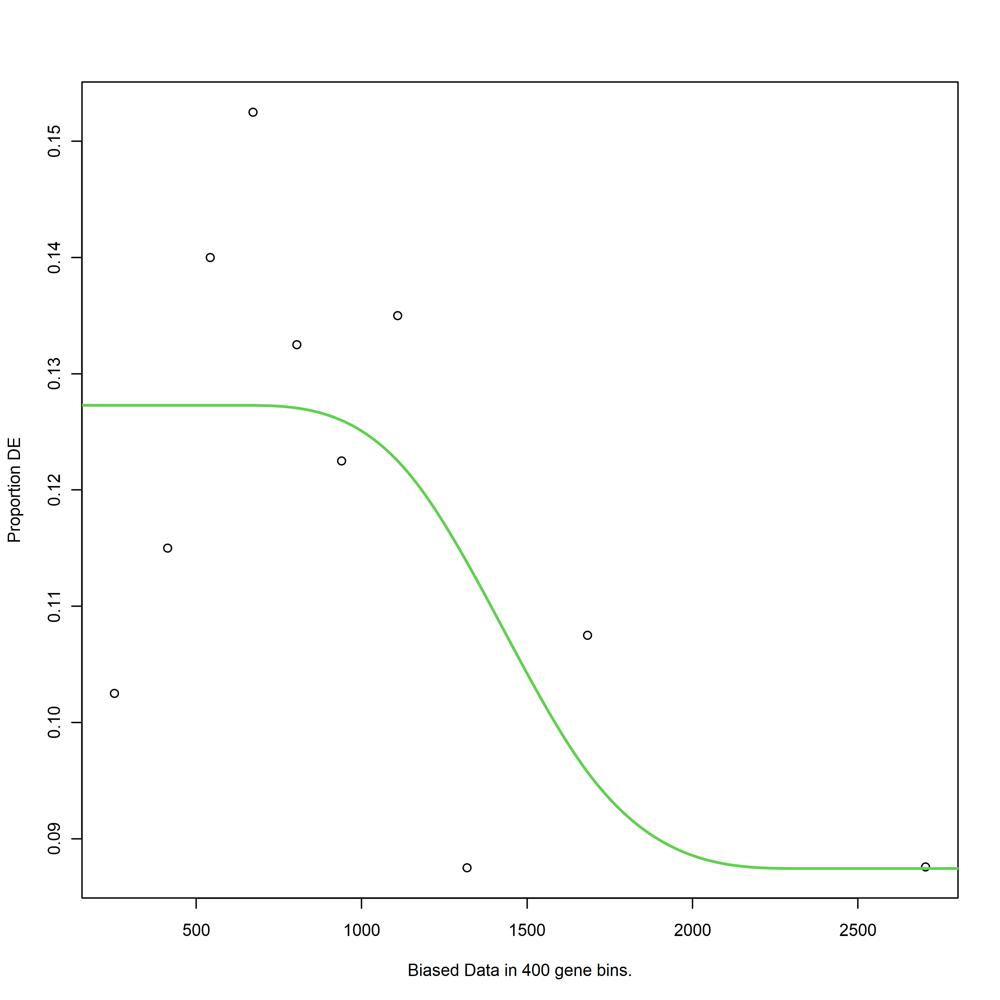

[1] "A3vsA2_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1456 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "A3vsA2_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


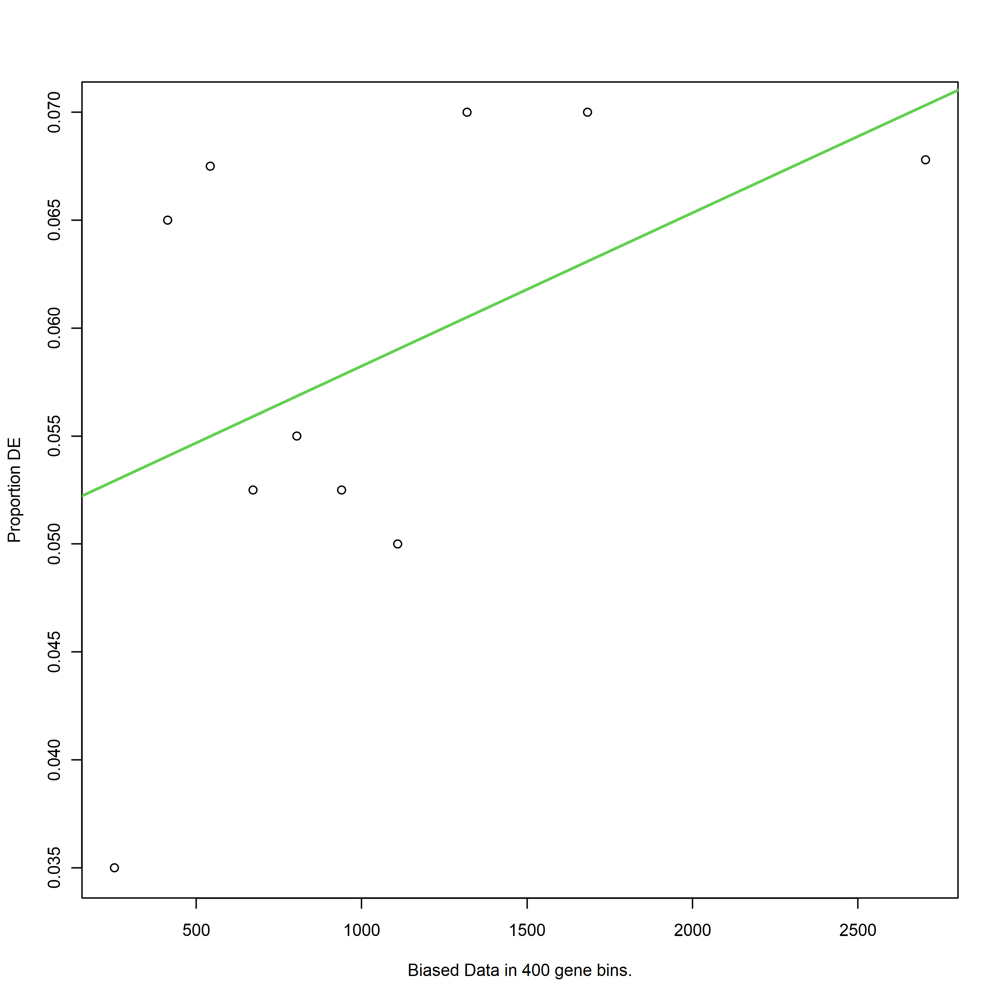

Using manually entered categories.

For 1456 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C1vsA1_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


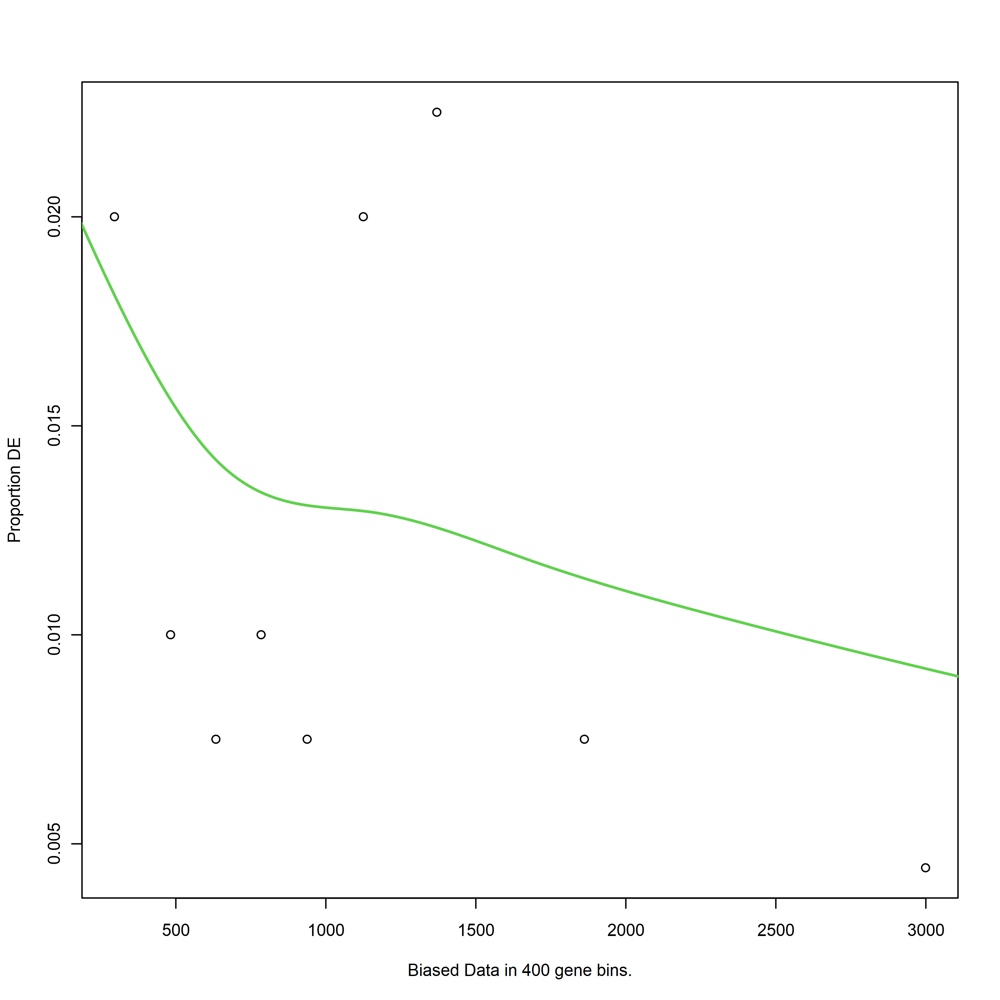

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C1vsA1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


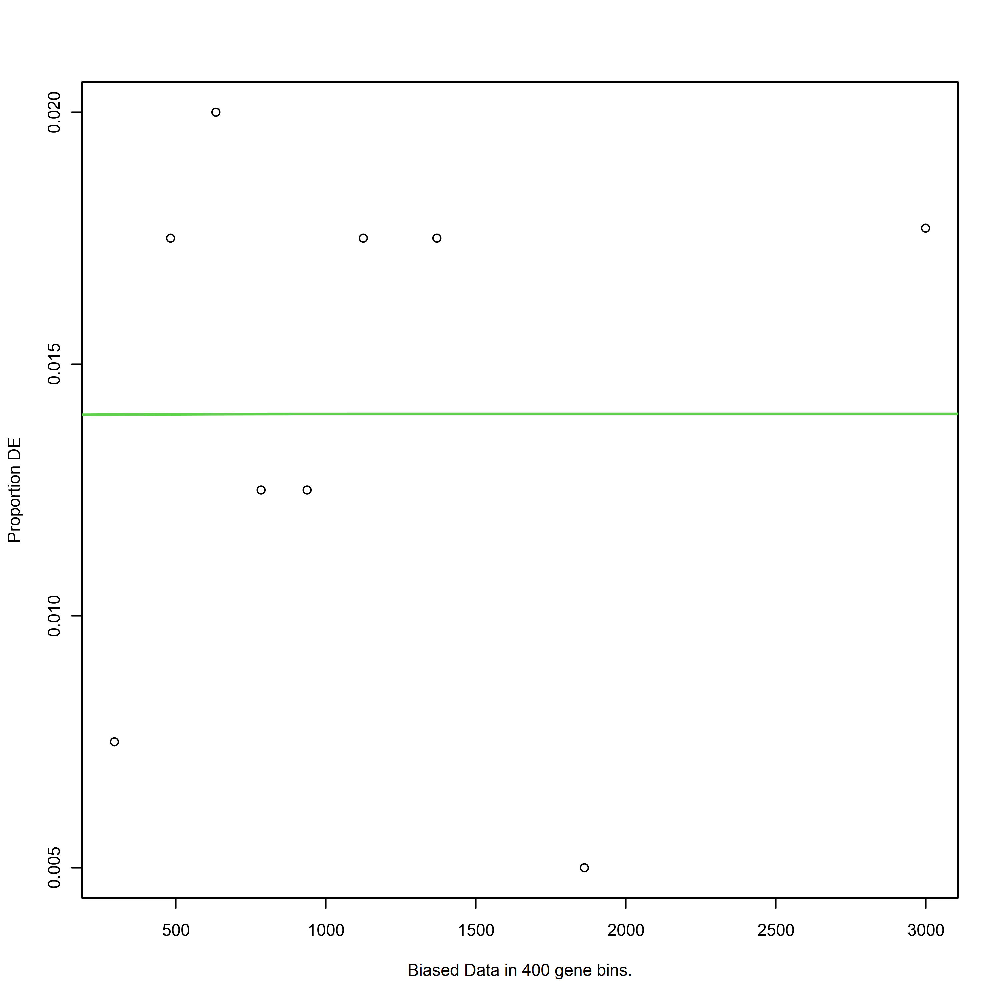

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



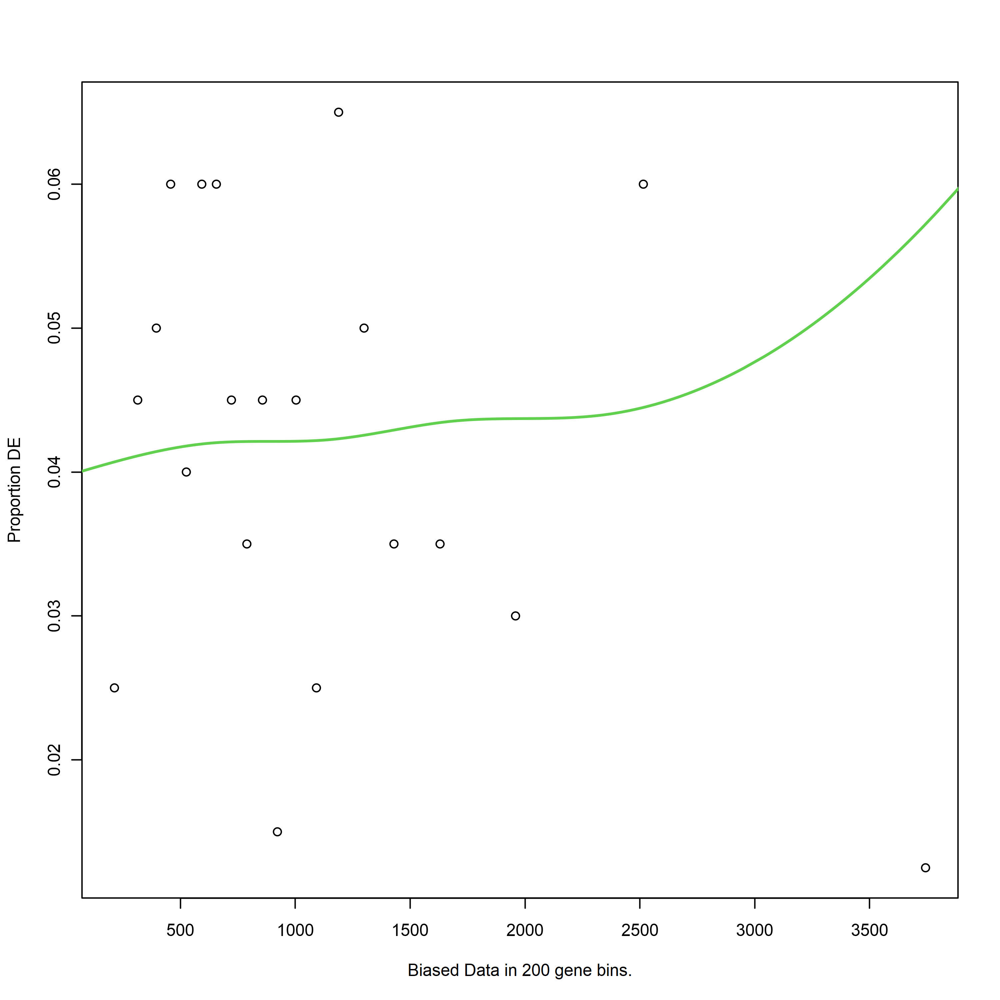

[1] "C2vsA2_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C2vsA2_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


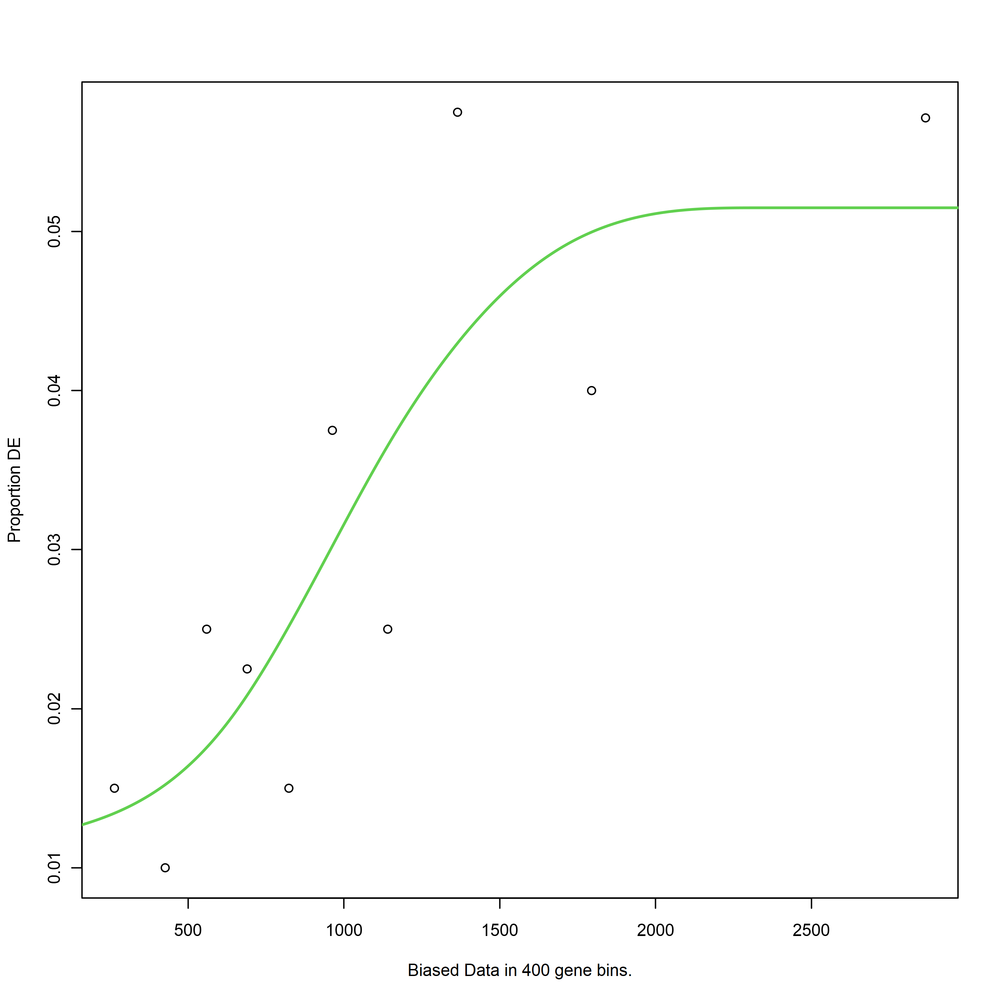

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsA3_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


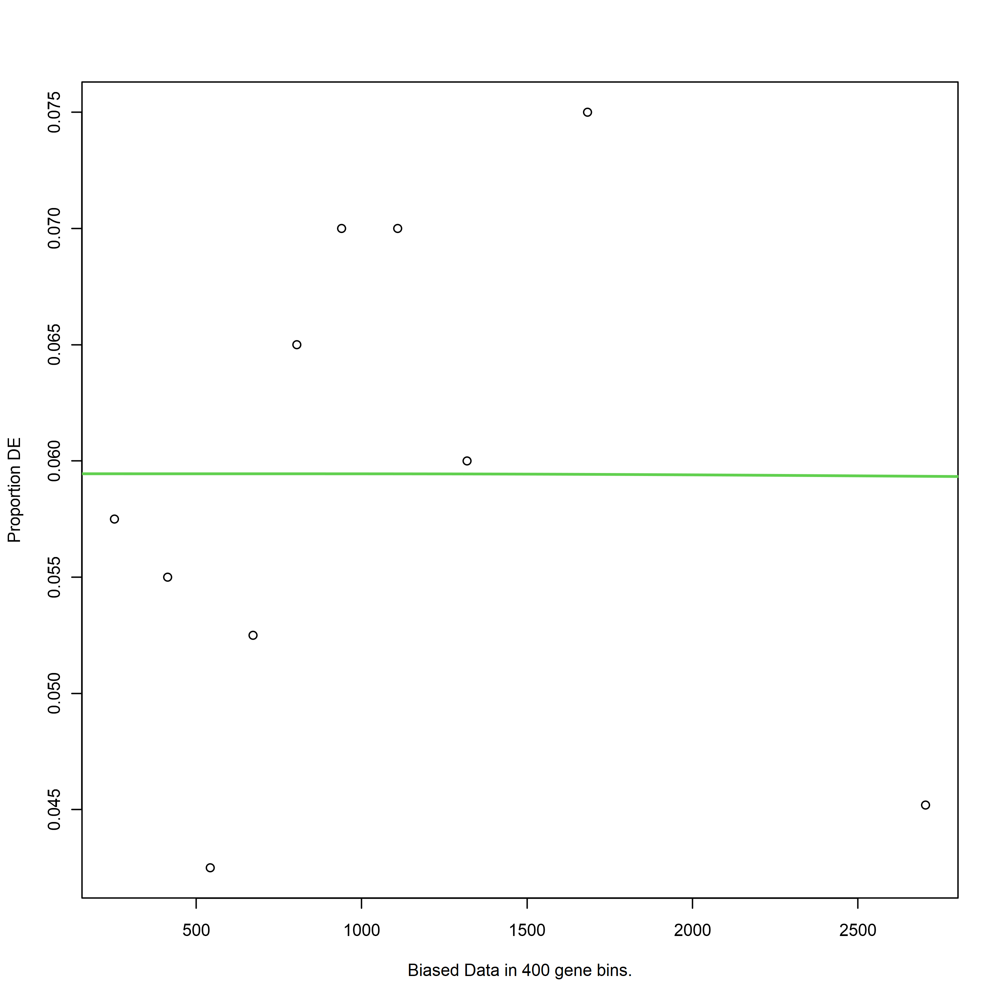

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsA3_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


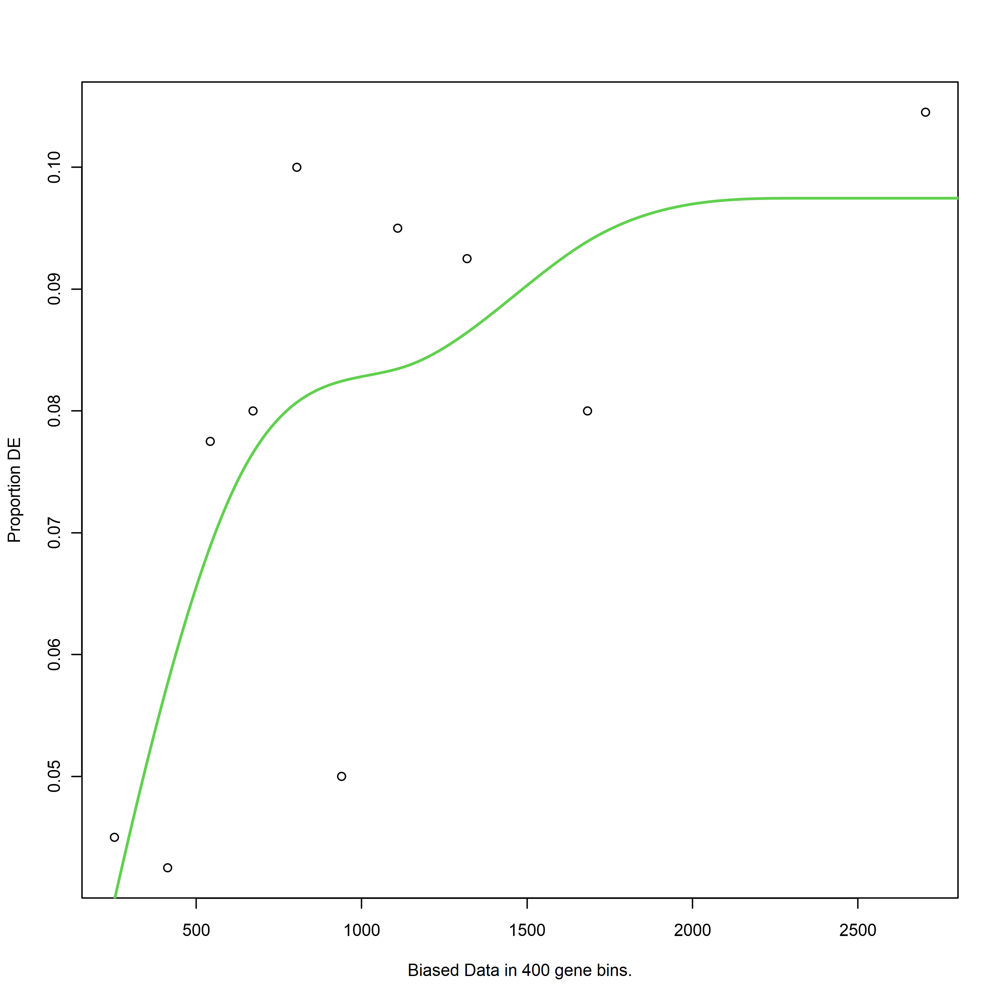

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C2vsC1_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


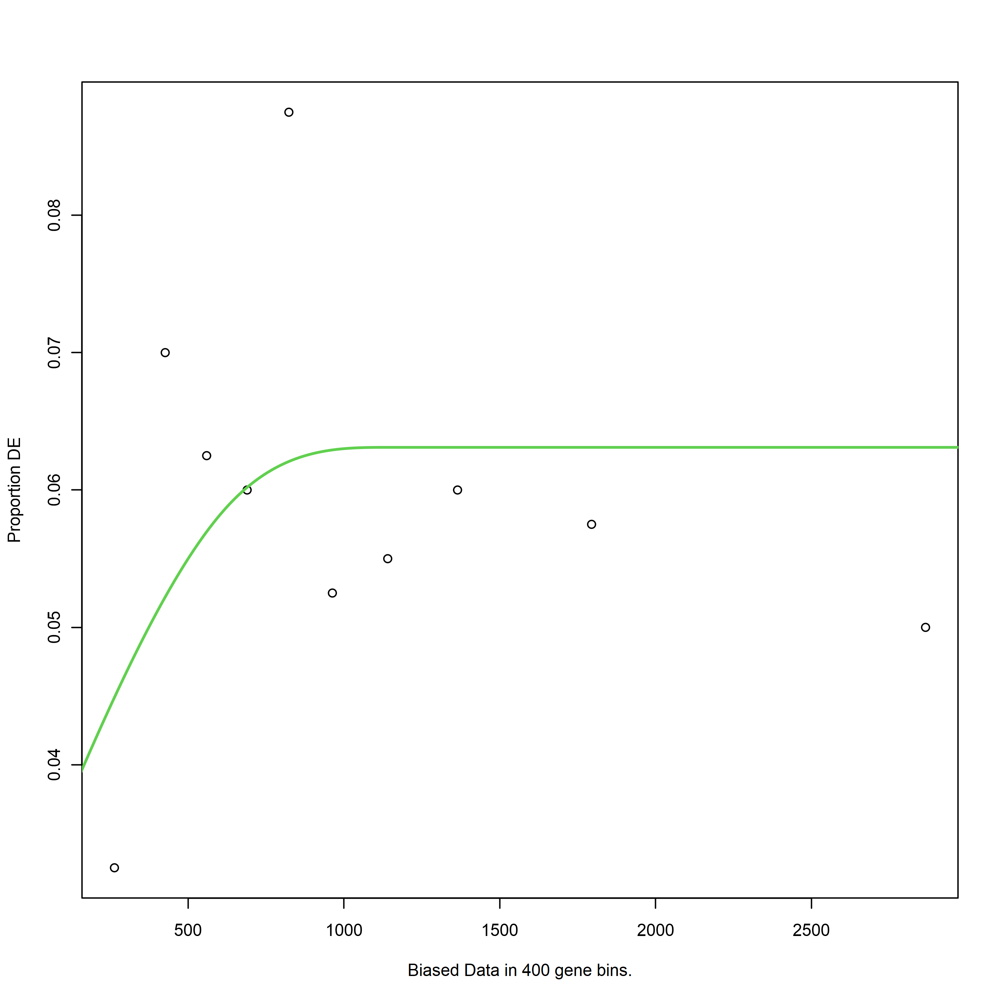

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C2vsC1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


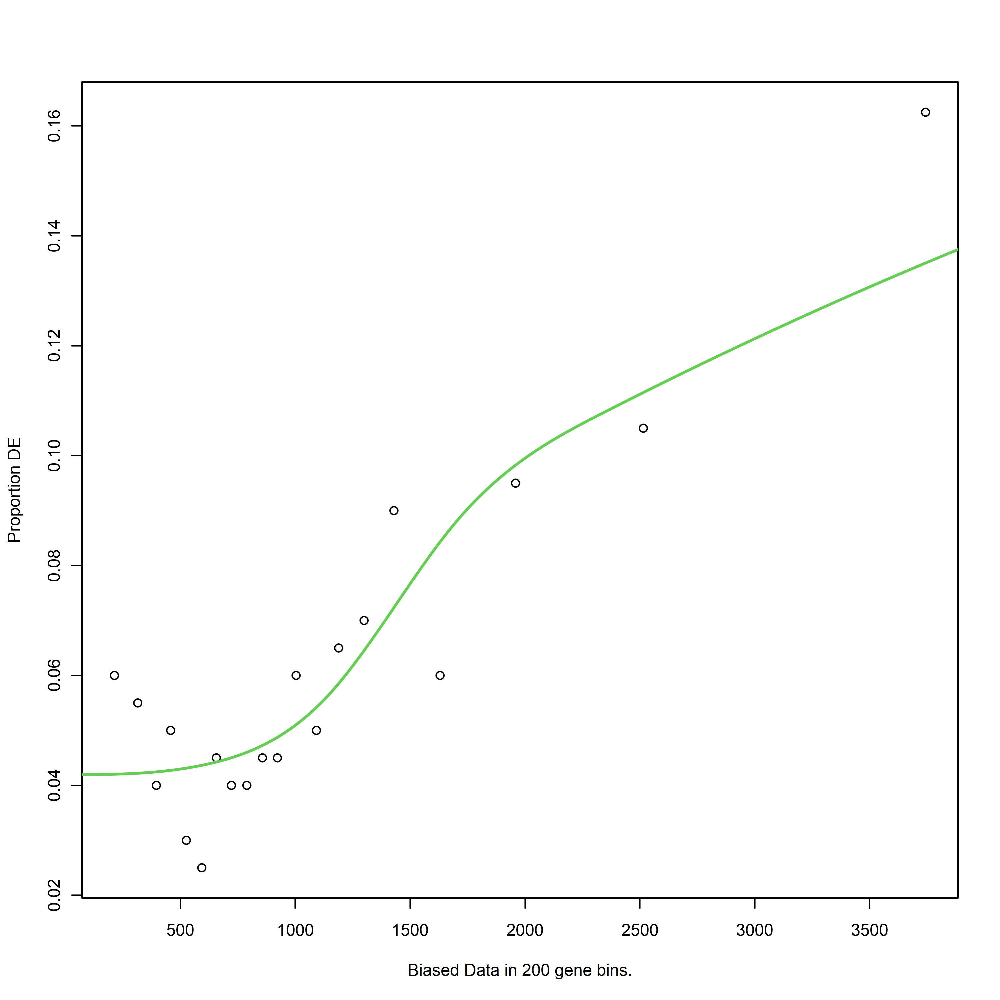

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC1_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


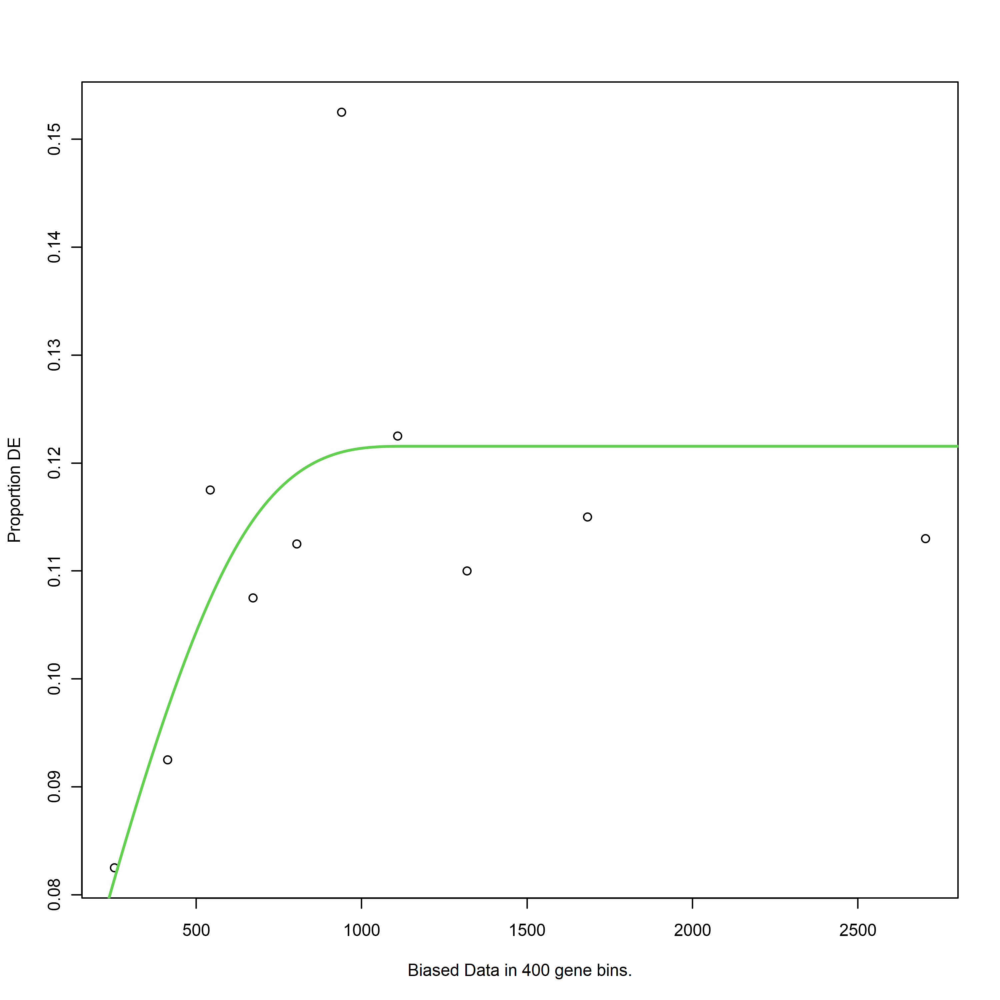

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


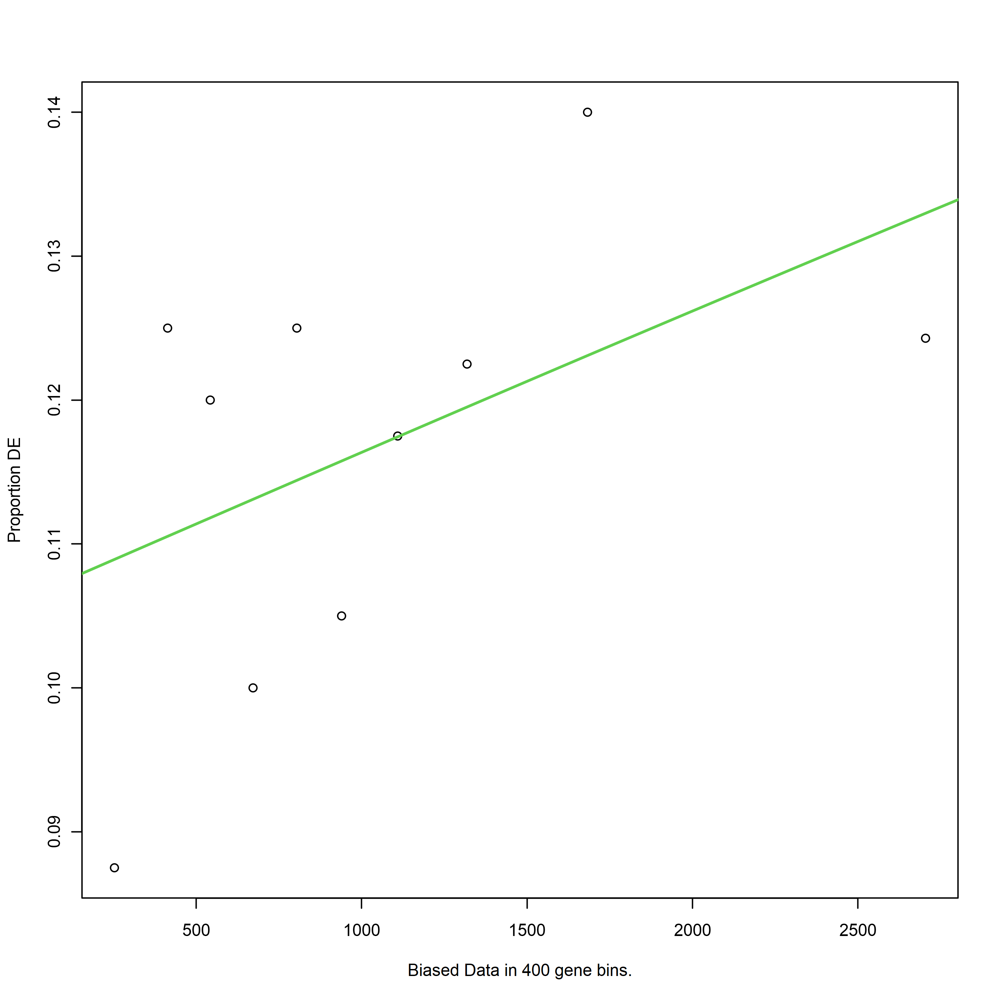

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC1_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


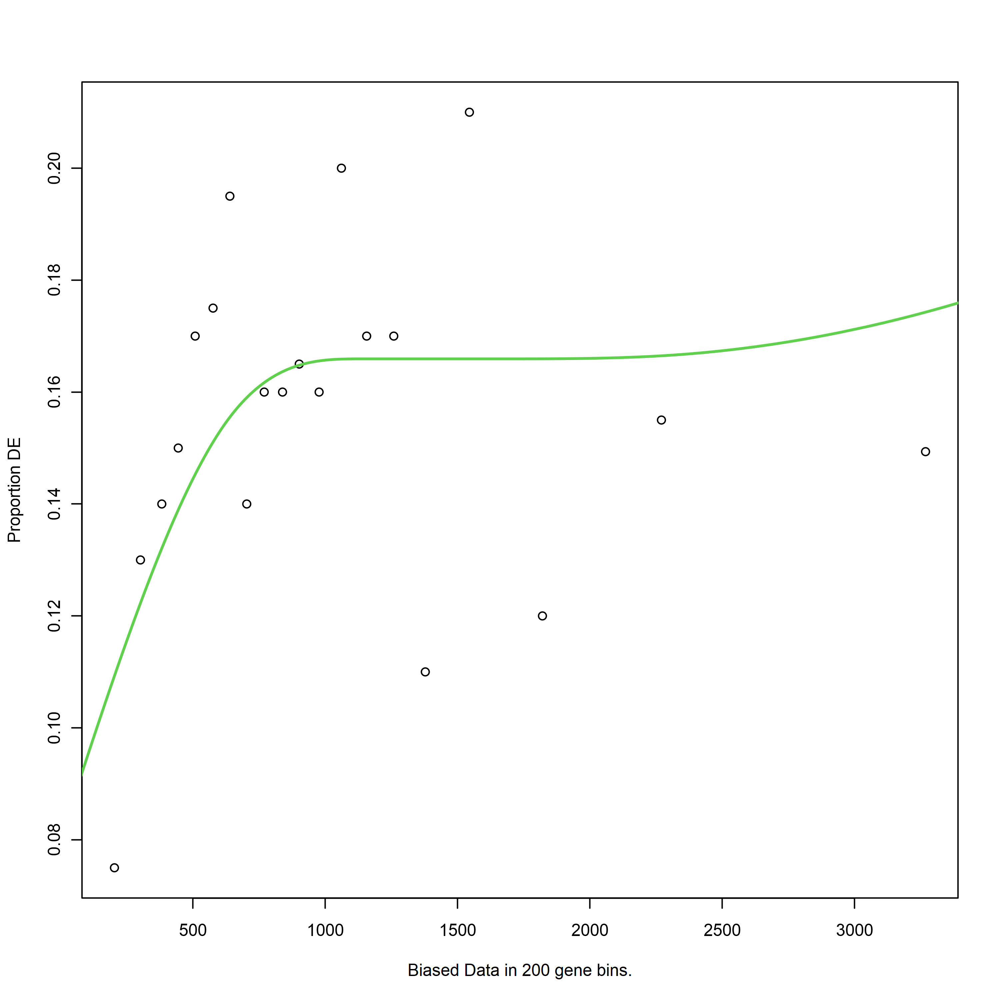

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



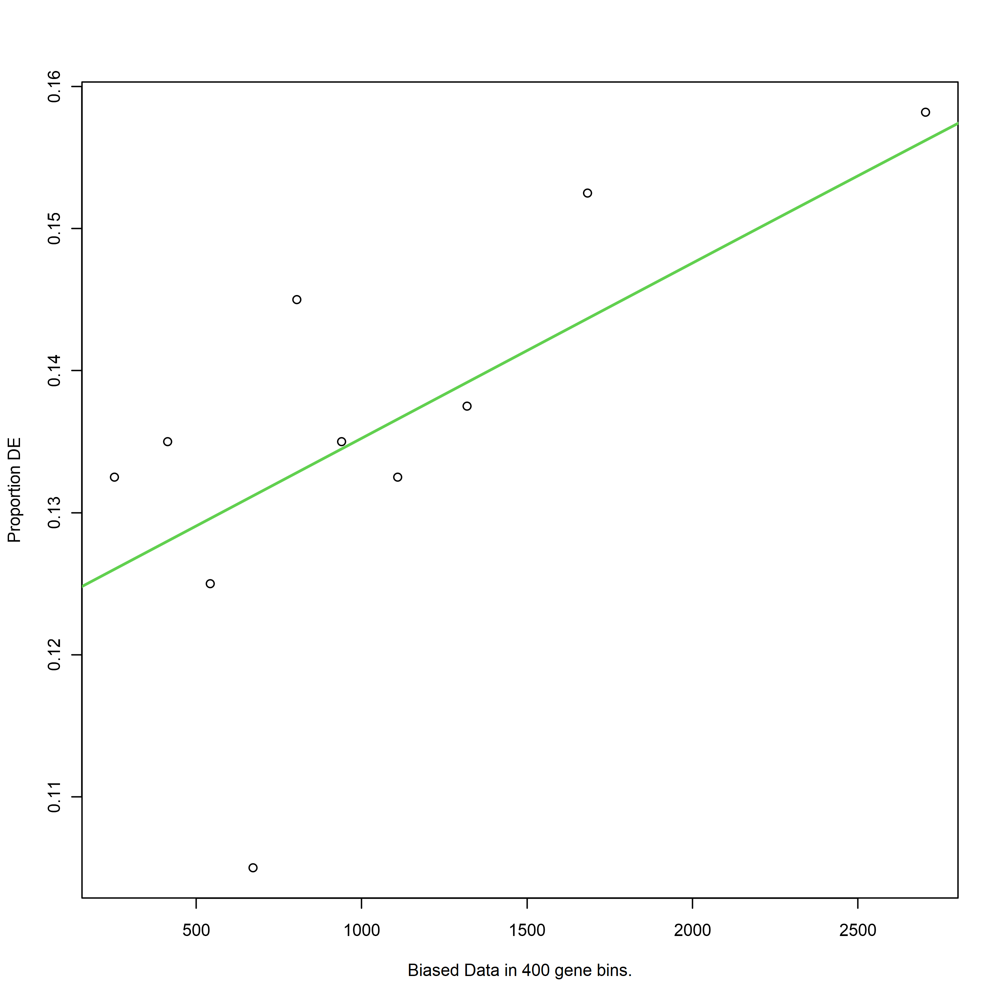

[1] "C4vsC1_rna"
[1] "path"
[1] "up"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



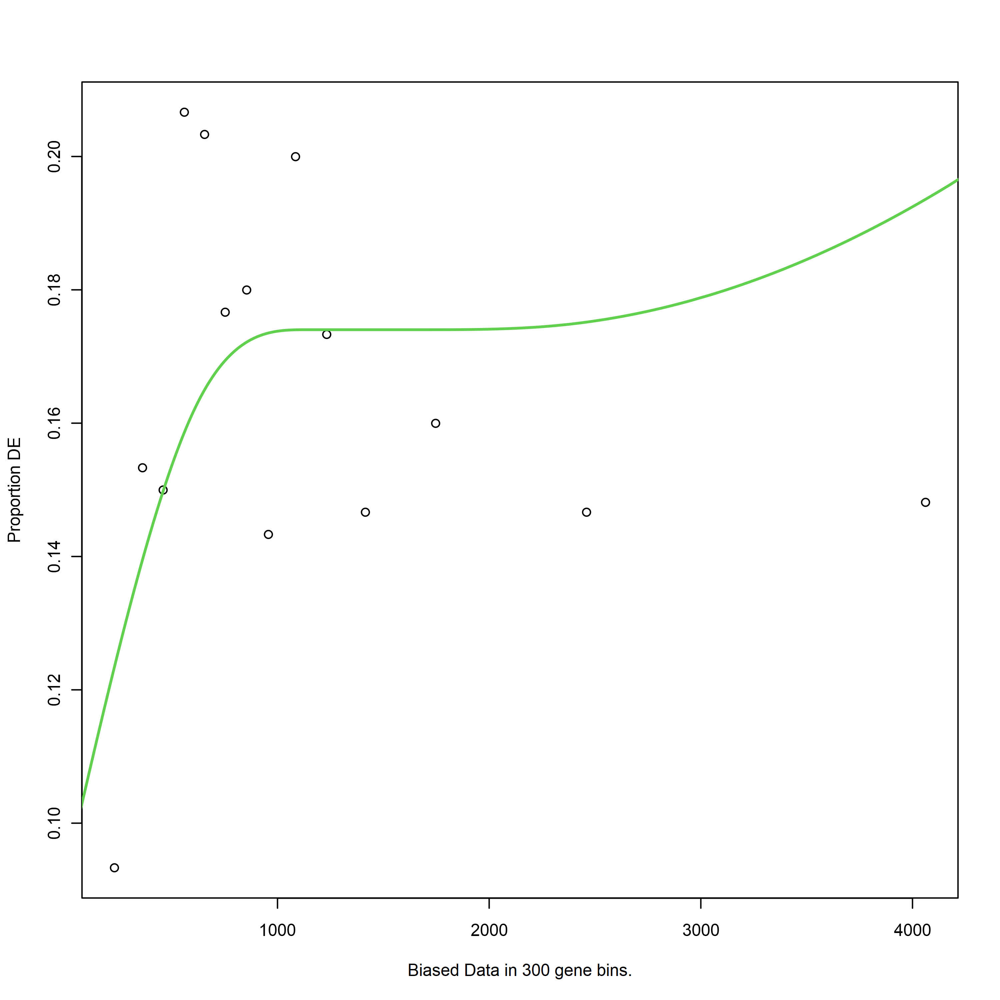

[1] "C5vsC1_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C5vsC1_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


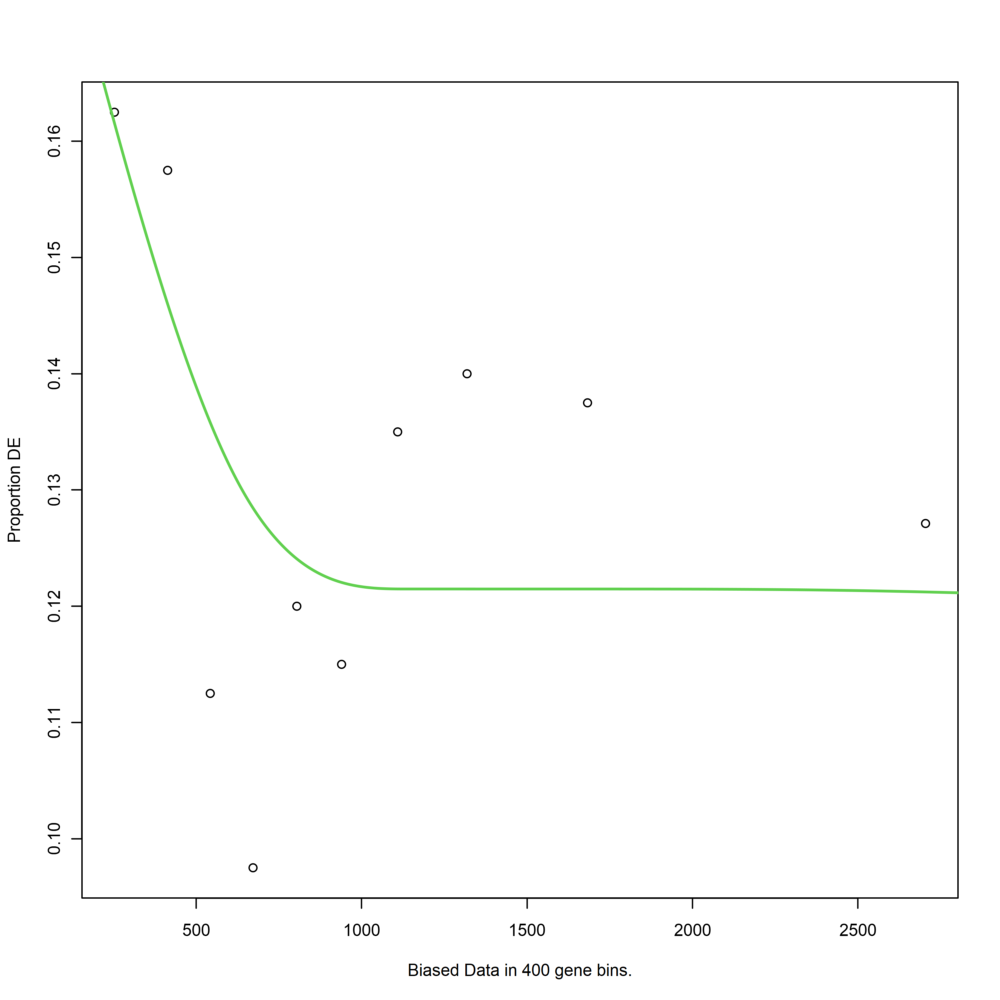

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C3vsC2_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


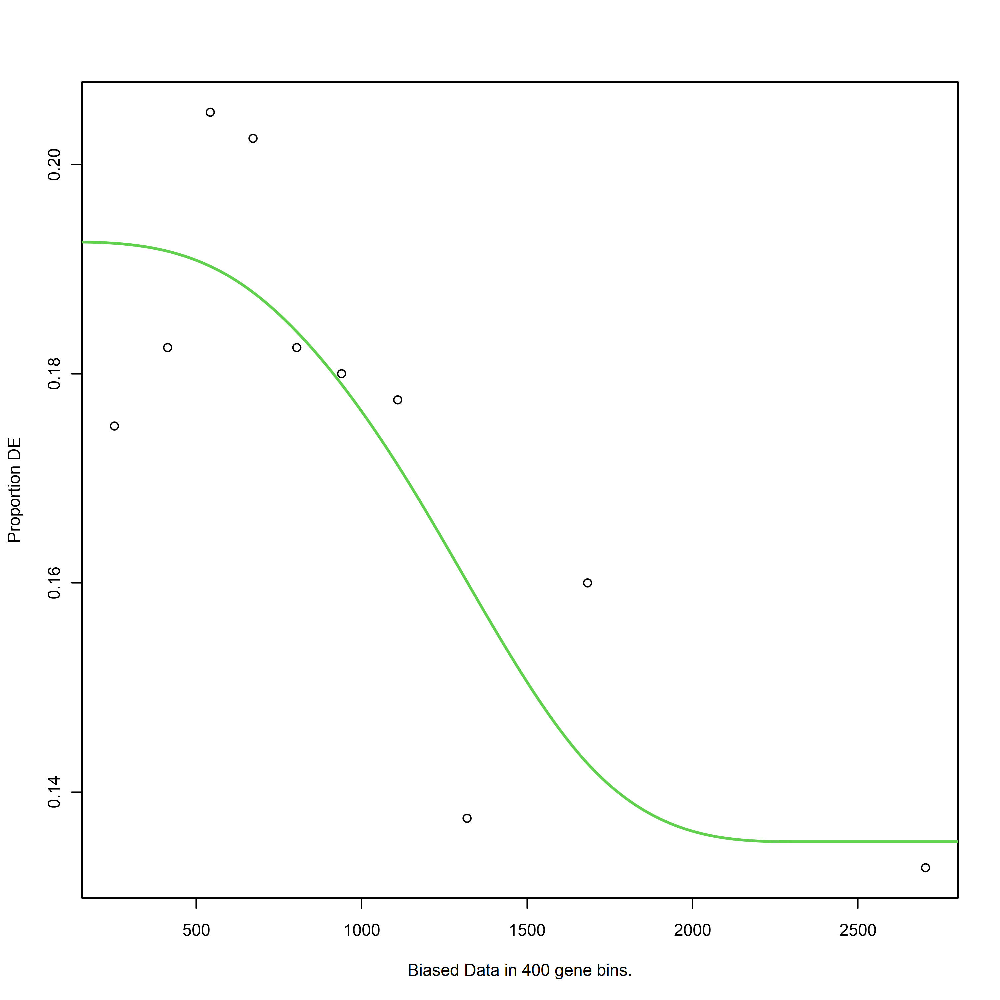

Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



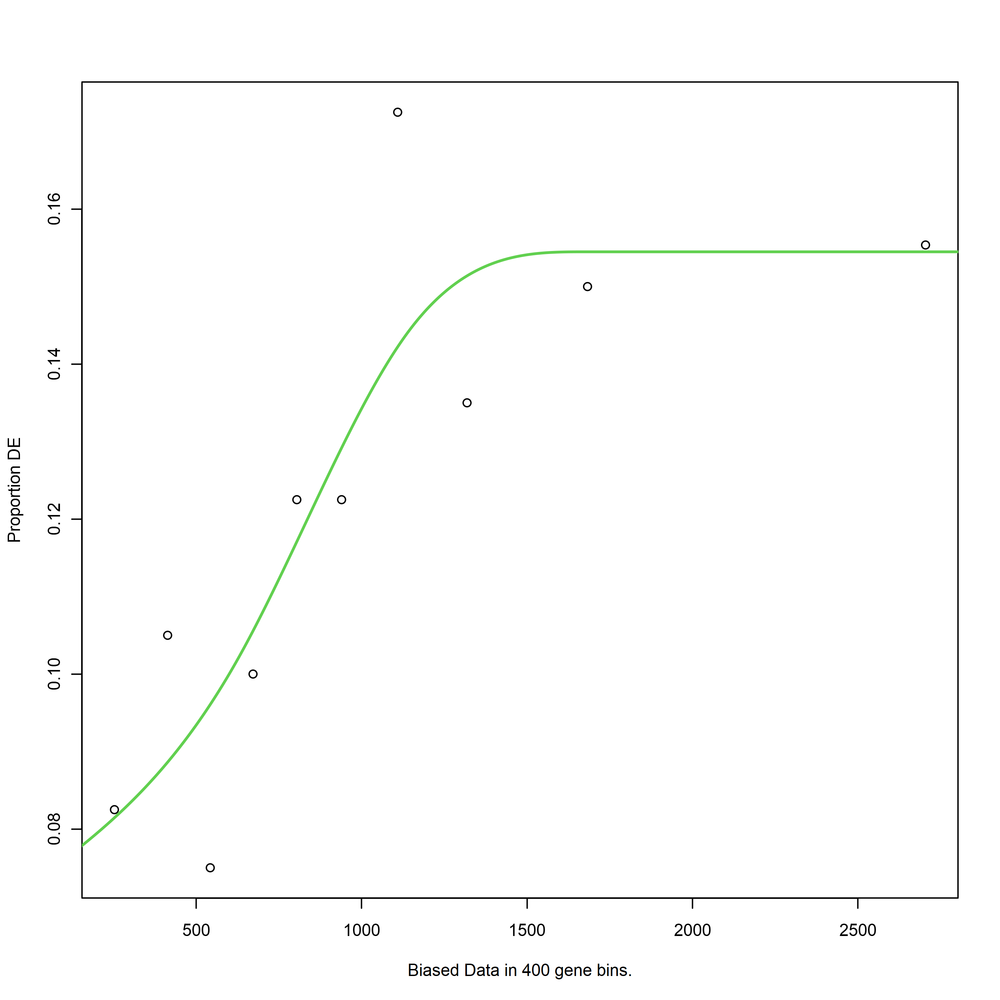

[1] "C3vsC2_rna"
[1] "path"
[1] "up"


Using manually entered categories.

For 1751 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC3_rna"
[1] "path"
[1] "down"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


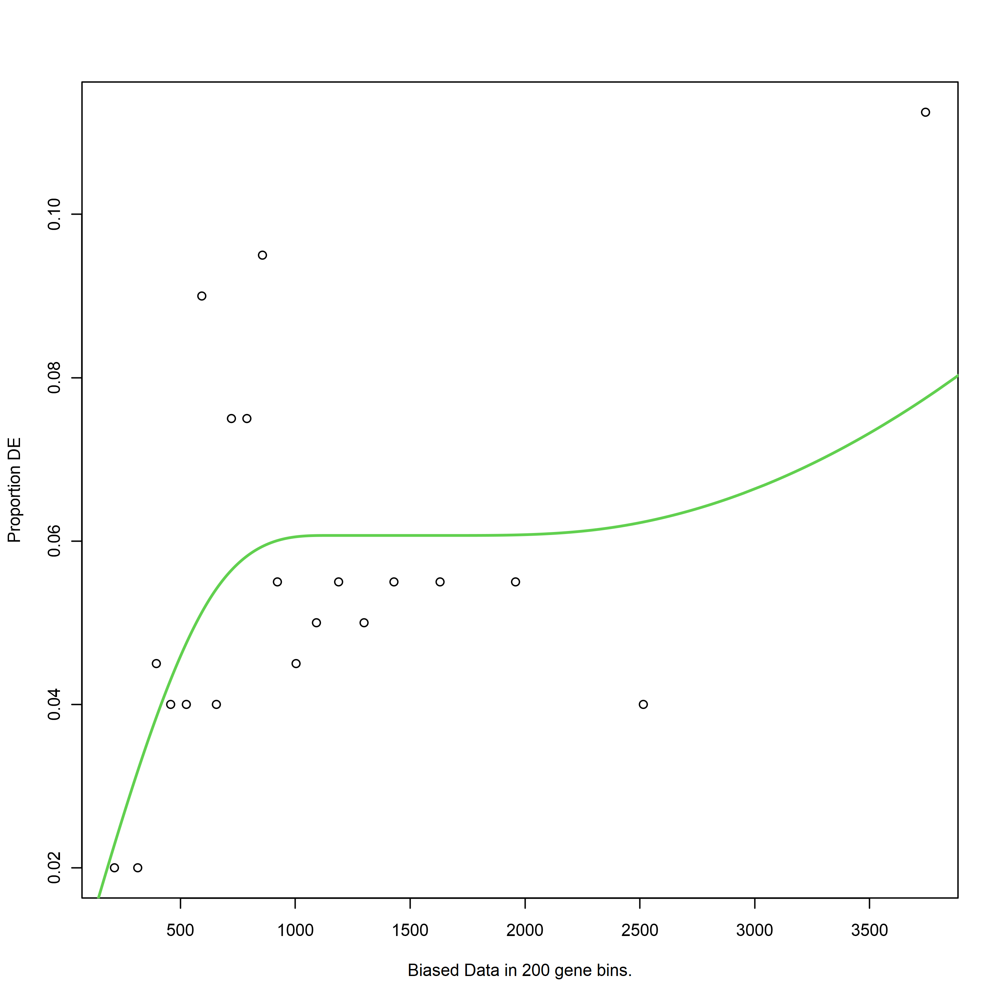

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



[1] "C4vsC3_rna"
[1] "path"
[1] "up"


Warning message in pcls(G):
"initial point very close to some inequality constraints"


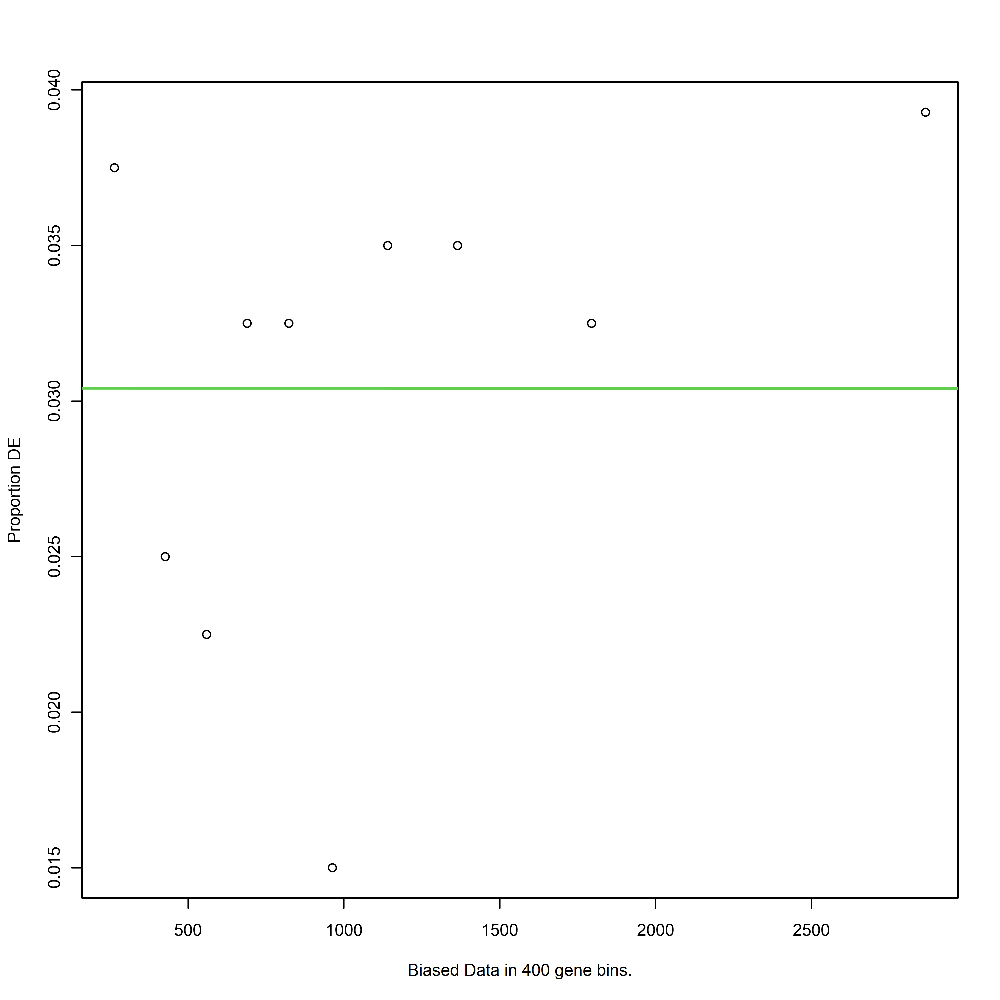

Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



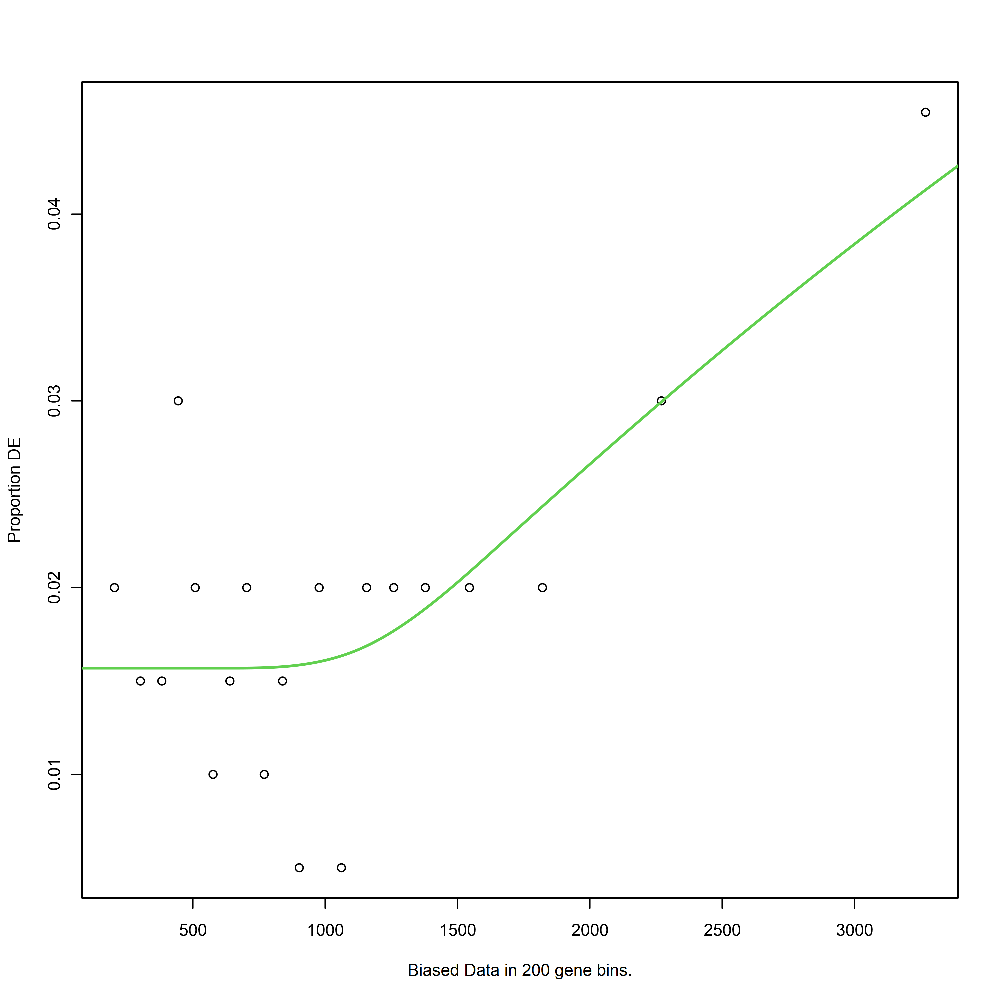

[1] "C5vsC4_rna"
[1] "path"
[1] "down"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



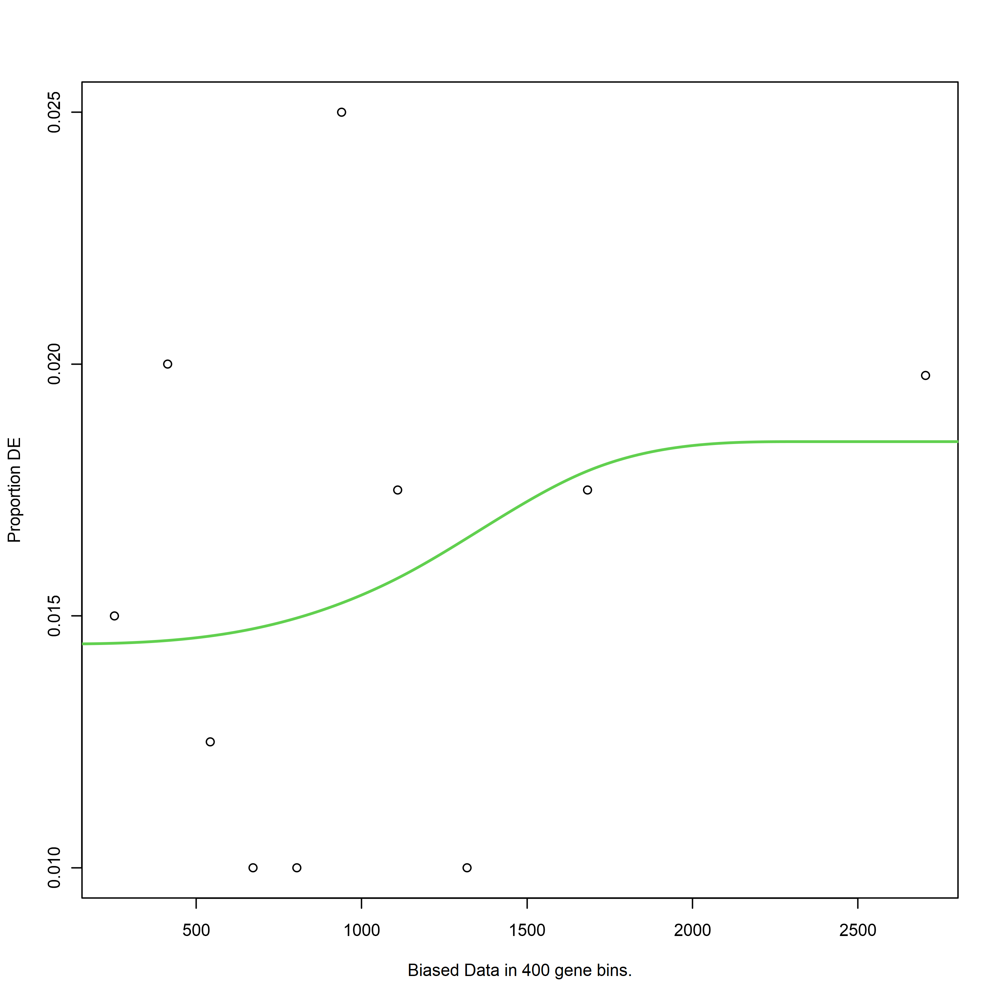

[1] "C5vsC4_rna"
[1] "path"
[1] "up"


Using manually entered categories.

For 1814 genes, we could not find any categories. These genes will be excluded.

To force their use, please run with use_genes_without_cat=TRUE (see documentation).

This was the default behavior for version 1.15.1 and earlier.

Calculating the p-values...



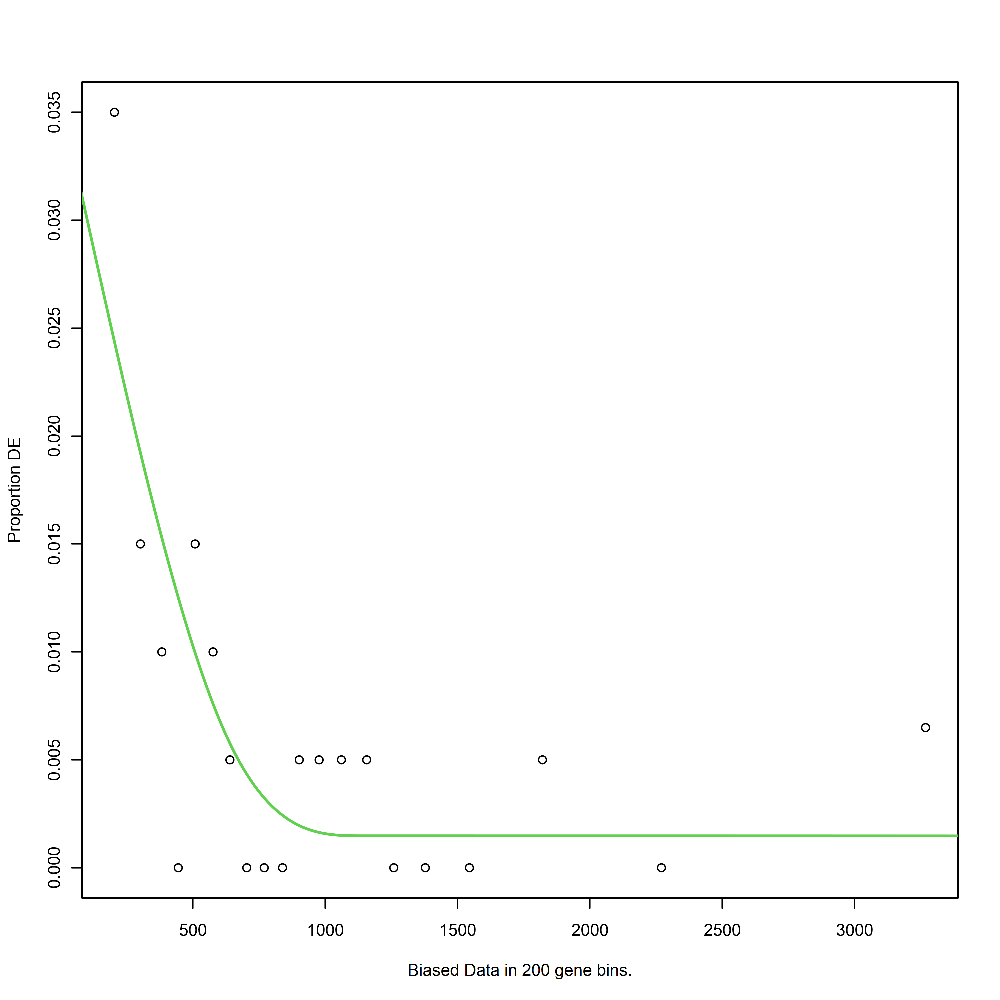

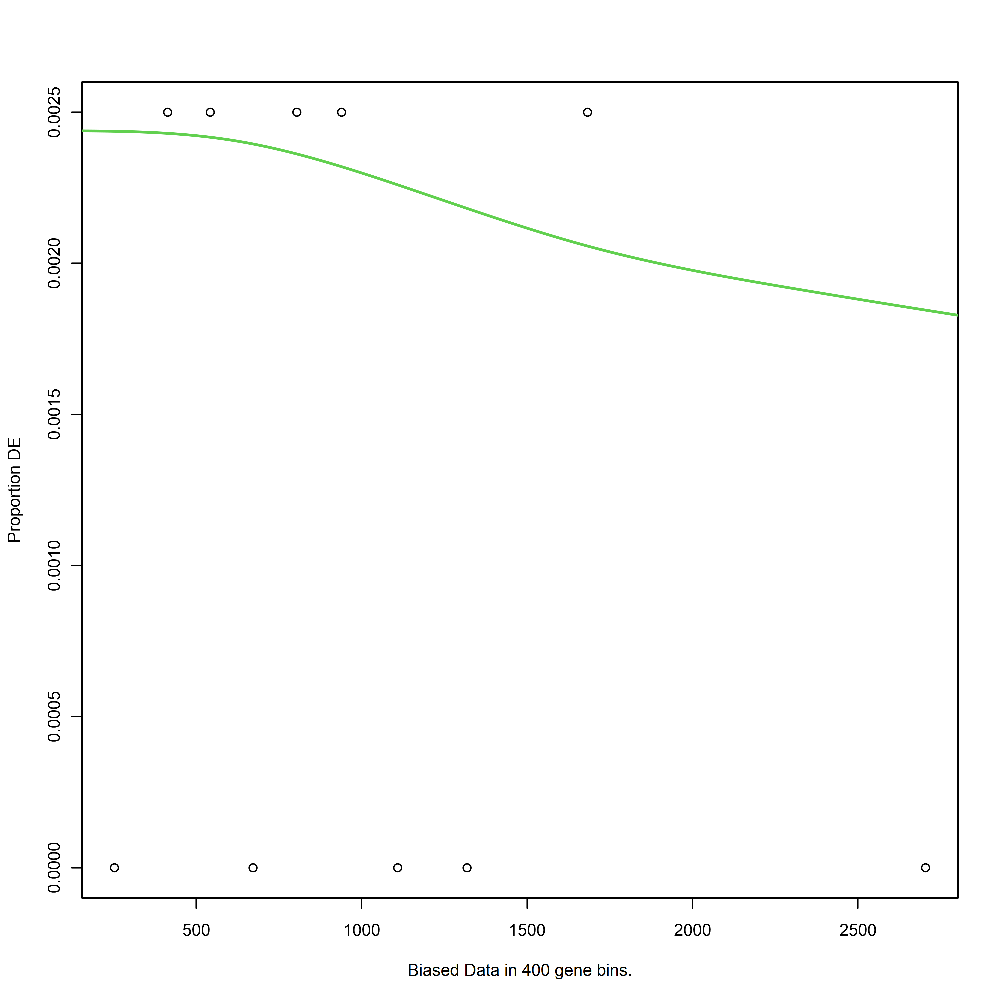

In [34]:
dlist = list()

for (contrastname in unique(df_all$contrast1)) 
{
    for (col in c('path')  #, 'main','ecpath')
             ) 
        {
        for (test in c('down', 'up')) #, 'is_de')) 
            {
              dlist[[length(dlist) + 1]] <- run_enrichment(contrastname, col, test)
        }

    }
}
goseq_res = bind_rows(dlist)


In [35]:
t(goseq_res)

category,03010,03011,00290,00250,04066,00970,04147,00010,02030,00260,⋯,99976,99977,99980,99982,99987,99992,99994,99995,99996,99997
over_represented_pvalue,4.895163e-10,4.895163e-10,4.723842e-04,2.285779e-03,3.987447e-03,6.372783e-03,6.843822e-03,6.962260e-03,8.873103e-03,1.104401e-02,⋯,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
padj,3.132904e-08,3.132904e-08,2.015506e-02,7.314494e-02,1.020786e-01,1.113962e-01,1.113962e-01,1.113962e-01,1.261952e-01,1.413634e-01,⋯,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
under_represented_pvalue,1.000000e+00,1.000000e+00,9.999565e-01,9.995431e-01,9.998414e-01,9.986531e-01,9.979453e-01,9.984664e-01,9.976574e-01,9.976268e-01,⋯,9.609246e-01,9.578345e-01,7.737709e-01,9.784082e-01,9.887112e-01,9.579098e-01,9.858108e-01,9.686610e-01,9.096232e-01,7.710806e-01
numDEInCat,18,18,6,8,3,7,10,7,8,6,⋯,0,0,0,0,0,0,0,0,0,0
numInCat,51,51,13,27,5,23,48,26,35,25,⋯,17,20,109,9,5,18,6,14,40,107
type,down,down,down,down,down,down,down,down,down,down,⋯,up,up,up,up,up,up,up,up,up,up
enrich,path,path,path,path,path,path,path,path,path,path,⋯,path,path,path,path,path,path,path,path,path,path
contrast,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,⋯,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna,C5vsC4_rna
organism,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,⋯,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3


In [36]:
duplicated_sub_list = c("09102 Energy metabolism", "09181 Protein families: metabolism", 
"09183 Protein families: signaling and cellular processes", "09191 Unclassified: metabolism", 
"09193 Unclassified: signaling and cellular processes")
duplicated_category_list = c( "Energy/Carbohydrate/Glycan", "Env. Info/Cellular Process", "Metabolism" )

sub_names_df = kegg_df %>% 
    distinct(main, sub, Category)  %>% filter(main != '') %>%
    #mutate(duplicate = (Category %in% duplicated_sub_list) | !(Category %in% duplicated_category_list))
    filter(!(
        (sub %in% duplicated_sub_list) & 
        !(Category %in% duplicated_category_list)
    )) %>%
    filter(!(
        (sub == '09191 Unclassified: metabolism') & !(Category  == 'Energy/Carbohydrate/Glycan')
    )) %>%
    mutate(
        PATH = sub,
        enrich = 'sub',
        category = word(PATH)
    )
    
path_names_df  = kegg_df %>% 
    distinct(main, sub, path, Category)  %>% filter(main != '') %>%
    
    mutate(
        PATH = path,
        enrich = 'path',
        category = word(PATH)
    )


final_names_df = bind_rows(sub_names_df, path_names_df) 

In [37]:
final_names_df %>% filter(category %in% (final_names_df %>% count(category) %>% filter(n>1))$category) %>% arrange(category)

main,sub,Category,PATH,enrich,category,path
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>


In [38]:
goseq_res = left_join(goseq_res, final_names_df, by=c('category', 'enrich')) 

In [39]:
goseq_res

category,over_represented_pvalue,padj,under_represented_pvalue,numDEInCat,numInCat,type,enrich,contrast,organism,main,sub,Category,PATH,path
<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
03010,4.895163e-10,3.132904e-08,1.0000000,18,51,down,path,C2vsC1_prot,HOT1A3,09120 Genetic Information Processing,09122 Translation,Genetic Info,03010 Ribosome [PATH:ko03010],03010 Ribosome [PATH:ko03010]
03011,4.895163e-10,3.132904e-08,1.0000000,18,51,down,path,C2vsC1_prot,HOT1A3,09180 Brite Hierarchies,09182 Protein families: genetic information processing,Genetic Info,03011 Ribosome [BR:ko03011],03011 Ribosome [BR:ko03011]
00290,4.723842e-04,2.015506e-02,0.9999565,6,13,down,path,C2vsC1_prot,HOT1A3,09100 Metabolism,09105 Amino acid metabolism,AA/Nucleotide,"00290 Valine, leucine and isoleucine biosynthesis [PATH:ko00290]","00290 Valine, leucine and isoleucine biosynthesis [PATH:ko00290]"
00250,2.285779e-03,7.314494e-02,0.9995431,8,27,down,path,C2vsC1_prot,HOT1A3,09100 Metabolism,09105 Amino acid metabolism,AA/Nucleotide,"00250 Alanine, aspartate and glutamate metabolism [PATH:ko00250]","00250 Alanine, aspartate and glutamate metabolism [PATH:ko00250]"
04066,3.987447e-03,1.020786e-01,0.9998414,3,5,down,path,C2vsC1_prot,HOT1A3,09130 Environmental Information Processing,09132 Signal transduction,Env. Info/Cellular Process,04066 HIF-1 signaling pathway [PATH:ko04066],04066 HIF-1 signaling pathway [PATH:ko04066]
00970,6.372783e-03,1.113962e-01,0.9986531,7,23,down,path,C2vsC1_prot,HOT1A3,09120 Genetic Information Processing,09122 Translation,Genetic Info,00970 Aminoacyl-tRNA biosynthesis [PATH:ko00970],00970 Aminoacyl-tRNA biosynthesis [PATH:ko00970]
04147,6.843822e-03,1.113962e-01,0.9979453,10,48,down,path,C2vsC1_prot,HOT1A3,09180 Brite Hierarchies,09183 Protein families: signaling and cellular processes,Env. Info/Cellular Process,04147 Exosome [BR:ko04147],04147 Exosome [BR:ko04147]
00010,6.962260e-03,1.113962e-01,0.9984664,7,26,down,path,C2vsC1_prot,HOT1A3,09100 Metabolism,09101 Carbohydrate metabolism,Energy/Carbohydrate/Glycan,00010 Glycolysis / Gluconeogenesis [PATH:ko00010],00010 Glycolysis / Gluconeogenesis [PATH:ko00010]
02030,8.873103e-03,1.261952e-01,0.9976574,8,35,down,path,C2vsC1_prot,HOT1A3,09140 Cellular Processes,09142 Cell motility,Motility,02030 Bacterial chemotaxis [PATH:ko02030],02030 Bacterial chemotaxis [PATH:ko02030]


In [40]:
goseq_res = goseq_res %>% 
    extract(PATH, c("pathway"), "^[[:digit:]]* *([^\\[]+) *\\[?", remove = FALSE) %>%
#    extract(main, c("Category"), "^[[:digit:]]* *([^\\[]+) *\\[?", remove = FALSE) %>%
#    mutate(pathway = str_replace(pathway, "in photosynthetic organisms", "")) %>%
#    mutate(Category = word(Category)) %>%
    mutate(pathway = str_trim(pathway), #Category = str_trim(Category)
          ) 



In [41]:
goseq_res = goseq_res %>% 
    extract(sub, c("module"), "^[[:digit:]]* *([^\\[]+) *\\[?", remove = FALSE) %>%
    mutate(module = str_replace(module, "in photosynthetic organisms", "")) %>%
    mutate(module = str_replace(module, "metabolism", "")) %>%
    mutate(module = str_replace(module, "Biosynthesis of", "")) %>%
    mutate(module = str_replace(module, "Metabolism of", "")) %>%
    mutate(module = str_replace(module, "biosynthesis", "")) %>%
    mutate(module = str_trim(module)) 



In [42]:
t(head(goseq_res))

,1,2,3,4,5,6
category,03010,03011,00290,00250,04066,00970
over_represented_pvalue,4.895163e-10,4.895163e-10,4.723842e-04,2.285779e-03,3.987447e-03,6.372783e-03
padj,3.132904e-08,3.132904e-08,2.015506e-02,7.314494e-02,1.020786e-01,1.113962e-01
under_represented_pvalue,1.0000000,1.0000000,0.9999565,0.9995431,0.9998414,0.9986531
numDEInCat,18,18,6,8,3,7
numInCat,51,51,13,27,5,23
type,down,down,down,down,down,down
enrich,path,path,path,path,path,path
contrast,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot,C2vsC1_prot
organism,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3,HOT1A3


In [43]:
goseq_res %>% write_csv(file.path('DE_results', 'HOT1A3_GOSEQ_results_path.csv'))

In [44]:
df_all %>% write_csv(file.path('DE_results', 'HOT1A3_all_FC_results.csv'))

In [45]:
top10 = goseq_res %>% 
  #filter(enrich == 'sub') %>%
  filter(enrich == 'path') %>%
  filter(type %in% c('up', 'down')) %>%
  arrange(padj, over_represented_pvalue) %>%
  head(n=50) 
  
hpath_df %>% filter(path %in% top10$PATH) %>% select(main,sub, path) %>% distinct() %>% arrange(main)

main,sub,path
<chr>,<chr>,<chr>
09100 Metabolism,09102 Energy metabolism,00910 Nitrogen metabolism [PATH:ko00910]
09130 Environmental Information Processing,09132 Signal transduction,02020 Two-component system [PATH:ko02020]
09180 Brite Hierarchies,09183 Protein families: signaling and cellular processes,02000 Transporters [BR:ko02000]
09180 Brite Hierarchies,09183 Protein families: signaling and cellular processes,02035 Bacterial motility proteins [BR:ko02035]


In [46]:
top10 = goseq_res %>% 
  filter(enrich == 'sub') %>%
  #filter(enrich == 'path') %>%
  filter(type %in% c('up', 'down')) %>%
  arrange(padj, over_represented_pvalue) %>%
  head(n=50) 
  
hpath_df %>% filter(sub %in% top10$PATH) %>% select(main,sub) %>% distinct() %>% arrange(main)

main,sub
<chr>,<chr>


In [47]:
head(goseq_res)

,category,over_represented_pvalue,padj,under_represented_pvalue,numDEInCat,numInCat,type,enrich,contrast,organism,main,sub,module,Category,PATH,pathway,path
,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,03010,4.895163e-10,3.132904e-08,1.0000000,18,51,down,path,C2vsC1_prot,HOT1A3,09120 Genetic Information Processing,09122 Translation,Translation,Genetic Info,03010 Ribosome [PATH:ko03010],Ribosome,03010 Ribosome [PATH:ko03010]
2,03011,4.895163e-10,3.132904e-08,1.0000000,18,51,down,path,C2vsC1_prot,HOT1A3,09180 Brite Hierarchies,09182 Protein families: genetic information processing,Protein families: genetic information processing,Genetic Info,03011 Ribosome [BR:ko03011],Ribosome,03011 Ribosome [BR:ko03011]
3,00290,4.723842e-04,2.015506e-02,0.9999565,6,13,down,path,C2vsC1_prot,HOT1A3,09100 Metabolism,09105 Amino acid metabolism,Amino acid,AA/Nucleotide,"00290 Valine, leucine and isoleucine biosynthesis [PATH:ko00290]","Valine, leucine and isoleucine biosynthesis","00290 Valine, leucine and isoleucine biosynthesis [PATH:ko00290]"
4,00250,2.285779e-03,7.314494e-02,0.9995431,8,27,down,path,C2vsC1_prot,HOT1A3,09100 Metabolism,09105 Amino acid metabolism,Amino acid,AA/Nucleotide,"00250 Alanine, aspartate and glutamate metabolism [PATH:ko00250]","Alanine, aspartate and glutamate metabolism","00250 Alanine, aspartate and glutamate metabolism [PATH:ko00250]"
5,04066,3.987447e-03,1.020786e-01,0.9998414,3,5,down,path,C2vsC1_prot,HOT1A3,09130 Environmental Information Processing,09132 Signal transduction,Signal transduction,Env. Info/Cellular Process,04066 HIF-1 signaling pathway [PATH:ko04066],HIF-1 signaling pathway,04066 HIF-1 signaling pathway [PATH:ko04066]
6,00970,6.372783e-03,1.113962e-01,0.9986531,7,23,down,path,C2vsC1_prot,HOT1A3,09120 Genetic Information Processing,09122 Translation,Translation,Genetic Info,00970 Aminoacyl-tRNA biosynthesis [PATH:ko00970],Aminoacyl-tRNA biosynthesis,00970 Aminoacyl-tRNA biosynthesis [PATH:ko00970]


In [48]:
goseq_meta = goseq_res %>% distinct(contrast) %>% 
    separate_wider_delim(contrast, "_", names = c(NA, "Assay"), cols_remove = FALSE) %>%
    mutate(Group = case_when(
        str_detect(contrast, "C1")~ "Coculture", 
        str_detect(contrast, "3|5")~ "Axenic late", 
        TRUE~ "Axenic"
    )) %>% 
    mutate(
        Group = factor(Group, levels=c("Coculture", "Axenic", "Axenic late")),
        Assay = factor(Assay, levels=c("rna", "prot"))
          ) %>%
    arrange(Group, Assay, contrast) %>%
    column_to_rownames('contrast') 
goseq_meta 

,Assay,Group
,<fct>,<fct>
C1vsA1_rna,rna,Coculture
C2vsC1_rna,rna,Coculture
C3vsC1_rna,rna,Coculture
C4vsC1_rna,rna,Coculture
C5vsC1_rna,rna,Coculture
LATEvsC1_rna,rna,Coculture
C2vsC1_prot,prot,Coculture
C3vsC1_prot,prot,Coculture
C4vsC1_prot,prot,Coculture


In [49]:
sessionInfo()

R version 4.2.2 (2022-10-31 ucrt)
Platform: x86_64-w64-mingw32/x64 (64-bit)
Running under: Windows 10 x64 (build 26200)

Matrix products: default

locale:
[1] LC_COLLATE=English_Israel.utf8  LC_CTYPE=English_Israel.utf8   
[3] LC_MONETARY=English_Israel.utf8 LC_NUMERIC=C                   
[5] LC_TIME=English_Israel.utf8    

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] ComplexHeatmap_2.14.0       ggrepel_0.9.3              
 [3] ComplexUpset_1.3.3          circlize_0.4.15            
 [5] corrplot_0.92               pheatmap_1.0.12            
 [7] lubridate_1.9.2             forcats_1.0.0              
 [9] stringr_1.5.0               dplyr_1.1.0                
[11] purrr_1.0.1                 readr_2.1.4                
[13] tidyr_1.3.0                 tibble_3.1.8               
[15] tidyverse_2.0.0             readxl_1.4.2               
[17] goseq_1.50.0                gen